In [1]:
import os
# Adjust to match your Google Drive for Desktop mount -- check File Explorer > This PC for the
# actual drive letter/path (commonly G:\My Drive\, but varies).
DATA_ROOT = r"G:\My Drive\nids-capstone\data\ait"
os.makedirs(DATA_ROOT, exist_ok=True)
print('Data root:', DATA_ROOT)

Data root: G:\My Drive\nids-capstone\data\ait


In [5]:
import os
import requests

def download(url, out_path, expected_min_mb=None, max_retries=8):
    if os.path.exists(out_path):
        print(f'{out_path} already present - skipping.')
        return
    part = out_path + '.part'

    for attempt in range(1, max_retries + 1):
        resume_from = os.path.getsize(part) if os.path.exists(part) else 0
        headers = {'Range': f'bytes={resume_from}-'} if resume_from else {}
        try:
            with requests.get(url, stream=True, timeout=60, headers=headers) as r:
                if resume_from and r.status_code == 200:
                    resume_from = 0
                r.raise_for_status()
                total = resume_from + int(r.headers.get('content-length', 0))
                mode = 'ab' if resume_from else 'wb'
                done = resume_from
                with open(part, mode) as f:
                    for chunk in r.iter_content(chunk_size=1024 * 1024):
                        f.write(chunk)
                        done += len(chunk)
                        print(f'\r{os.path.basename(out_path)}: {done/1e6:.0f} / {total/1e6:.0f} MB '
                              f'(attempt {attempt})', end='')
            print()
            if total and done < total:
                raise RuntimeError(f'got {done} of {total} bytes')
            os.replace(part, out_path)
            return
        except (requests.exceptions.ChunkedEncodingError, requests.exceptions.ConnectionError,
                requests.exceptions.Timeout, RuntimeError) as e:
            print(f'\nAttempt {attempt} failed ({e}); retrying with resume...')
    raise RuntimeError(f'{out_path}: failed after {max_retries} attempts')

ZIP_DIR = r"C:\nids-data\zips"
os.makedirs(ZIP_DIR, exist_ok=True)
for sc in ['santos', 'fox', 'wheeler']:
    download(f'https://zenodo.org/records/5789064/files/{sc}.zip?download=1', os.path.join(ZIP_DIR, f'{sc}.zip'))
    download(f'https://zenodo.org/records/6610489/files/{sc}_netflows.zip?download=1', os.path.join(ZIP_DIR, f'{sc}_netflows.zip'))

C:\nids-data\zips\santos.zip already present - skipping.
C:\nids-data\zips\santos_netflows.zip already present - skipping.
C:\nids-data\zips\fox.zip already present - skipping.
C:\nids-data\zips\fox_netflows.zip already present - skipping.
wheeler.zip: 6882 / 19593 MB (attempt 1)
Attempt 1 failed (('Connection broken: IncompleteRead(6870097568 bytes read, 12710449096 more expected)', IncompleteRead(6870097568 bytes read, 12710449096 more expected))); retrying with resume...
wheeler.zip: 7062 / 19593 MB (attempt 2)
Attempt 2 failed (('Connection broken: IncompleteRead(180937976 bytes read, 12530387312 more expected)', IncompleteRead(180937976 bytes read, 12530387312 more expected))); retrying with resume...
wheeler.zip: 19593 / 19593 MB (attempt 3)
wheeler_netflows.zip: 41 / 41 MB (attempt 1)


In [ ]:
import os, requests, zipfile, yaml
import pandas as pd

ZIP_DIR = r"C:\nids-data\zips"
LOCAL_ROOT = r"C:\nids-data\ait_data"
os.makedirs(ZIP_DIR, exist_ok=True)

NEW_SCENARIOS = ['wardbeck', 'wilson', 'harrison']

def download(url, out_path, max_retries=8):
    if os.path.exists(out_path):
        print(f'{out_path} already present - skipping.')
        return
    part = out_path + '.part'
    for attempt in range(1, max_retries + 1):
        resume_from = os.path.getsize(part) if os.path.exists(part) else 0
        headers = {'Range': f'bytes={resume_from}-'} if resume_from else {}
        try:
            with requests.get(url, stream=True, timeout=60, headers=headers) as r:
                if resume_from and r.status_code == 200:
                    resume_from = 0
                r.raise_for_status()
                total = resume_from + int(r.headers.get('content-length', 0))
                mode = 'ab' if resume_from else 'wb'
                done = resume_from
                with open(part, mode) as f:
                    for chunk in r.iter_content(chunk_size=1024 * 1024):
                        f.write(chunk)
                        done += len(chunk)
                        print(f'\r{os.path.basename(out_path)}: {done/1e6:.0f} / {total/1e6:.0f} MB '
                              f'(attempt {attempt})', end='')
            print()
            if total and done < total:
                raise RuntimeError(f'got {done} of {total} bytes')
            os.replace(part, out_path)
            return
        except Exception as e:
            print(f'\nAttempt {attempt} failed ({e}); retrying with resume...')
    raise RuntimeError(f'{out_path}: failed after {max_retries} attempts')

for sc in NEW_SCENARIOS:
    download(f'https://zenodo.org/records/5789064/files/{sc}.zip?download=1', os.path.join(ZIP_DIR, f'{sc}.zip'))
    download(f'https://zenodo.org/records/6610489/files/{sc}_netflows.zip?download=1', os.path.join(ZIP_DIR, f'{sc}_netflows.zip'))

In [21]:
import os, shutil

def free_gb():
    return shutil.disk_usage("C:\\").free / 1e9

print(f'Free space now: {free_gb():.1f} GB')

# Check wilson's zip size directly -- this tells us roughly how much unpacked space to expect
wilson_zip = r"C:\nids-data\zips\wilson.zip"
if os.path.exists(wilson_zip):
    print(f'wilson.zip size: {os.path.getsize(wilson_zip)/1e9:.1f} GB')

# Full cleanup pass -- check every scenario we believe is done, including ones we may
# have missed (harrison was never actually run through the cleanup cell)
ZIP_DIR = r"C:\nids-data\zips"
LOCAL_ROOT = r"C:\nids-data\ait_data"

def extraction_looks_complete(name):
    d = os.path.join(LOCAL_ROOT, name)
    gather_ok = os.path.isdir(os.path.join(d, 'gather')) and len(os.listdir(os.path.join(d, 'gather'))) > 5
    tcp_csv = os.path.join(d, f'{name}_netflows', 'tcp_complete.csv')
    netflow_ok = os.path.isfile(tcp_csv) and os.path.getsize(tcp_csv) > 0
    return gather_ok and netflow_ok

for sc in ['santos', 'fox', 'wheeler', 'wardbeck', 'harrison']:  # NOT wilson -- still broken
    ok = extraction_looks_complete(sc)
    print(sc, '-> complete:', ok)
    if ok:
        for f in [f'{sc}.zip', f'{sc}_netflows.zip']:
            p = os.path.join(ZIP_DIR, f)
            if os.path.exists(p):
                size_gb = os.path.getsize(p) / 1e9
                os.remove(p)
                print(f'  deleted {p} ({size_gb:.1f} GB freed)')

print(f'\nFree space after cleanup: {free_gb():.1f} GB')

Free space now: 39.8 GB
wilson.zip size: 26.5 GB
santos -> complete: True
fox -> complete: True
wheeler -> complete: True
wardbeck -> complete: True
harrison -> complete: True

Free space after cleanup: 39.8 GB


In [24]:
import os, shutil, zipfile

def free_gb():
    return shutil.disk_usage("C:\\").free / 1e9

print(f'Free space: {free_gb():.1f} GB')

# wilson's extraction is confirmed broken (1 host) -- wipe it and start clean
wilson_dir = r"C:\nids-data\ait_data\wilson"
if os.path.exists(wilson_dir):
    shutil.rmtree(wilson_dir)
    print('Deleted broken wilson extraction.')

print(f'Free space: {free_gb():.1f} GB')

# re-extract ONLY wilson (its zip is still in C:\nids-data\zips, never deleted since
# it never passed the completeness check)d
os.makedirs(wilson_dir, exist_ok=True)
with zipfile.ZipFile(r"C:\nids-data\zips\wilson.zip") as zf:
    members = [m for m in zf.namelist() if not m.startswith('environment/')]
    print(f'Extracting {len(members)} entries...')
    zf.extractall(wilson_dir, members=members)

with zipfile.ZipFile(r"C:\nids-data\zips\wilson_netflows.zip") as zf:
    zf.extractall(os.path.join(wilson_dir, 'wilson_netflows'))

print('hosts:', len(os.listdir(os.path.join(wilson_dir, 'gather'))))

Free space: 113.8 GB
Free space: 113.8 GB
Extracting 9172 entries...
hosts: 36


In [23]:
import shutil

for sc in ['santos', 'fox', 'wheeler']:
    d = rf"C:\nids-data\ait_data\{sc}"
    shutil.rmtree(d)
    print(f'Deleted raw {sc} data (processed tables already saved separately)')

import os
print(f'Free space now: {os.statvfs if hasattr(os, "statvfs") else None}')
import shutil as sh
print(f'Free space now: {sh.disk_usage("C:\\\\").free / 1e9:.1f} GB')

Deleted raw santos data (processed tables already saved separately)
Deleted raw fox data (processed tables already saved separately)
Deleted raw wheeler data (processed tables already saved separately)
Free space now: None
Free space now: 113.8 GB


In [12]:
import os

wardbeck_dir = r"C:\nids-data\ait_data\wardbeck"
gather_ok = os.path.isdir(os.path.join(wardbeck_dir, 'gather')) and len(os.listdir(os.path.join(wardbeck_dir, 'gather'))) > 0
tcp_csv = os.path.join(wardbeck_dir, 'wardbeck_netflows', 'tcp_complete.csv')
netflow_ok = os.path.isfile(tcp_csv) and os.path.getsize(tcp_csv) > 0

print('gather/ present and non-empty:', gather_ok)
print('netflow CSV present and non-empty:', netflow_ok, '-', os.path.getsize(tcp_csv) / 1e6 if netflow_ok else 'N/A', 'MB')
print('host count:', len(os.listdir(os.path.join(wardbeck_dir, 'gather'))) if gather_ok else 'N/A')

gather/ present and non-empty: True
netflow CSV present and non-empty: True - 163.601383 MB
host count: 30


In [13]:
import os

def check_scenario(name):
    d = rf"C:\nids-data\ait_data\{name}"
    gather_ok = os.path.isdir(os.path.join(d, 'gather')) and len(os.listdir(os.path.join(d, 'gather'))) > 0
    tcp_csv = os.path.join(d, f'{name}_netflows', 'tcp_complete.csv')
    netflow_ok = os.path.isfile(tcp_csv) and os.path.getsize(tcp_csv) > 0
    print(f'{name}: gather_ok={gather_ok}, netflow_ok={netflow_ok}'
          + (f', netflow size={os.path.getsize(tcp_csv)/1e6:.1f} MB, hosts={len(os.listdir(os.path.join(d,"gather")))}' if gather_ok and netflow_ok else ''))
    return gather_ok and netflow_ok

for sc in ['wilson', 'harrison']:
    check_scenario(sc)

wilson: gather_ok=False, netflow_ok=False
harrison: gather_ok=True, netflow_ok=True, netflow size=135.2 MB, hosts=27


In [ ]:
import subprocess
NEW_SCENARIOS = ['wardbeck', 'wilson', 'harrison']

for sc in NEW_SCENARIOS:
    for suffix in ['.zip', '_netflows.zip']:
        path = os.path.join(ZIP_DIR, f'{sc}{suffix}')
        r = subprocess.run([r"C:\Program Files\7-Zip\7z.exe", "t", path], capture_output=True, text=True)
        print(sc, suffix, ':', 'OK' if 'Everything is Ok' in r.stdout else 'FAILED')
        if 'Everything is Ok' not in r.stdout:
            print(r.stdout[-800:])

In [ ]:
def safe_unzip_selective(zip_path, dest_dir, skip_prefixes=(), marker=None):
    if marker and os.path.exists(marker):
        print(f'{marker} exists -- skipping.')
        return
    with zipfile.ZipFile(zip_path) as zf:
        bad = zf.testzip()
        if bad is not None:
            raise RuntimeError(f'{zip_path} failed integrity test at {bad} -- corrupt, re-download.')
        members = [m for m in zf.namelist() if not any(m.startswith(p) for p in skip_prefixes)]
        print(f'Extracting {len(members)}/{len(zf.namelist())} entries to {dest_dir}')
        zf.extractall(dest_dir, members=members)

for sc in NEW_SCENARIOS:
    scenario_dir = os.path.join(LOCAL_ROOT, sc)
    os.makedirs(scenario_dir, exist_ok=True)
    safe_unzip_selective(os.path.join(ZIP_DIR, f'{sc}.zip'), scenario_dir,
                          skip_prefixes=('environment/',), marker=os.path.join(scenario_dir, 'gather'))
    safe_unzip_selective(os.path.join(ZIP_DIR, f'{sc}_netflows.zip'), os.path.join(scenario_dir, f'{sc}_netflows'),
                          marker=os.path.join(scenario_dir, f'{sc}_netflows', 'tcp_complete.csv'))
    assert os.path.isdir(os.path.join(scenario_dir, 'gather')), f'No gather/ under {scenario_dir}.'
    print(sc, 'top-level contents:', os.listdir(scenario_dir))

C:\nids-data\ait_data\wardbeck\gather exists -- skipping.
C:\nids-data\ait_data\wardbeck\wardbeck_netflows\tcp_complete.csv exists -- skipping.
wardbeck top-level contents: ['dataset.yaml', 'gather', 'labels', 'processing', 'rules', 'wardbeck_netflows']
C:\nids-data\ait_data\wilson\gather exists -- skipping.
C:\nids-data\ait_data\wilson\wilson_netflows\tcp_complete.csv exists -- skipping.
wilson top-level contents: ['dataset.yaml', 'gather', 'wilson_netflows']
C:\nids-data\ait_data\harrison\gather exists -- skipping.
C:\nids-data\ait_data\harrison\harrison_netflows\tcp_complete.csv exists -- skipping.
harrison top-level contents: ['dataset.yaml', 'gather', 'harrison_netflows', 'labels', 'processing', 'rules']


C:\nids-data\ait_data\wardbeck\gather exists -- skipping.
C:\nids-data\ait_data\wardbeck\wardbeck_netflows\tcp_complete.csv exists -- skipping.
wardbeck top-level contents: ['dataset.yaml', 'gather', 'labels', 'processing', 'rules', 'wardbeck_netflows']
C:\nids-data\ait_data\wilson\gather exists -- skipping.
C:\nids-data\ait_data\wilson\wilson_netflows\tcp_complete.csv exists -- skipping.
wilson top-level contents: ['dataset.yaml', 'gather', 'labels', 'processing', 'rules', 'wilson_netflows']
C:\nids-data\ait_data\harrison\gather exists -- skipping.
C:\nids-data\ait_data\harrison\harrison_netflows\tcp_complete.csv exists -- skipping.
harrison top-level contents: ['dataset.yaml', 'gather', 'harrison_netflows', 'labels', 'processing', 'rules']


In [31]:
def load_netflow_file(path, proto):
    df = pd.read_csv(path)
    df.columns = [c.split(':')[0] for c in df.columns]
    df['proto'] = proto
    return df
NEW_SCENARIOS = ['wardbeck', 'wilson', 'harrison']

validation_results = {}
for sc in NEW_SCENARIOS:
    scenario_dir = os.path.join(LOCAL_ROOT, sc)
    with open(os.path.join(scenario_dir, 'dataset.yaml')) as f:
        meta = yaml.safe_load(f)
    with open(os.path.join(scenario_dir, 'processing', 'config', 'servers.yaml')) as f:
        servers = yaml.safe_load(f)

    tcp = load_netflow_file(os.path.join(scenario_dir, f'{sc}_netflows', 'tcp_complete.csv'), 'tcp')
    udp = load_netflow_file(os.path.join(scenario_dir, f'{sc}_netflows', 'udp_complete.csv'), 'udp')
    flows = pd.concat([tcp, udp], ignore_index=True)

    server_ips = {h: v.get('default_ipv4_address') for h, v in servers.items()}
    netflow_ips = set(flows['ipv4_address_cli'].unique()) | set(flows['ipv4_address_serv'].unique())
    netflow_ips.discard('external')

    dns_ip = server_ips.get('inet-dns')
    fw_ip = server_ips.get('inet-firewall')
    overlap_ok = (dns_ip in netflow_ips) and (fw_ip in netflow_ips)
    external_frac = (flows['role_cli'] == 'external').mean()

    print(f'\n=== {sc} ===')
    print('dataset.yaml:', meta)
    print('inet-dns IP in netflow data:', dns_ip in netflow_ips, '| inet-firewall IP in netflow data:', fw_ip in netflow_ips)
    print('fraction of role_cli == "external":', round(external_frac, 4))
    print('role_cli value_counts (top 10):')
    print(flows['role_cli'].value_counts().head(10))
    print('label value_counts:')
    print(flows['label'].value_counts().to_string())

    validation_results[sc] = dict(overlap_ok=overlap_ok, external_frac=external_frac, flows=flows, meta=meta, servers=servers)

print('\n\n=== SUMMARY ===')
for sc, r in validation_results.items():
    verdict = 'CLEAN' if r['overlap_ok'] and r['external_frac'] < 0.3 else 'SUSPECT -- investigate like we did for shaw'
    print(f"{sc}: {verdict}  (overlap_ok={r['overlap_ok']}, external_frac={r['external_frac']:.3f})")

C:\Users\meetp\AppData\Local\Temp\ipykernel_4004\381561285.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['proto'] = proto



=== wardbeck ===
dataset.yaml: {'name': 'processed_wardbeck_scenario', 'start': '2022-01-19T00:00:00', 'end': '2022-01-24T00:00:00'}
inet-dns IP in netflow data: True | inet-firewall IP in netflow data: True
fraction of role_cli == "external": 0.012
role_cli value_counts (top 10):
role_cli
vpn                    96897
webserver              95964
inet-firewall          80664
mail                   21157
internal_share         20888
inet-dns               15078
cloud_share             8543
internal_employee_3     7659
internal_employee_0     7435
internal_employee_4     6965
Name: count, dtype: int64
label value_counts:
label
proxy                                       94926
benign DNS                                  91748
HTTPS                                       66154
browsing/update                             37687
HTTP(S) DMZ                                 17526
HTTP(S) intra                               15581
data exfiltration                           15076
NTP             

C:\Users\meetp\AppData\Local\Temp\ipykernel_4004\381561285.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['proto'] = proto



=== wilson ===
dataset.yaml: {'name': 'processed_wilson_scenario', 'start': '2022-02-03T00:00:00', 'end': '2022-02-09T00:00:00'}
inet-dns IP in netflow data: True | inet-firewall IP in netflow data: True
fraction of role_cli == "external": 0.0096
role_cli value_counts (top 10):
role_cli
webserver              182222
vpn                    136775
inet-firewall          108133
mail                    32271
internal_share          27437
inet-dns                21224
internal_employee_1     19349
internal_employee_4     10373
cloud_share              9533
internal_employee_3      8972
Name: count, dtype: int64
label value_counts:
label
proxy                                       180799
benign DNS                                  124476
HTTPS                                        88281
browsing/update                              56403
HTTP(S) DMZ                                  55511
data exfiltration                            21219
NTP                                          12039
di

C:\Users\meetp\AppData\Local\Temp\ipykernel_4004\381561285.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['proto'] = proto



=== harrison ===
dataset.yaml: {'name': 'processed_harrison_scenario', 'start': '2022-02-04T00:00:00', 'end': '2022-02-09T00:00:00'}
inet-dns IP in netflow data: True | inet-firewall IP in netflow data: True
fraction of role_cli == "external": 0.0111
role_cli value_counts (top 10):
role_cli
vpn                    115991
inet-firewall           80847
webserver               67091
internal_share          29090
inet-dns                23477
mail                    18861
cloud_share             11312
internal_employee_1      8298
external                 4106
internal_employee_0      3107
Name: count, dtype: int64
label value_counts:
label
benign DNS                                  117445
proxy                                        66164
HTTPS                                        61948
browsing/update                              37794
data exfiltration                            23457
benign_share                                 10810
NTP                                           953

In [ ]:
import subprocess
for sc in ['santos', 'fox', 'shaw']:
    r = subprocess.run([r"C:\Program Files\7-Zip\7z.exe", "t", os.path.join(ZIP_DIR, f'{sc}.zip')],
                        capture_output=True, text=True)
    print(sc, ':', 'OK' if 'Everything is Ok' in r.stdout else 'FAILED')
    if 'Everything is Ok' not in r.stdout:
        print(r.stdout[-1000:])

In [6]:
import zipfile, os

ZIP_DIR = r"C:\nids-data\zips"
LOCAL_ROOT = r"C:\nids-data\ait_data"   # each scenario gets its own subfolder under here

def safe_unzip_selective(zip_path, dest_dir, skip_prefixes=(), marker=None):
    if marker and os.path.exists(marker):
        print(f'{marker} exists -- assuming already extracted, skipping.')
        return
    with zipfile.ZipFile(zip_path) as zf:
        bad = zf.testzip()
        if bad is not None:
            raise RuntimeError(f'{zip_path} failed integrity test at {bad} -- corrupt, re-download.')
        members = [m for m in zf.namelist() if not any(m.startswith(p) for p in skip_prefixes)]
        print(f'Extracting {len(members)}/{len(zf.namelist())} entries to {dest_dir} '
              f'(skipping {skip_prefixes})')
        zf.extractall(dest_dir, members=members)

for sc in ['santos','fox', 'wheeler']:
    scenario_dir = os.path.join(LOCAL_ROOT, sc)
    os.makedirs(scenario_dir, exist_ok=True)
    safe_unzip_selective(os.path.join(ZIP_DIR, f'{sc}.zip'), scenario_dir,
                          skip_prefixes=('environment/',), marker=os.path.join(scenario_dir, 'gather'))
    safe_unzip_selective(os.path.join(ZIP_DIR, f'{sc}_netflows.zip'), os.path.join(scenario_dir, f'{sc}_netflows'),
                          marker=os.path.join(scenario_dir, f'{sc}_netflows', 'tcp_complete.csv'))
    assert os.path.isdir(os.path.join(scenario_dir, 'gather')), f'No gather/ under {scenario_dir}.'
    print(sc, 'top-level contents:', os.listdir(scenario_dir))

C:\nids-data\ait_data\santos\gather exists -- assuming already extracted, skipping.
C:\nids-data\ait_data\santos\santos_netflows\tcp_complete.csv exists -- assuming already extracted, skipping.
santos top-level contents: ['dataset.yaml', 'gather', 'labels', 'processing', 'rules', 'santos_netflows']
C:\nids-data\ait_data\fox\gather exists -- assuming already extracted, skipping.
C:\nids-data\ait_data\fox\fox_netflows\tcp_complete.csv exists -- assuming already extracted, skipping.
fox top-level contents: ['dataset.yaml', 'fox_netflows', 'gather', 'labels', 'processing', 'rules']
Extracting 10133/16200 entries to C:\nids-data\ait_data\wheeler (skipping ('environment/',))
Extracting 3/3 entries to C:\nids-data\ait_data\wheeler\wheeler_netflows (skipping ())
wheeler top-level contents: ['dataset.yaml', 'gather', 'labels', 'processing', 'rules', 'wheeler_netflows']


In [7]:
import yaml
import pandas as pd

wheeler_dir = os.path.join(LOCAL_ROOT, 'wheeler')

with open(os.path.join(wheeler_dir, 'dataset.yaml')) as f:
    wheeler_meta = yaml.safe_load(f)
print('wheeler dataset.yaml:', wheeler_meta)

with open(os.path.join(wheeler_dir, 'processing', 'config', 'servers.yaml')) as f:
    wheeler_servers = yaml.safe_load(f)

tcp = pd.read_csv(os.path.join(wheeler_dir, 'wheeler_netflows', 'tcp_complete.csv'))
tcp.columns = [c.split(':')[0] for c in tcp.columns]
udp = pd.read_csv(os.path.join(wheeler_dir, 'wheeler_netflows', 'udp_complete.csv'))
udp.columns = [c.split(':')[0] for c in udp.columns]
wheeler_flows = pd.concat([tcp, udp])
print(wheeler_flows['label'].value_counts().to_string())

server_ips = {h: v.get('default_ipv4_address') for h, v in wheeler_servers.items()}
netflow_ips = set(wheeler_flows['ipv4_address_cli'].unique()) | set(wheeler_flows['ipv4_address_serv'].unique())
netflow_ips.discard('external')

print('\nservers.yaml IPs:', sorted(set(server_ips.values())))
print('netflow IPs seen:', sorted(netflow_ips))
print('overlap:', server_ips.get('inet-dns') in netflow_ips, server_ips.get('inet-firewall') in netflow_ips)
print('\nrole_cli value_counts:')
print(wheeler_flows['role_cli'].value_counts())

wheeler dataset.yaml: {'name': 'processed_wheeler_scenario', 'start': '2022-01-26T00:00:00', 'end': '2022-01-31T00:00:00'}
label
benign DNS                                  122186
proxy                                       107778
HTTPS                                        67838
browsing/update                              45836
HTTP(S) DMZ                                  24245
data exfiltration                            19177
benign_share                                 15306
dirb_scan                                    12837
NTP                                          10977
mDNS                                          5427
mail                                          4724
NetBIOS                                       4209
mDNSv6                                        4136
QUIC                                          3600
HTTP                                          2314
HTTP(S) intra                                 1867
bootp                                         1143
moni

In [ ]:
import yaml
import pandas as pd

for sc in ['santos', 'fox', 'wheeler']:
    scenario_dir = os.path.join(LOCAL_ROOT, sc)
    with open(os.path.join(scenario_dir, 'dataset.yaml')) as f:
        meta = yaml.safe_load(f)
    print(sc, ':', meta)

    tcp = pd.read_csv(os.path.join(scenario_dir, f'{sc}_netflows', 'tcp_complete.csv'))
    tcp.columns = [c.split(':')[0] for c in tcp.columns]
    udp = pd.read_csv(os.path.join(scenario_dir, f'{sc}_netflows', 'udp_complete.csv'))
    udp.columns = [c.split(':')[0] for c in udp.columns]
    flows = pd.concat([tcp, udp])
    print(flows['label'].value_counts().to_string())
    print()

santos : {'name': 'processed_santos_scenario', 'start': '2022-01-14T00:00:00', 'end': '2022-01-18T00:00:00'}
label
proxy                                       84132
benign DNS                                  70915
HTTP(S) DMZ                                 38200
browsing/update                             29515
HTTPS                                       15877
data exfiltration                           12848
NTP                                          7122
benign_share                                 3940
NetBIOS                                      3301
QUIC                                         2994
mDNS                                         2984
mail                                         2960
mDNSv6                                       2491
HTTP(S) intra                                2189
bootp                                         802
HTTP                                          692
monitoring                                    477
systemd-resolver (local)           

In [5]:
import yaml
import glob

# Confirmed against the actual archive: the file is dataset.yaml (not .yml), and the host/IP
# config is at processing/config/servers.yaml (not the .json.j2 Jinja templates elsewhere in
# processing/, which are deployment templates, not the generated data).
SCENARIO_DIR = LOCAL_ROOT   # russellmitchell has no scenario subfolder, unlike santos/fox/shaw
dataset_yaml_path = os.path.join(SCENARIO_DIR, 'dataset.yaml')
with open(dataset_yaml_path) as f:
    dataset_meta = yaml.safe_load(f)
print('dataset.yaml:', dataset_meta)

servers_yaml_path = os.path.join(SCENARIO_DIR, 'processing', 'config', 'servers.yaml')
assert os.path.isfile(servers_yaml_path), (
    f'{servers_yaml_path} not found. Run: '
    f'!find "{{SCENARIO_DIR}}/processing" -iname "*server*" to locate it.'
)
with open(servers_yaml_path) as f:
    servers_meta = yaml.safe_load(f)

print(f'\nFound {servers_yaml_path}')
print('Host/IP entries:', servers_meta)

dataset.yaml: {'name': 'processed_russellmitchell_scenario', 'start': '2022-01-21T00:00:00', 'end': '2022-01-25T00:00:00'}

Found C:\nids-data\ait_data\processing\config\servers.yaml
Host/IP entries: {'remote_employee_1': {'hostname': 'remote-employee-1', 'groups': ['employee', 'internet', 'remote_employee'], 'username': 'twhite', 'openvpn_user': 'twhite', 'distribution': 'Ubuntu', 'distribution_release': 'bionic', 'distribution_version': '18.04', 'default_ipv4_address': '192.168.230.95', 'default_ipv6_address': 'fe80::f816:3eff:fefb:8b25', 'ipv4_addresses': ['192.168.230.95'], 'ipv6_addresses': ['fe80::f816:3eff:fefb:8b25'], 'fqdns': [], 'logs': [{'path': 'sm.log*', 'type': 'kyoushi', 'codec': 'json', 'file_chunk_size': 320000, 'add_field': {'[@metadata][kyoushi][sm]': 'user'}}], 'timezone': 'UTC'}, 'attacker_0': {'hostname': 'attacker-0', 'groups': ['attacker', 'internet'], 'distribution': 'Ubuntu', 'distribution_release': 'bionic', 'distribution_version': '18.04', 'default_ipv4_addr

In [6]:
gather_dir = os.path.join(SCENARIO_DIR, 'gather')
hosts_on_disk = sorted(os.listdir(gather_dir))
print(f'{len(hosts_on_disk)} host directories under gather/:')
for h in hosts_on_disk:
    print(' -', h)

22 host directories under gather/:
 - attacker_0
 - cloud_share
 - davey_mail
 - ext_user_0
 - ext_user_1
 - ext_user_2
 - inet-dns
 - inet-firewall
 - internal_employee_0
 - internal_employee_1
 - internal_employee_2
 - internal_employee_3
 - internal_share
 - intranet_server
 - mail
 - monitoring
 - morris_mail
 - remote_employee_0
 - remote_employee_1
 - remote_employee_2
 - vpn
 - webserver


In [7]:
import subprocess

log_inventory = []
for host in hosts_on_disk:
    logs_path = os.path.join(gather_dir, host, 'logs')
    if not os.path.isdir(logs_path):
        continue
    for root, _, files in os.walk(logs_path):
        for fname in files:
            fpath = os.path.join(root, fname)
            try:
                with open(fpath, 'rb') as fh:
                    n_lines = sum(1 for _ in fh)
            except Exception:
                n_lines = -1
            log_type = os.path.relpath(fpath, logs_path)          # short form, for the pivot summary
            label_key = os.path.relpath(fpath, gather_dir)         # matches label_df's key format (host/logs/...)
            log_inventory.append({'host': host, 'log_type': log_type, 'label_key': label_key, 'lines': n_lines, 'path': fpath})

import pandas as pd
log_df = pd.DataFrame(log_inventory)
print(f'{len(log_df)} log files found across {log_df.host.nunique()} hosts')
log_df.pivot_table(index='host', columns='log_type', values='lines', aggfunc='sum', fill_value=0)


516 log files found across 22 hosts


log_type,ait.aecid.attacker.wpdiscuz\premaster.txt,ait.aecid.attacker.wpdiscuz\sm.log,ait.aecid.attacker.wpdiscuz\traffic.json,ait.aecid.attacker.wpdiscuz\traffic.pcap,apache2\access.log,apache2\cloud.smith.russellmitchell.com-access.log,apache2\cloud.smith.russellmitchell.com-access.log.1,apache2\cloud.smith.russellmitchell.com-access.log.2,apache2\cloud.smith.russellmitchell.com-access.log.3,apache2\cloud.smith.russellmitchell.com-access.log.4,...,suricata\suricata-start.log,suricata\suricata.log,suricata\suricata.log.1,syslog,syslog.1,syslog.2,syslog.3,syslog.4,user.log,user.log.1
host,,,,,,,,,,,,,,,,,,,,,
attacker_0,745,509,650398,17007469,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
cloud_share,0,0,0,0,0,0,0,0,0,0,...,12,1100,0,0,284,395,391,622,0,0
davey_mail,0,0,0,0,0,0,0,0,0,0,...,0,0,0,316,1263,1357,1408,3449,318,494
ext_user_0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ext_user_1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ext_user_2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
inet-dns,0,0,0,0,0,0,0,0,0,0,...,0,0,0,155,53,55,45,1356,0,0
inet-firewall,0,0,0,0,0,0,0,0,0,0,...,12,1102,0,0,225,308,316,377,0,0
internal_employee_0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
import json

labels_dir = os.path.join(SCENARIO_DIR, 'labels')
label_rows = []
for root, _, files in os.walk(labels_dir):
    for fname in files:
        fpath = os.path.join(root, fname)
        rel = os.path.relpath(fpath, labels_dir)
        with open(fpath) as f:
            lines = [json.loads(l) for l in f if l.strip()]
        if not lines:
            continue
        max_line = max(l['line'] for l in lines)
        all_labels = set()
        for l in lines:
            all_labels.update(l['labels'])
        label_rows.append({'log_type': rel, 'n_labeled_events': len(lines), 'max_line_ref': max_line, 'attack_labels': sorted(all_labels)})

label_df = pd.DataFrame(label_rows)
print(f'{len(label_df)} labeled log files, {label_df.n_labeled_events.sum()} total labeled events')
label_df


8 labeled log files, 61862 total labeled events


,log_type,n_labeled_events,max_line_ref,attack_labels
0,inet-firewall\logs\dnsmasq.log,54035,254393,"[attacker, dirb, dns_scan, dnsteal, dnsteal-dr..."
1,internal_share\logs\audit\audit.log,2,668,"[attacker, dnsteal, exfiltration-service]"
2,intranet_server\logs\auth.log,8,152,"[attacker_change_user, escalate, escalated_com..."
3,intranet_server\logs\apache2\intranet.smith.ru...,7695,8529,"[attacker_http, dirb, escalate, foothold, serv..."
4,intranet_server\logs\apache2\intranet.smith.ru...,36,36,"[attacker_http, dirb, foothold, wpscan]"
5,intranet_server\logs\audit\audit.log,9,1868,"[attacker_change_user, escalate, escalated_com..."
6,monitoring\logs\logstash\intranet-server\2022-...,49,369,"[crack_passwords, escalate]"
7,vpn\logs\openvpn.log,28,4358,"[attacker_vpn, foothold]"


In [9]:
# Sanity check: for every labeled file, does the corresponding gather/ file have at least
# max_line_ref lines? If not, something is wrong with our line counting or the label file itself.
mismatches = []
for _, row in label_df.iterrows():
    match = log_df[log_df.label_key == row.log_type]
    if match.empty:
        mismatches.append((row.log_type, 'no matching gathered log file'))
        continue
    gathered_lines = match.lines.iloc[0]
    if gathered_lines < row.max_line_ref:
        mismatches.append((row.log_type, f'gathered={gathered_lines} < max_label_line={row.max_line_ref}'))

if mismatches:
    print('MISMATCHES FOUND — investigate before proceeding:')
    for m in mismatches:
        print(' -', m)
else:
    print('OK: every labeled file has enough lines to contain its labeled events.')


OK: every labeled file has enough lines to contain its labeled events.


In [10]:
netflow_files = glob.glob(f'{LOCAL_ROOT}/{SCENARIO}_netflows/**/*.csv', recursive=True)
print(f'{len(netflow_files)} netflow CSV file(s) found:')
for f in netflow_files:
    print(' -', f)

assert netflow_files, "No netflow CSVs found after unzip — check the netflow zip's internal structure, it may differ from what's assumed here."

nf_sample = pd.read_csv(netflow_files[0], nrows=2000)
print('\nColumns:', list(nf_sample.columns))
print('\nDtypes:\n', nf_sample.dtypes)
nf_sample.head()


NameError: name 'SCENARIO' is not defined

In [ ]:
# Identify which column(s) look like host/IP identifiers and which look like a label column,
# so Phase 2's graph builder knows what to key on. Print candidates rather than assuming names,
# since column naming can vary by dataset release.
ip_like_cols = [c for c in nf_sample.columns if 'ip' in c.lower() or 'addr' in c.lower() or 'src' in c.lower() or 'dst' in c.lower()]
label_like_cols = [c for c in nf_sample.columns if 'label' in c.lower() or 'attack' in c.lower() or 'class' in c.lower()]
time_like_cols = [c for c in nf_sample.columns if 'time' in c.lower() or 'date' in c.lower() or 'ts' == c.lower()]

print('Candidate IP/host columns:', ip_like_cols)
print('Candidate label columns:', label_like_cols)
print('Candidate timestamp columns:', time_like_cols)

assert ip_like_cols, 'No IP/host-like column found in netflow CSV — inspect nf_sample.columns manually.'
assert label_like_cols, 'No label column found in netflow CSV — cannot fine-tune without ground truth here.'
assert time_like_cols, 'No timestamp column found — required for temporal windowing.'


Candidate IP/host columns: ['#15#c_ip:1', 's_ip:15', 'ipv4_address_cli', 'ipv4_address_serv']
Candidate label columns: ['label']
Candidate timestamp columns: ['timestamp']


In [ ]:
ts_col = time_like_cols[0]
nf_full_time_sample = pd.read_csv(netflow_files[0], usecols=[ts_col])
print('Netflow timestamp range:', nf_full_time_sample[ts_col].min(), '-', nf_full_time_sample[ts_col].max())
print('dataset.yml simulation window:', dataset_meta)
print()
print('>>> Manually compare the two ranges above. They should overlap substantially.')
print('>>> If the netflow timestamps are e.g. Unix epoch seconds and dataset.yml gives ISO dates,')
print('>>> convert one to the other before trusting the comparison.')


Netflow timestamp range: 2022-01-21 00:00:02.274305792 - 2022-01-24 23:55:15.094476032
dataset.yml simulation window: {'name': 'processed_russellmitchell_scenario', 'start': '2022-01-21T00:00:00', 'end': '2022-01-25T00:00:00'}

>>> Manually compare the two ranges above. They should overlap substantially.
>>> If the netflow timestamps are e.g. Unix epoch seconds and dataset.yml gives ISO dates,
>>> convert one to the other before trusting the comparison.


In [ ]:
print('Phase 0 validation complete for scenario:', SCENARIO)
print(f'Hosts: {len(hosts_on_disk)} | Log files: {len(log_df)} | Labeled files: {len(label_df)} | Netflow files: {len(netflow_files)}')


Phase 0 validation complete for scenario: russellmitchell
Hosts: 22 | Log files: 516 | Labeled files: 8 | Netflow files: 3


## Phase 2a:

In [12]:
import os
LOCAL_ROOT = r"C:\nids-data\ait_data"                       # must match Phase 0's LOCAL_ROOT
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"   # adjust drive letter to yours
SCENARIO = 'russellmitchell'
NETFLOW_DIR = f'{LOCAL_ROOT}/{SCENARIO}_netflows'

os.makedirs(OUT_DIR, exist_ok=True)

import re, glob, math
import pandas as pd
import numpy as np
from collections import Counter


WINDOW_MINUTES = 5     # MUST match Phase 2a's value, or the two tables won't join on window_id

assert os.path.isdir(LOCAL_ROOT), f'{LOCAL_ROOT} not found -- re-run Phase 0 unzip step first in this session.'
assert os.path.isdir(NETFLOW_DIR), f'{NETFLOW_DIR} not found -- re-run Phase 0 unzip step first in this session.'


In [13]:
SCENARIO = 'santos'
LOCAL_ROOT = r"C:\nids-data\ait_data\santos"   # scenario-specific folder now, not the old single path
NETFLOW_DIR = f'{LOCAL_ROOT}/{SCENARIO}_netflows'
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"   # unchanged -- filenames include SCENARIO, so no collision with russellmitchell's saved files

WINDOW_MINUTES = 5

In [14]:
SCENARIO = 'fox'
LOCAL_ROOT = r"C:\nids-data\ait_data\fox"
NETFLOW_DIR = f'{LOCAL_ROOT}/{SCENARIO}_netflows'
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"

WINDOW_MINUTES = 5

In [8]:
SCENARIO = 'wheeler'
LOCAL_ROOT = r"C:\nids-data\ait_data\wheeler"
NETFLOW_DIR = f'{LOCAL_ROOT}/{SCENARIO}_netflows'
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5

In [97]:
SCENARIO = 'wardbeck'
LOCAL_ROOT = r"C:\nids-data\ait_data\wardbeck"
NETFLOW_DIR = f'{LOCAL_ROOT}/{SCENARIO}_netflows'
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5

In [105]:
SCENARIO = 'wilson'
LOCAL_ROOT = r"C:\nids-data\ait_data\wilson"
NETFLOW_DIR = f'{LOCAL_ROOT}/{SCENARIO}_netflows'
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5

In [147]:
SCENARIO = 'harrison'
LOCAL_ROOT = r"C:\nids-data\ait_data\harrison"
NETFLOW_DIR = f'{LOCAL_ROOT}/{SCENARIO}_netflows'
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5

In [148]:
import pandas as pd
def load_netflow_file(path, proto):
    df = pd.read_csv(path)
    df.columns = [c.split(':')[0] for c in df.columns]
    df['proto'] = proto
    return df

tcp = load_netflow_file(f'{NETFLOW_DIR}/tcp_complete.csv', 'tcp')
udp = load_netflow_file(f'{NETFLOW_DIR}/udp_complete.csv', 'udp')
flows = pd.concat([tcp, udp], ignore_index=True)

flows['timestamp'] = pd.to_datetime(flows['timestamp'])
print(f'{len(flows)} flows loaded ({len(tcp)} tcp complete + {len(udp)} udp)')
print('Time range:', flows.timestamp.min(), '-', flows.timestamp.max())

print('\nUnique label values found -- confirm which of these represents "benign" before trusting is_attack below:')
print(flows['label'].value_counts())


C:\Users\meetp\AppData\Local\Temp\ipykernel_8928\3846305142.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['proto'] = proto


370197 flows loaded (204134 tcp complete + 166063 udp)
Time range: 2022-02-04 00:00:03.030726144 - 2022-02-08 23:58:23.407419904

Unique label values found -- confirm which of these represents "benign" before trusting is_attack below:
label
benign DNS                                  117445
proxy                                        66164
HTTPS                                        61948
browsing/update                              37794
data exfiltration                            23457
benign_share                                 10810
NTP                                           9538
dirb_scan                                     8352
HTTP(S) DMZ                                   7832
NetBIOS                                       4956
mail                                          3946
mDNS                                          3735
HTTP(S) intra                                 3061
mDNSv6                                        2645
HTTP                                         

In [149]:
SIM_START = pd.Timestamp('2022-02-04T00:00:00')   # harrison dataset.yaml
flows['window_id'] = ((flows['timestamp'] - SIM_START) / pd.Timedelta(minutes=WINDOW_MINUTES)).astype(int)
print(f'{flows.window_id.nunique()} windows of {WINDOW_MINUTES} min each')
print('Window id range:', flows.window_id.min(), '-', flows.window_id.max())


1440 windows of 5 min each
Window id range: 0 - 1439


C:\Users\meetp\AppData\Local\Temp\ipykernel_8928\1945806935.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  flows['window_id'] = ((flows['timestamp'] - SIM_START) / pd.Timedelta(minutes=WINDOW_MINUTES)).astype(int)


In [150]:
out_side = flows.rename(columns={
    'role_cli': 'host', 'c_bytes_all': 'bytes', 'c_pkts_all': 'pkts',
    'c_durat': 'durat', 'c_isint': 'isint', 'c_iscrypto': 'iscrypto'
})[['host', 'window_id', 'bytes', 'pkts', 'durat', 'isint', 'iscrypto', 'proto', 'label', 'role_serv']].copy()
out_side['direction'] = 'out'
out_side = out_side.rename(columns={'role_serv': 'peer'})

in_side = flows.rename(columns={
    'role_serv': 'host', 's_bytes_all': 'bytes', 's_pkts_all': 'pkts',
    's_durat': 'durat', 's_isint': 'isint', 's_iscrypto': 'iscrypto'
})[['host', 'window_id', 'bytes', 'pkts', 'durat', 'isint', 'iscrypto', 'proto', 'label', 'role_cli']].copy()
in_side['direction'] = 'in'
in_side = in_side.rename(columns={'role_cli': 'peer'})

long_df = pd.concat([out_side, in_side], ignore_index=True)
long_df = long_df.loc[:, ~long_df.columns.duplicated()]
ATTACK_LABELS = {
    'data exfiltration', 'service_scan', 'dirb_scan', 'wpscan', 'dns_brute_force_start',
    'host_discover_dmz', 'host_discover_local', 'online_cracking', 'upload_rce_shell', 'dump_wp_users',
    'check_whoami', 'check_uname_r', 'read_profile', 'check_who', 'check_meminfo', 'check_uname_a',
    'check_user_id', 'check_df', 'check_netstat_nat', 'check_id', 'read_resolv', 'check_netstat_t',
    'list_home', 'check_last', 'list_web_dir', 'check_date', 'list_www', 'check_netstat_l', 'clear',
    'check_wp_config', 'check_ps_a', 'read_passwd', 'check_release', 'check_cpuinfo', 'read_group',
    'check_uptime', 'check_network_config', 'update/command on unassigned port', 'check_pwd', 'list_l',
    'vpn_connect',
}
long_df['is_attack'] = long_df['label'].isin(ATTACK_LABELS)

print(f'{len(long_df)} (host, flow, direction) rows built from {len(flows)} flows')


740394 (host, flow, direction) rows built from 370197 flows


In [62]:
# print(f'{node_features.any_attack_label.sum()} attack-positive rows ({100*node_features.any_attack_label.mean():.2f}%)')
# print(node_features[node_features.any_attack_label].host.value_counts().head(8).to_string())

In [151]:
def build_node_features(long_df):
    grp = long_df.groupby(['host', 'window_id'])

    # Built one Series at a time (not one mixed .agg(...) call) -- avoids a pandas GroupBy.agg
    # bug that surfaces as "'DataFrame' object has no attribute 'name'" when built-in
    # aggregation names (sum/mean/nunique) are mixed with lambdas in the same named-agg call.
    out_flow_count = grp['direction'].apply(lambda s: (s == 'out').sum()).rename('out_flow_count')
    in_flow_count = grp['direction'].apply(lambda s: (s == 'in').sum()).rename('in_flow_count')
    total_bytes = grp['bytes'].sum().rename('total_bytes')
    total_pkts = grp['pkts'].sum().rename('total_pkts')
    avg_duration = grp['durat'].mean().rename('avg_duration')
    pct_internal = grp['isint'].mean().rename('pct_internal')
    pct_encrypted = grp['iscrypto'].mean().rename('pct_encrypted')
    pct_tcp = grp['proto'].apply(lambda s: (s == 'tcp').mean()).rename('pct_tcp')
    n_distinct_peers = grp['peer'].nunique().rename('n_distinct_peers')
    any_attack_label = grp['is_attack'].max().rename('any_attack_label')

    feats = pd.concat([
        out_flow_count, in_flow_count, total_bytes, total_pkts, avg_duration,
        pct_internal, pct_encrypted, pct_tcp, n_distinct_peers, any_attack_label,
    ], axis=1).reset_index()

    # attack_labels: list of distinct non-benign labels seen for this host/window -- useful later for
    # per-attack-step recall reporting rather than one pooled binary metric (dnsmasq dominates by volume,
    # per the Phase 0 findings, so per-label breakdown matters for a fair evaluation).
    attack_label_lists = (
        long_df[long_df.is_attack]
        .groupby(['host', 'window_id'])['label']
        .agg(lambda s: sorted(set(s)))
        .reset_index()
        .rename(columns={'label': 'attack_labels'})
    )
    feats = feats.merge(attack_label_lists, on=['host', 'window_id'], how='left')
    feats['attack_labels'] = feats['attack_labels'].apply(lambda v: v if isinstance(v, list) else [])
    return feats

node_features = build_node_features(long_df)
print(f'{len(node_features)} (host, window) node feature rows')
print(f'{node_features.host.nunique()} distinct hosts, {node_features.window_id.nunique()} windows')
print(f'{node_features.any_attack_label.sum()} attack-positive (host, window) rows '
      f'({100*node_features.any_attack_label.mean():.2f}%)')
node_features.head()


17048 (host, window) node feature rows
28 distinct hosts, 1440 windows
2572 attack-positive (host, window) rows (15.09%)


,host,window_id,out_flow_count,in_flow_count,total_bytes,total_pkts,avg_duration,pct_internal,pct_encrypted,pct_tcp,n_distinct_peers,any_attack_label,attack_labels
0,attacker_0,0,0,20,4200,20,NaN,1.0,0.0,0.0,1,True,[data exfiltration]
1,attacker_0,1,1,21,4458,22,NaN,1.0,0.0,0.0,2,True,[data exfiltration]
2,attacker_0,2,0,19,3990,19,NaN,1.0,0.0,0.0,1,True,[data exfiltration]
3,attacker_0,3,0,17,3570,17,NaN,1.0,0.0,0.0,1,True,[data exfiltration]
4,attacker_0,4,0,18,3780,18,NaN,1.0,0.0,0.0,1,True,[data exfiltration]


In [154]:
def build_edge_features(flows):
    grp = flows.groupby(['role_cli', 'role_serv', 'window_id'])

    n_flows = grp['timestamp'].count().rename('n_flows')
    client_bytes = grp['c_bytes_all'].sum().rename('client_bytes')
    total_pkts = grp['c_pkts_all'].sum().rename('total_pkts')
    avg_duration = grp['c_durat'].mean().rename('avg_duration')
    pct_tcp = grp['proto'].apply(lambda s: (s == 'tcp').mean()).rename('pct_tcp')
    majority_label = grp['label'].apply(lambda s: s.value_counts(dropna=False).idxmax()).rename('majority_label')
    server_bytes = grp['s_bytes_all'].sum().rename('server_bytes')

    edges = pd.concat([
        n_flows, client_bytes, total_pkts, avg_duration, pct_tcp, majority_label, server_bytes,
    ], axis=1).reset_index().rename(columns={'role_cli': 'src_host', 'role_serv': 'dst_host'})

    edges['total_bytes'] = edges['client_bytes'] + edges['server_bytes']
    edges = edges.drop(columns=['client_bytes', 'server_bytes'])
    return edges

edge_features = build_edge_features(flows)
print(f'{len(edge_features)} (host_pair, window) edge rows across {edge_features.window_id.nunique()} windows')
edge_features.head()


23029 (host_pair, window) edge rows across 1440 windows


,src_host,dst_host,window_id,n_flows,total_pkts,avg_duration,pct_tcp,majority_label,total_bytes
0,attacker_0,external,1,1,1,0.0,0.0,NTP,96
1,attacker_0,external,8,1,1,0.0,0.0,NTP,96
2,attacker_0,external,15,1,1,0.0,0.0,NTP,96
3,attacker_0,external,21,1,1,0.0,0.0,NTP,96
4,attacker_0,external,28,1,1,0.0,0.0,NTP,96


In [155]:
node_features.to_pickle(f'{OUT_DIR}/{SCENARIO}_node_features_flowonly_w{WINDOW_MINUTES}m.pkl')
edge_features.to_pickle(f'{OUT_DIR}/{SCENARIO}_edge_features_w{WINDOW_MINUTES}m.pkl')

print('Saved to', OUT_DIR)
print('NOTE: node_features here is FLOW-ONLY. Phase 2b will add log-embedding columns to be')
print('concatenated on before Phase 3 graph assembly -- do not feed this directly into Phase 3 yet.')


Saved to G:\My Drive\nids-capstone\data\ait\processed
NOTE: node_features here is FLOW-ONLY. Phase 2b will add log-embedding columns to be
concatenated on before Phase 3 graph assembly -- do not feed this directly into Phase 3 yet.


In [156]:
print(f'{node_features.any_attack_label.sum()} attack-positive rows ({100*node_features.any_attack_label.mean():.2f}%)')
print(node_features[node_features.any_attack_label].host.value_counts().head(8).to_string())

2572 attack-positive rows (15.09%)
host
attacker_0         1256
inet-dns           1256
vpn                  19
webserver            19
intranet_server      15
inet-firewall         5
cloud_share           1
mail                  1


In [111]:
print('NaN avg_duration rows:', node_features['avg_duration'].isna().sum(), 'of', len(node_features))
print(node_features[node_features['avg_duration'].isna()].host.value_counts().head(8).to_string())

NaN avg_duration rows: 8719 of 26564
host
inet-dns             1553
attacker_0           1028
internal_share        867
external              575
inet-firewall         521
mail                  423
ext_user_8            211
remote_employee_0     208


In [22]:
# run on each scenario's node_features while still in that session, or re-check later
print('russellmitchell:', '— check if you still have this node_features loaded, otherwise skip')

russellmitchell: — check if you still have this node_features loaded, otherwise skip


## Phase 2b:

In [130]:
import re, glob, math
import pandas as pd
import numpy as np
from collections import Counter
import os

SCENARIO = 'harrison'
LOCAL_ROOT = r"C:\nids-data\ait_data\harrison"
GATHER_DIR = os.path.join(LOCAL_ROOT, 'gather')
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5
SIM_YEAR = 2022
SIM_START = pd.Timestamp('2022-02-04T00:00:00')

In [131]:
SYSLOG_RE = re.compile(
    r'^(?P<mon>\w{3})\s+(?P<day>\d{1,2})\s+(?P<time>\d{2}:\d{2}:\d{2})\s+'
    r'(?P<syshost>\S+)\s+(?P<proc>[^\[:]+?)(?:\[(?P<pid>\d+)\])?:\s*(?P<msg>.*)$'
)

def parse_syslog_line(line, host, log_type):
    m = SYSLOG_RE.match(line.rstrip('\n'))
    if not m:
        return None
    ts_str = f"{m.group('mon')} {m.group('day')} {SIM_YEAR} {m.group('time')}"
    ts = pd.to_datetime(ts_str, format='%b %d %Y %H:%M:%S', errors='coerce')
    return {
        'timestamp': ts, 'host': host, 'log_type': log_type,
        'process': m.group('proc'), 'message': m.group('msg'),
    }


In [132]:
SYSLOG_RE = re.compile(
    r'^(?P<mon>\w{3})\s+(?P<day>\d{1,2})\s+(?P<time>\d{2}:\d{2}:\d{2})\s+'
    r'(?P<syshost>\S+)\s+(?P<proc>[^\[:]+?)(?:\[(?P<pid>\d+)\])?:\s*(?P<msg>.*)$'
)

def parse_syslog_line(line, host, log_type):
    m = SYSLOG_RE.match(line.rstrip('\n'))
    if not m:
        return None
    ts_str = f"{m.group('mon')} {m.group('day')} {SIM_YEAR} {m.group('time')}"
    ts = pd.to_datetime(ts_str, format='%b %d %Y %H:%M:%S', errors='coerce')
    return {
        'timestamp': ts, 'host': host, 'log_type': log_type,
        'process': m.group('proc'), 'message': m.group('msg'),
    }


In [133]:
AUDIT_TS_RE = re.compile(r'msg=audit\((?P<epoch>\d+)\.(?P<msec>\d+):(?P<eventid>\d+)\)')
AUDIT_TYPE_RE = re.compile(r'^type=(?P<type>\S+)')

def parse_audit_line(line, host):
    line = line.rstrip('\n')
    ts_m = AUDIT_TS_RE.search(line)
    if not ts_m:
        return None
    epoch = int(ts_m.group('epoch')) + int(ts_m.group('msec')) / 1000.0
    ts = pd.to_datetime(epoch, unit='s')
    type_m = AUDIT_TYPE_RE.match(line)
    audit_type = type_m.group('type') if type_m else 'UNKNOWN'
    return {
        'timestamp': ts, 'host': host, 'log_type': 'audit',
        'process': audit_type, 'message': line,
    }

In [134]:
DNSMASQ_QUERY_RE = re.compile(r'^query\[(?P<qtype>\w+)\]\s+(?P<domain>\S+)\s+from\s+(?P<src>\S+)$')
DNSMASQ_FWD_RE = re.compile(r'^forwarded\s+(?P<domain>\S+)\s+to\s+(?P<dst>\S+)$')
DNSMASQ_REPLY_RE = re.compile(r'^reply\s+(?P<domain>\S+)\s+is\s+(?P<answer>\S+)$')
DNSMASQ_LINE_RE = re.compile(
    r'^(?P<mon>\w{3})\s+(?P<day>\d{1,2})\s+(?P<time>\d{2}:\d{2}:\d{2})\s+'
    r'dnsmasq\[(?P<pid>\d+)\]:\s*(?P<msg>.*)$'
)
def domain_entropy(s):
    if not s:
        return 0.0
    counts = Counter(s)
    n = len(s)
    return -sum((c / n) * math.log2(c / n) for c in counts.values())

def domain_features(domain):
    digits = sum(ch.isdigit() for ch in domain)
    special = sum(not ch.isalnum() for ch in domain)
    n = max(len(domain), 1)
    return {
        'domain_length': len(domain),
        'domain_entropy': domain_entropy(domain),
        'domain_digit_ratio': digits / n,
        'domain_special_ratio': special / n,
        'domain_label_count': domain.count('.') + 1,
    }

def parse_dnsmasq_line(line, host):
    m = DNSMASQ_LINE_RE.match(line.rstrip('\n'))
    if not m:
        return None
    ts_str = f"{m.group('mon')} {m.group('day')} {SIM_YEAR} {m.group('time')}"
    ts = pd.to_datetime(ts_str, format='%b %d %Y %H:%M:%S', errors='coerce')
    msg = m.group('msg')

    rec = {'timestamp': ts, 'host': host, 'log_type': 'dnsmasq', 'process': 'dnsmasq', 'message': msg}
    domain = None
    action = 'other'
    for action_name, pattern in [('query', DNSMASQ_QUERY_RE), ('forwarded', DNSMASQ_FWD_RE), ('reply', DNSMASQ_REPLY_RE)]:
        pm = pattern.match(msg)
        if pm:
            action = action_name
            domain = pm.group('domain')
            break
    rec['dns_action'] = action
    if domain:
        rec.update(domain_features(domain))
    else:
        rec.update({'domain_length': np.nan, 'domain_entropy': np.nan,
                     'domain_digit_ratio': np.nan, 'domain_special_ratio': np.nan, 'domain_label_count': np.nan})
    return rec


In [135]:
APACHE_ACCESS_RE = re.compile(
    r'^(?:\S+:\d+\s+)?'  # optional "vhost:port " prefix (vhost_combined format, e.g. cloud_share)
    r'(?P<client_ip>\S+) \S+ \S+ \[(?P<time>[^\]]+)\] '
    r'"(?P<method>\S+) (?P<path>\S+) [^"]*" (?P<status>\d+) (?P<size>\S+) '
    r'"(?P<referer>[^"]*)" "(?P<useragent>[^"]*)"$'
)

def parse_apache_access_line(line, host):
    m = APACHE_ACCESS_RE.match(line.rstrip('\n'))
    if not m:
        return None
    ts = pd.to_datetime(m.group('time'), format='%d/%b/%Y:%H:%M:%S %z', errors='coerce')
    if pd.notna(ts):
        ts = ts.tz_localize(None)
    status = int(m.group('status'))
    path = m.group('path')
    return {
        'timestamp': ts, 'host': host, 'log_type': 'apache_access',
        'process': 'apache', 'message': f"{m.group('method')} {path}",
        'client_ip': m.group('client_ip'), 'status': status, 'path': path, 'path_length': len(path),
        'is_4xx': 400 <= status < 500, 'is_5xx': status >= 500,
    }

In [136]:
APACHE_ERROR_RE = re.compile(
    r'^\[\w{3} (?P<mon>\w{3}) (?P<day>\d{1,2}) (?P<time>\d{2}:\d{2}:\d{2})\.\d+ (?P<year>\d{4})\] '
    r'\[(?P<module>[^:]+):(?P<level>\w+)\] \[pid (?P<pid>\d+)\](?: \[client (?P<client>[^\]]+)\])? (?P<msg>.*)$'
)

def parse_apache_error_line(line, host):
    m = APACHE_ERROR_RE.match(line.rstrip('\n'))
    if not m:
        return None
    ts_str = f"{m.group('mon')} {m.group('day')} {m.group('year')} {m.group('time')}"
    ts = pd.to_datetime(ts_str, format='%b %d %Y %H:%M:%S', errors='coerce')
    return {
        'timestamp': ts, 'host': host, 'log_type': 'apache_error',
        'process': 'apache', 'message': m.group('msg'),
        'error_level': m.group('level'), 'is_denied': 'denied' in m.group('msg').lower(),
    }

In [137]:
def iter_log_files(host, filename_glob):
    return sorted(glob.glob(os.path.join(GATHER_DIR, host, 'logs', filename_glob)))

all_records = []
parse_failures = Counter()

for host in sorted(os.listdir(GATHER_DIR)):
    for fpath in iter_log_files(host, 'auth.log*'):
        with open(fpath, errors='replace') as f:
            for line in f:
                rec = parse_syslog_line(line, host, 'auth')
                if rec: all_records.append(rec)
                else: parse_failures['auth'] += 1

    for fpath in iter_log_files(host, os.path.join('audit', 'audit.log*')):
        with open(fpath, errors='replace') as f:
            for line in f:
                rec = parse_audit_line(line, host)
                if rec: all_records.append(rec)
                else: parse_failures['audit'] += 1

    for fpath in iter_log_files(host, 'dnsmasq.log*'):
        with open(fpath, errors='replace') as f:
            for line in f:
                rec = parse_dnsmasq_line(line, host)
                if rec: all_records.append(rec)
                else: parse_failures['dnsmasq'] += 1
                
    for fpath in iter_log_files(host, os.path.join('apache2', '*access*.log*')):
        with open(fpath, errors='replace') as f:
            for line in f:
                rec = parse_apache_access_line(line, host)
                if rec: all_records.append(rec)
                else: parse_failures['apache_access'] += 1

    for fpath in iter_log_files(host, os.path.join('apache2', '*error*.log*')):
        with open(fpath, errors='replace') as f:
            for line in f:
                rec = parse_apache_error_line(line, host)
                if rec: all_records.append(rec)
                else: parse_failures['apache_error'] += 1

log_df = pd.DataFrame(all_records)
log_df = log_df.dropna(subset=['timestamp'])
print(f'{len(log_df)} log events parsed across {log_df.host.nunique()} hosts')
print('Parse failures (lines that did not match expected format) by type:', dict(parse_failures))
print(log_df.log_type.value_counts())


1320533 log events parsed across 10 hosts
Parse failures (lines that did not match expected format) by type: {'apache_error': 6780, 'apache_access': 803}
log_type
dnsmasq          693254
apache_access    592545
audit             25358
auth               7973
apache_error       1403
Name: count, dtype: int64


In [138]:
log_df['window_id'] = ((log_df['timestamp'] - SIM_START) / pd.Timedelta(minutes=WINDOW_MINUTES)).astype(int)
print(f'{log_df.window_id.nunique()} windows spanned by log data')


1704 windows spanned by log data


In [139]:
def build_log_features(log_df):
    counts = log_df.groupby(['host', 'window_id', 'log_type']).size().unstack(fill_value=0)
    counts.columns = [f'count_{c}' for c in counts.columns]
    counts = counts.reset_index()

    dns = log_df[log_df.log_type == 'dnsmasq']
    dns_grp = dns.groupby(['host', 'window_id'])
    dns_query_count = dns_grp['dns_action'].apply(lambda s: (s == 'query').sum()).rename('dns_query_count')
    dns_max_entropy = dns_grp['domain_entropy'].max().rename('dns_max_entropy')
    dns_mean_entropy = dns_grp['domain_entropy'].mean().rename('dns_mean_entropy')
    dns_max_domain_length = dns_grp['domain_length'].max().rename('dns_max_domain_length')
    dns_mean_label_count = dns_grp['domain_label_count'].mean().rename('dns_mean_label_count')
    dns_agg = pd.concat([
        dns_query_count, dns_max_entropy, dns_mean_entropy, dns_max_domain_length, dns_mean_label_count,
    ], axis=1).reset_index()

    apache_acc = log_df[log_df.log_type == 'apache_access']
    acc_grp = apache_acc.groupby(['host', 'window_id'])
    apache_request_count = acc_grp.size().rename('apache_request_count')
    apache_4xx_count = acc_grp['is_4xx'].sum().rename('apache_4xx_count')
    apache_5xx_count = acc_grp['is_5xx'].sum().rename('apache_5xx_count')
    apache_distinct_paths = acc_grp['path'].nunique().rename('apache_distinct_paths')

    apache_err = log_df[log_df.log_type == 'apache_error']
    err_grp = apache_err.groupby(['host', 'window_id'])
    apache_error_count = err_grp.size().rename('apache_error_count')
    apache_denied_count = err_grp['is_denied'].sum().rename('apache_denied_count')

    apache_agg = pd.concat([
        apache_request_count, apache_4xx_count, apache_5xx_count, apache_distinct_paths,
        apache_error_count, apache_denied_count,
    ], axis=1).reset_index()

    feats = counts.merge(dns_agg, on=['host', 'window_id'], how='left')
    feats = feats.merge(apache_agg, on=['host', 'window_id'], how='left')
    return feats

log_features = build_log_features(log_df)
print(f'{len(log_features)} (host, window) log feature rows')
log_features.head()

8259 (host, window) log feature rows


,host,window_id,count_apache_access,count_apache_error,count_audit,count_auth,count_dnsmasq,dns_query_count,dns_max_entropy,dns_mean_entropy,dns_max_domain_length,dns_mean_label_count,apache_request_count,apache_4xx_count,apache_5xx_count,apache_distinct_paths,apache_error_count,apache_denied_count
0,cloud_share,0,0,0,6,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cloud_share,1,0,0,8,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,cloud_share,3,0,0,12,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,cloud_share,6,0,0,6,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,cloud_share,7,0,0,8,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
%pip install -q sentence-transformers


Note: you may need to restart the kernel to use updated packages.


In [88]:
import torch
print('torch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('torch built with CUDA:', torch.version.cuda)

torch version: 2.14.0+cu130
CUDA available: True
torch built with CUDA: 13.0


In [89]:
!nvidia-smi

Wed Oct 14 15:45:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 592.82                 Driver Version: 592.82         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce MX450         WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   52C    P8            N/A  / 5001W |     103MiB /   2048MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [140]:
from sentence_transformers import SentenceTransformer
import torch
print('CUDA available:', torch.cuda.is_available())

embedder = SentenceTransformer('all-MiniLM-L6-v2', device='cuda')
EMBED_DIM = embedder.get_sentence_embedding_dimension()

all_messages = log_df['message'].tolist()
all_vecs = embedder.encode(all_messages, batch_size=128, show_progress_bar=True, device='cuda')

log_df_idx = log_df[['host', 'window_id']].reset_index(drop=True)
vec_df = pd.DataFrame(all_vecs, columns=[f'log_emb_{i}' for i in range(EMBED_DIM)])
combined = pd.concat([log_df_idx, vec_df], axis=1)

embed_df = combined.groupby(['host', 'window_id']).mean().reset_index()
print(f'{len(embed_df)} (host, window) rows embedded, dim={EMBED_DIM}')

CUDA available: True


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2749.16it/s]
C:\Users\meetp\AppData\Local\Temp\ipykernel_8928\735322478.py:6: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  EMBED_DIM = embedder.get_sentence_embedding_dimension()
Batches: 100%|██████████| 10317/10317 [51:04<00:00,  3.37it/s] 


8259 (host, window) rows embedded, dim=384


In [141]:
embed_df.to_pickle(f'{OUT_DIR}/{SCENARIO}_embed_df_w{WINDOW_MINUTES}m.pkl')
print('Saved embeddings separately, safe to reload without recomputing')

Saved embeddings separately, safe to reload without recomputing


In [142]:

import pandas as pd
embed_df = pd.read_pickle(f'{OUT_DIR}/{SCENARIO}_embed_df_w{WINDOW_MINUTES}m.pkl')

In [143]:
log_features_full = log_features.merge(embed_df, on=['host', 'window_id'], how='outer')

log_features_full.to_pickle(f'{OUT_DIR}/{SCENARIO}_log_features_w{WINDOW_MINUTES}m.pkl')
print('Saved to', OUT_DIR)
print()
print('REMAINING GAP: apache2 access/error logs not yet parsed (pending format confirmation from the')
print('rotated .1 files) -- intranet_server, webserver, cloud_share, mail, davey_mail, morris_mail')
print('are under-represented in this table until that parser is added and merged in.')


Saved to G:\My Drive\nids-capstone\data\ait\processed

REMAINING GAP: apache2 access/error logs not yet parsed (pending format confirmation from the
rotated .1 files) -- intranet_server, webserver, cloud_share, mail, davey_mail, morris_mail
are under-represented in this table until that parser is added and merged in.


In [157]:
log_features[log_features.host == 'inet-firewall'].sort_values('dns_max_entropy', ascending=False).head(10)

,host,window_id,count_apache_access,count_apache_error,count_audit,count_auth,count_dnsmasq,dns_query_count,dns_max_entropy,dns_mean_entropy,dns_max_domain_length,dns_mean_label_count,apache_request_count,apache_4xx_count,apache_5xx_count,apache_distinct_paths,apache_error_count,apache_denied_count
3462,inet-firewall,707,0,0,0,0,147,45.0,5.861558,4.563828,171.0,6.515625,NaN,NaN,NaN,NaN,NaN,NaN
3119,inet-firewall,364,0,0,0,0,299,73.0,5.860299,3.994013,173.0,4.623729,NaN,NaN,NaN,NaN,NaN,NaN
3714,inet-firewall,959,0,0,0,0,352,96.0,5.857143,3.948162,171.0,4.872659,NaN,NaN,NaN,NaN,NaN,NaN
3193,inet-firewall,438,0,0,0,0,677,166.0,5.856178,3.634201,173.0,3.902516,NaN,NaN,NaN,NaN,NaN,NaN
3544,inet-firewall,789,0,0,0,0,116,34.0,5.853897,4.761701,171.0,7.186275,NaN,NaN,NaN,NaN,NaN,NaN
3143,inet-firewall,388,0,0,0,0,732,169.0,5.847023,3.796122,173.0,3.962857,NaN,NaN,NaN,NaN,NaN,NaN
3246,inet-firewall,491,0,0,0,0,115,39.0,5.846615,4.631324,171.0,6.647059,NaN,NaN,NaN,NaN,NaN,NaN
3135,inet-firewall,380,0,0,0,0,104,34.0,5.844766,4.844208,173.0,7.148936,NaN,NaN,NaN,NaN,NaN,NaN
3596,inet-firewall,841,0,0,0,0,310,81.0,5.843165,4.222577,171.0,5.164062,NaN,NaN,NaN,NaN,NaN,NaN
3141,inet-firewall,386,0,0,0,0,145,42.0,5.841691,4.388058,173.0,6.296000,NaN,NaN,NaN,NaN,NaN,NaN


In [158]:
log_features_full[log_features_full.host == 'intranet_server'].sort_values('apache_request_count', ascending=False).head(5)

,host,window_id,count_apache_access,count_apache_error,count_audit,count_auth,count_dnsmasq,dns_query_count,dns_max_entropy,dns_mean_entropy,...,log_emb_374,log_emb_375,log_emb_376,log_emb_377,log_emb_378,log_emb_379,log_emb_380,log_emb_381,log_emb_382,log_emb_383
5094,intranet_server,1244,79784,234,0,0,0,NaN,NaN,NaN,...,-0.035204,-0.026707,0.053953,-0.016640,0.005744,0.005555,-0.028937,-0.040334,0.018556,0.093049
5092,intranet_server,1242,79212,325,0,0,0,NaN,NaN,NaN,...,-0.040288,-0.017584,0.012596,-0.006890,-0.043285,0.005094,-0.041741,0.032227,0.023941,0.039498
5093,intranet_server,1243,78726,241,8,2,0,NaN,NaN,NaN,...,-0.051456,-0.006572,0.029620,-0.000726,-0.013865,0.001817,-0.043243,-0.030241,0.028615,0.068331
5095,intranet_server,1245,77845,226,0,0,0,NaN,NaN,NaN,...,-0.042257,-0.012926,0.036722,0.005367,-0.015983,0.000659,-0.054626,-0.020697,0.050416,0.065925
5096,intranet_server,1246,77803,231,0,0,0,NaN,NaN,NaN,...,-0.047315,-0.033368,0.052046,0.018947,-0.022770,-0.000015,-0.073318,0.002497,0.068779,0.075081


In [146]:
import json

labels_root = os.path.join(LOCAL_ROOT, 'labels')

def pick_parser(rel_path, host):
    name = os.path.basename(rel_path)
    if name.startswith('dnsmasq'): return lambda l: parse_dnsmasq_line(l, host)
    if name.startswith('auth'):    return lambda l: parse_syslog_line(l, host, 'auth')
    if name.startswith('audit'):   return lambda l: parse_audit_line(l, host)
    if 'access' in name:           return lambda l: parse_apache_access_line(l, host)
    if 'error' in name:            return lambda l: parse_apache_error_line(l, host)
    return None   # openvpn.log and the monitoring metricbeat json: formats not seen yet

rows, skipped, unparsed = [], {}, 0
for root, _, files in os.walk(labels_root):
    for fname in files:
        lpath = os.path.join(root, fname)
        rel = os.path.relpath(lpath, labels_root).replace('\\', '/')
        host = rel.split('/')[0]
        parser = pick_parser(rel, host)
        wanted = {}
        with open(lpath) as f:
            for l in f:
                if l.strip():
                    d = json.loads(l)
                    wanted[d['line']] = d['labels']
        if parser is None:
            skipped[rel] = len(wanted)
            continue
        with open(os.path.join(GATHER_DIR, rel), errors='replace') as f:
            for i, line in enumerate(f, 1):
                if i in wanted:
                    rec = parser(line)
                    if rec is not None and pd.notna(rec['timestamp']):
                        rows.append({'host': host, 'timestamp': rec['timestamp'],
                                     'labels': wanted[i], 'src': rel})
                    else:
                        unparsed += 1

ll = pd.DataFrame(rows)
ll['window_id'] = ((ll['timestamp'] - SIM_START) / pd.Timedelta(minutes=WINDOW_MINUTES)).astype(int)

grp = ll.groupby(['host', 'window_id'])
log_attack_events = grp.size().rename('log_attack_events')
log_attack_labels = grp['labels'].apply(lambda s: sorted({x for l in s for x in l})).rename('log_attack_labels')
log_labels = pd.concat([log_attack_events, log_attack_labels], axis=1).reset_index()

log_labels.to_pickle(f'{OUT_DIR}/{SCENARIO}_log_labels_w{WINDOW_MINUTES}m.pkl')

print(f'{len(ll)} labeled log events mapped to {len(log_labels)} (host, window) rows; {unparsed} unparsed')
print('Skipped (format not seen yet):', skipped)
print(ll.groupby('src')['timestamp'].agg(['count', 'min', 'max']).to_string())

488091 labeled log events mapped to 1274 (host, window) rows; 0 unparsed
Skipped (format not seen yet): {'monitoring/logs/logstash/intranet-server/2022-02-08-system.cpu.log': 52, 'vpn/logs/openvpn.log': 28}
                                                                            count                           min                           max
src                                                                                                                                          
inet-firewall/logs/dnsmasq.log                                              71327 2022-02-04 00:00:07.000000000 2022-02-08 09:15:00.000000000
internal_share/logs/audit/audit.log                                             2 2022-02-08 09:15:00.834000111 2022-02-08 09:15:00.834000111
intranet_server/logs/apache2/intranet.mannsmith.harrison.com-access.log.1  415376 2022-02-08 07:16:26.000000000 2022-02-08 07:57:06.000000000
intranet_server/logs/apache2/intranet.mannsmith.harrison.com-error.log.1     1347 2

In [32]:
def sample_failures(pattern, filepaths, n=5):
    found = []
    for fpath in filepaths:
        with open(fpath, errors='replace') as f:
            for line in f:
                if not pattern.match(line.rstrip('\n')):
                    found.append(line.rstrip('\n'))
                    if len(found) >= n:
                        return found
    return found

In [33]:
error_files = []
access_files = []
for host in sorted(os.listdir(GATHER_DIR)):
    error_files += iter_log_files(host, os.path.join('apache2', '*error*.log*'))
    access_files += iter_log_files(host, os.path.join('apache2', '*access*.log*'))

print("--- apache_error failures ---")
for l in sample_failures(APACHE_ERROR_RE, error_files, n=8):
    print(l)
print("\n--- apache_access failures ---")
for l in sample_failures(APACHE_ACCESS_RE, access_files, n=8):
    print(l)

--- apache_error failures ---
mkdir failed on directory /var/run/samba/msg.lock: Permission denied
mkdir failed on directory /var/run/samba/msg.lock: Permission denied
mkdir failed on directory /var/run/samba/msg.lock: Permission denied
mkdir failed on directory /var/run/samba/msg.lock: Permission denied
mkdir failed on directory /var/run/samba/msg.lock: Permission denied
mkdir failed on directory /var/run/samba/msg.lock: Permission denied
mkdir failed on directory /var/run/samba/msg.lock: Permission denied
mkdir failed on directory /var/run/samba/msg.lock: Permission denied

--- apache_access failures ---
10.38.243.125 - - [30/Jan/2022:06:42:06 +0000] "-" 408 0 "-" "-"
10.38.243.125 - - [30/Jan/2022:07:00:24 +0000] "-" 408 0 "-" "-"
10.38.243.125 - - [30/Jan/2022:07:25:00 +0000] "-" 408 3006 "-" "-"
10.38.243.125 - - [30/Jan/2022:07:25:00 +0000] "-" 408 3006 "-" "-"
10.38.243.125 - - [30/Jan/2022:07:25:31 +0000] "-" 408 0 "-" "-"
10.38.243.125 - - [30/Jan/2022:08:56:39 +0000] "-" 408 

## Phase 3

In [1]:
import os, pickle, yaml
import numpy as np
import pandas as pd
from collections import Counter
 
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
LOCAL_ROOT = r"C:\nids-data\ait_data"
WINDOW_MINUTES = 5
 
SCENARIOS = ['russellmitchell', 'fox', 'santos', 'wheeler', 'wardbeck', 'wilson', 'harrison']
 
def scenario_dir(sc):
    return LOCAL_ROOT if sc == 'russellmitchell' else os.path.join(LOCAL_ROOT, sc)
 
def n_windows_for(sc):
    # russellmitchell/santos/wardbeck/harrison extracted raw data may be gone (deleted for space) --
    # dataset.yaml alone isn't enough if that scenario's folder was removed, so fall back to a
    # hardcoded table built from each scenario's already-confirmed dataset.yaml if the file is missing.
    KNOWN_DATES = {
        'russellmitchell': ('2022-01-21T00:00:00', '2022-01-25T00:00:00'),
        'fox':              ('2022-01-15T00:00:00', '2022-01-20T00:00:00'),
        'santos':           ('2022-01-14T00:00:00', '2022-01-18T00:00:00'),
        'wheeler':          ('2022-01-26T00:00:00', '2022-01-31T00:00:00'),
        'wardbeck':         ('2022-01-19T00:00:00', '2022-01-24T00:00:00'),
        'wilson':           ('2022-02-03T00:00:00', '2022-02-09T00:00:00'),
        'harrison':         ('2022-02-04T00:00:00', '2022-02-09T00:00:00'),
    }
    yaml_path = os.path.join(scenario_dir(sc), 'dataset.yaml')
    if os.path.isfile(yaml_path):
        with open(yaml_path) as f:
            meta = yaml.safe_load(f)
        start, end = pd.Timestamp(meta['start']), pd.Timestamp(meta['end'])
    else:
        s, e = KNOWN_DATES[sc]
        start, end = pd.Timestamp(s), pd.Timestamp(e)
        print(f'  ({sc}: raw folder not found, using previously-confirmed dataset.yaml dates)')
    n = int((end - start) / pd.Timedelta(minutes=WINDOW_MINUTES))
    return n, start
 
SCENARIO_INFO = {}
for sc in SCENARIOS:
    n, start = n_windows_for(sc)
    SCENARIO_INFO[sc] = dict(n_windows=n, sim_start=start)
    print(sc, SCENARIO_INFO[sc])

russellmitchell {'n_windows': 1152, 'sim_start': Timestamp('2022-01-21 00:00:00')}
  (fox: raw folder not found, using previously-confirmed dataset.yaml dates)
fox {'n_windows': 1440, 'sim_start': Timestamp('2022-01-15 00:00:00')}
  (santos: raw folder not found, using previously-confirmed dataset.yaml dates)
santos {'n_windows': 1152, 'sim_start': Timestamp('2022-01-14 00:00:00')}
  (wheeler: raw folder not found, using previously-confirmed dataset.yaml dates)
wheeler {'n_windows': 1440, 'sim_start': Timestamp('2022-01-26 00:00:00')}
wardbeck {'n_windows': 1440, 'sim_start': Timestamp('2022-01-19 00:00:00')}
wilson {'n_windows': 1728, 'sim_start': Timestamp('2022-02-03 00:00:00')}
harrison {'n_windows': 1440, 'sim_start': Timestamp('2022-02-04 00:00:00')}


In [2]:
EXFIL_LABELS = {'data exfiltration', 'attacker', 'dnsteal', 'dnsteal-received'}
CHAIN_LABELS = {
    'service_scan', 'dirb_scan', 'wpscan', 'dns_brute_force_start', 'host_discover_dmz',
    'host_discover_local', 'online_cracking', 'upload_rce_shell', 'dump_wp_users',
    'check_whoami', 'check_uname_r', 'read_profile', 'check_who', 'check_meminfo', 'check_uname_a',
    'check_user_id', 'check_df', 'check_netstat_nat', 'check_id', 'read_resolv', 'check_netstat_t',
    'list_home', 'check_last', 'list_web_dir', 'check_date', 'list_www', 'check_netstat_l', 'clear',
    'check_wp_config', 'check_ps_a', 'read_passwd', 'check_release', 'check_cpuinfo', 'read_group',
    'check_uptime', 'check_network_config', 'update/command on unassigned port', 'check_pwd', 'list_l',
    'vpn_connect',
    'attacker_change_user',
    'escalate',
    'escalated_command',
    'escalated_sudo_command',
    'escalated_sudo_session',
}
 
def _load(sc, name):
    path = os.path.join(OUT_DIR, f'{sc}_{name}_w{WINDOW_MINUTES}m.pkl')
    assert os.path.isfile(path), f'Missing {path}'
    return pd.read_pickle(path)
 
def _drop_out_of_range(df, n_windows, name, sc):
    out = ~df['window_id'].between(0, n_windows - 1)
    if out.any():
        print(f'  {sc}/{name}: dropping {out.sum()} of {len(df)} rows outside 0..{n_windows-1}')
        df = df[~out].reset_index(drop=True)
    return df
 
def to_dense(df, cols, n_windows, h2i, N):
    arr = np.zeros((n_windows, N, len(cols)), dtype=np.float32)
    arr[df['window_id'].to_numpy(), df['host'].map(h2i).to_numpy()] = df[cols].fillna(0).to_numpy(dtype=np.float32)
    return arr
 
def window_periods_for_scenario(n_windows, label_table):
    has_chain = label_table['labels'].apply(lambda labs: any(l in CHAIN_LABELS for l in labs))
    has_exfil = label_table['labels'].apply(lambda labs: any(l in EXFIL_LABELS for l in labs))
    chain_windows = set(label_table.loc[has_chain, 'window_id'].astype(int))
    exfil_windows = set(label_table.loc[has_exfil, 'window_id'].astype(int)) - chain_windows
    periods = np.array(['clean'] * n_windows, dtype=object)
    for w in chain_windows:
        if 0 <= w < n_windows: periods[w] = 'chain'
    for w in exfil_windows:
        if 0 <= w < n_windows and periods[w] != 'chain': periods[w] = 'exfil'
    return periods
 
def build_block_ids(periods, scenario_name):
    # contiguous run-length encoding of the periods array -> one block id per run
    block_ids = np.empty(len(periods), dtype=object)
    current = None
    block_num = -1
    for i, p in enumerate(periods):
        if p != current:
            block_num += 1
            current = p
        block_ids[i] = f'{scenario_name}_blk{block_num}_{current}'
    return block_ids
 
FLOW_LOG1P = ['out_flow_count', 'in_flow_count', 'total_bytes', 'total_pkts', 'n_distinct_peers', 'avg_duration']
FLOW_RAW = ['pct_internal', 'pct_encrypted', 'pct_tcp']
FLOW_COLS = FLOW_LOG1P + FLOW_RAW
 
EDGE_LOG1P = ['n_flows', 'total_pkts', 'total_bytes', 'avg_duration']
EDGE_RAW = ['pct_tcp']
 
def build_scenario_raw(sc):
    info = SCENARIO_INFO[sc]
    n_windows = info['n_windows']
    print(f'--- {sc} ({n_windows} windows) ---')
 
    node_f = _load(sc, 'node_features_flowonly')
    edge_f = _load(sc, 'edge_features').reset_index(drop=True)
    log_f  = _load(sc, 'log_features')
    log_l  = _load(sc, 'log_labels')
 
    node_f = _drop_out_of_range(node_f, n_windows, 'node_features', sc)
    edge_f = _drop_out_of_range(edge_f, n_windows, 'edge_features', sc)
    log_f  = _drop_out_of_range(log_f,  n_windows, 'log_features', sc)
    log_l  = _drop_out_of_range(log_l,  n_windows, 'log_labels', sc)
 
    for name, df in [('node_f', node_f), ('log_f', log_f), ('log_l', log_l)]:
        dup = df.duplicated(['host', 'window_id'])
        assert not dup.any(), f'{sc}/{name}: {dup.sum()} duplicate (host, window) rows'
 
    hosts = sorted(set(node_f.host) | set(edge_f.src_host) | set(edge_f.dst_host) | set(log_f.host))
    h2i = {h: i for i, h in enumerate(hosts)}
    N = len(hosts)
 
    flow_active = to_dense(node_f.assign(_a=1.0), ['_a'], n_windows, h2i, N)[..., 0] > 0
    log_active  = to_dense(log_f.assign(_a=1.0), ['_a'], n_windows, h2i, N)[..., 0] > 0
    has_log_source = np.zeros(N, dtype=np.float32)
    if len(log_f):
        has_log_source[[h2i[h] for h in log_f.host.unique()]] = 1.0
    active = flow_active | log_active
 
    Xf = to_dense(node_f, FLOW_COLS, n_windows, h2i, N)
    Xf[..., :len(FLOW_LOG1P)] = np.log1p(Xf[..., :len(FLOW_LOG1P)])
    Xf[~flow_active] = 0.0
 
    emb_cols = sorted([c for c in log_f.columns if c.startswith('log_emb_')], key=lambda c: int(c.split('_')[-1]))
    log_num_cols = [c for c in log_f.columns if c not in ('host', 'window_id') and not c.startswith('log_emb_')]
    XL = to_dense(log_f, log_num_cols, n_windows, h2i, N)
    for j, c in enumerate(log_num_cols):
        if any(k in c for k in ('count', 'length', 'paths')):
            XL[..., j] = np.log1p(XL[..., j])
    XL[~log_active] = 0.0
 
    X_emb = to_dense(log_f, emb_cols, n_windows, h2i, N) if emb_cols else np.zeros((n_windows, N, 0), dtype=np.float32)
    X_emb[~log_active] = 0.0
 
    y_flow = to_dense(node_f.assign(_y=node_f['any_attack_label'].astype(float)), ['_y'], n_windows, h2i, N)[..., 0] > 0
    y_log = to_dense(log_l.assign(_y=(log_l['log_attack_events'] > 0).astype(float)), ['_y'], n_windows, h2i, N)[..., 0] > 0 if len(log_l) else np.zeros((n_windows, N), dtype=bool)
    y = y_flow | y_log
    orphan = int((y & ~active).sum())
    assert orphan == 0, f'{sc}: {orphan} labelled cells have no flow/log row'
 
    label_table = (node_f[['host', 'window_id', 'attack_labels']].rename(columns={'attack_labels': 'flow_labels'})
                   .merge(log_l[['host', 'window_id', 'log_attack_labels']].rename(columns={'log_attack_labels': 'log_labels'})
                          if len(log_l) else pd.DataFrame(columns=['host', 'window_id', 'log_labels']),
                          on=['host', 'window_id'], how='outer'))
    for c in ('flow_labels', 'log_labels'):
        if c not in label_table: label_table[c] = [[] for _ in range(len(label_table))]
        label_table[c] = label_table[c].apply(lambda v: v if isinstance(v, list) else [])
    label_table['labels'] = [sorted(set(a) | set(b)) for a, b in zip(label_table.flow_labels, label_table.log_labels)]
    label_table_nonempty = label_table[label_table.labels.map(len) > 0].reset_index(drop=True)
 
    si = edge_f['src_host'].map(h2i).to_numpy()
    di = edge_f['dst_host'].map(h2i).to_numpy()
    ea_raw = np.column_stack([
        np.log1p(edge_f[EDGE_LOG1P].fillna(0).to_numpy(dtype=float)),
        edge_f[EDGE_RAW].fillna(0).to_numpy(dtype=float),
    ]).astype(np.float32)
    edges_by_window_idx = edge_f.groupby('window_id').indices
 
    kept = np.flatnonzero(active.any(axis=1))
 
    # window-level period + block id (per-scenario, not per-node -- a window's period is
    # a property of the whole graph snapshot, shared by every host in it)
    window_periods = window_periods_for_scenario(n_windows, label_table_nonempty)
    block_ids = build_block_ids(window_periods, sc)
 
    print(f'  {N} hosts, {len(kept)}/{n_windows} active windows, '
          f'{int(y.sum())} attack node-windows, '
          f'periods: {dict(Counter(window_periods[kept]))}')
 
    return dict(
        scenario=sc, hosts=hosts, n_windows=n_windows, kept=kept,
        X_flow_raw=Xf, X_log_raw=XL, X_emb=X_emb,
        flow_active=flow_active, log_active=log_active, active=active, has_log_source=has_log_source,
        y=y, y_flow=y_flow, y_log=y_log, label_table=label_table_nonempty,
        window_periods=window_periods, block_ids=block_ids,
        si=si, di=di, ea_raw=ea_raw, edges_by_window_idx=edges_by_window_idx,
        flow_feature_names=FLOW_COLS, log_feature_names=log_num_cols, edge_feature_names=EDGE_LOG1P + EDGE_RAW,
    )

In [3]:
scenario_data = {sc: build_scenario_raw(sc) for sc in SCENARIOS}

--- russellmitchell (1152 windows) ---
  russellmitchell/log_features: dropping 363 of 6675 rows outside 0..1151
  23 hosts, 1152/1152 active windows, 2887 attack node-windows, periods: {'exfil': 1027, 'chain': 4, 'clean': 121}
--- fox (1440 windows) ---
  fox/log_features: dropping 590 of 8809 rows outside 0..1439
  31 hosts, 1440/1440 active windows, 2103 attack node-windows, periods: {'exfil': 685, 'clean': 742, 'chain': 13}
--- santos (1152 windows) ---
  santos/log_features: dropping 352 of 6590 rows outside 0..1151
  31 hosts, 1152/1152 active windows, 2026 attack node-windows, periods: {'exfil': 664, 'clean': 479, 'chain': 9}
--- wheeler (1440 windows) ---
  wheeler/log_features: dropping 534 of 9165 rows outside 0..1439
  37 hosts, 1439/1440 active windows, 2821 attack node-windows, periods: {'exfil': 930, 'clean': 503, 'chain': 6}
--- wardbeck (1440 windows) ---
  wardbeck/log_features: dropping 471 of 9211 rows outside 0..1439
  31 hosts, 1440/1440 active windows, 1700 attack

In [4]:
def assign_fold_roles(test_scenario):
    ordered = sorted(SCENARIOS)
    idx = ordered.index(test_scenario)
    val_scenario = ordered[(idx + 1) % len(ordered)]
    train_scenarios = [s for s in ordered if s not in (test_scenario, val_scenario)]
    return train_scenarios, val_scenario, test_scenario
 
def fit_scaler(blocks_and_masks):
    rows = np.concatenate([b[m] for b, m in blocks_and_masks if m.any()], axis=0)
    mu, sd = rows.mean(axis=0), rows.std(axis=0)
    sd[sd < 1e-6] = 1.0
    return mu, sd
 
def build_fold(test_scenario, verbose=True):
    train_scenarios, val_scenario, _ = assign_fold_roles(test_scenario)
    role_of = {}
    for s in train_scenarios: role_of[s] = 'train'
    role_of[val_scenario] = 'val'
    role_of[test_scenario] = 'test'
    if verbose:
        print(f'Fold [test={test_scenario}]: train={train_scenarios}, val={val_scenario}')
 
    mu_f, sd_f = fit_scaler([(scenario_data[sc]['X_flow_raw'], scenario_data[sc]['flow_active']) for sc in train_scenarios])
    mu_l, sd_l = fit_scaler([(scenario_data[sc]['X_log_raw'], scenario_data[sc]['log_active']) for sc in train_scenarios])
    train_edge_rows = np.concatenate([scenario_data[sc]['ea_raw'] for sc in train_scenarios], axis=0)
    mu_e, sd_e = train_edge_rows.mean(axis=0), train_edge_rows.std(axis=0)
    sd_e[sd_e < 1e-6] = 1.0
 
    fold = {'test_scenario': test_scenario, 'val_scenario': val_scenario, 'train_scenarios': train_scenarios,
            'scenarios': {}, 'window_minutes': WINDOW_MINUTES,
            'scalers': dict(flow=(mu_f, sd_f), log=(mu_l, sd_l), edge=(mu_e, sd_e))}
 
    for sc, d in scenario_data.items():
        Xf_s = (d['X_flow_raw'] - mu_f) / sd_f
        Xf_s[~d['flow_active']] = 0.0
        X_flow = np.concatenate([Xf_s, d['flow_active'][..., None].astype(np.float32)], axis=-1).astype(np.float32)
 
        XL_s = (d['X_log_raw'] - mu_l) / sd_l
        XL_s[~d['log_active']] = 0.0
        hls = np.broadcast_to(d['has_log_source'][None, :, None], (d['n_windows'], len(d['hosts']), 1))
        X_log = np.concatenate([XL_s, d['log_active'][..., None].astype(np.float32), hls], axis=-1).astype(np.float32)
 
        ea_s = ((d['ea_raw'] - mu_e) / sd_e).astype(np.float32)
        empty_e = (np.zeros((2, 0), dtype=np.int64), np.zeros((0, ea_s.shape[1]), dtype=np.float32))
        edges_by_window = {}
        for w, idx in d['edges_by_window_idx'].items():
            edges_by_window[int(w)] = (np.stack([d['si'][idx], d['di'][idx]]).astype(np.int64), ea_s[idx])
 
        kept = d['kept']
        fold['scenarios'][sc] = dict(
            role=role_of[sc], hosts=d['hosts'], window_ids=kept,
            X_flow=X_flow[kept], X_log=X_log[kept], X_emb=d['X_emb'][kept],
            flow_active=d['flow_active'][kept], log_active=d['log_active'][kept], active=d['active'][kept],
            has_log_source=d['has_log_source'],
            y=d['y'][kept], y_flow=d['y_flow'][kept], y_log=d['y_log'][kept],
            edges=[edges_by_window.get(int(w), empty_e) for w in kept],
            label_table=d['label_table'],
            window_periods=d['window_periods'][kept], block_ids=d['block_ids'][kept],
            flow_feature_names=d['flow_feature_names'] + ['flow_active'],
            log_feature_names=d['log_feature_names'] + ['log_active', 'has_log_source'],
            edge_feature_names=d['edge_feature_names'],
        )
    return fold

In [5]:
all_fold_reports = []
 
for test_scenario in sorted(SCENARIOS):
    fold = build_fold(test_scenario)
 
    rows = []
    for sc, g in fold['scenarios'].items():
        a = g['active']
        rows.append(dict(test_scenario=test_scenario, scenario=sc, role=g['role'],
                          windows=len(g['window_ids']), active_node_windows=int(a.sum()),
                          attack_node_windows=int((g['y'] & a).sum())))
    report = pd.DataFrame(rows)
    all_fold_reports.append(report)
    print(report.to_string(index=False))
    print()
 
    out_path = os.path.join(OUT_DIR, f'loso_fold_test-{test_scenario}_w{WINDOW_MINUTES}m.pkl')
    with open(out_path, 'wb') as f:
        pickle.dump(fold, f)
    print(f'Saved {out_path} ({os.path.getsize(out_path)/1e6:.0f} MB)\n')
 
full_fold_report = pd.concat(all_fold_reports, ignore_index=True)
full_fold_report.to_csv(os.path.join(OUT_DIR, 'loso_fold_summary.csv'), index=False)
print('All 7 folds built and saved.')

Fold [test=fox]: train=['russellmitchell', 'santos', 'wardbeck', 'wheeler', 'wilson'], val=harrison
test_scenario        scenario  role  windows  active_node_windows  attack_node_windows
          fox russellmitchell train     1152                13910                 2887
          fox             fox  test     1440                18666                 2103
          fox          santos train     1152                16334                 2026
          fox         wheeler train     1439                20572                 2821
          fox        wardbeck train     1440                20445                 1700
          fox          wilson train     1728                27192                 3028
          fox        harrison   val     1440                17861                 3832

Saved G:\My Drive\nids-capstone\data\ait\processed\loso_fold_test-fox_w5m.pkl (519 MB)

Fold [test=harrison]: train=['fox', 'santos', 'wardbeck', 'wheeler', 'wilson'], val=russellmitchell
test_scenario  

In [2]:
import pickle, numpy as np, pandas as pd, glob, os

OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"

# 1. Confirm no scaler leakage: a scenario's TRAIN-role rows should be ~0 mean,
#    the SAME scenario's VAL-role rows (in a different fold) generally should NOT be
fox_fold = pickle.load(open(os.path.join(OUT_DIR, 'loso_fold_test-fox_w5m.pkl'), 'rb'))
harrison_fold = pickle.load(open(os.path.join(OUT_DIR, 'loso_fold_test-harrison_w5m.pkl'), 'rb'))

rm_train = fox_fold['scenarios']['russellmitchell']  # train role in fox-fold
rows = rm_train['X_flow'][rm_train['flow_active']][:, :9]
print('russellmitchell as TRAIN (fox-fold) active-row mean (expect ~0):', np.abs(rows.mean(0)).max())

rm_val = harrison_fold['scenarios']['russellmitchell']  # val role in harrison-fold
rows2 = rm_val['X_flow'][rm_val['flow_active']][:, :9]
print('russellmitchell as VAL (harrison-fold) active-row mean (expect NOT ~0):', np.abs(rows2.mean(0)).max())

print('scalers differ between the two folds:', not np.allclose(fox_fold['scalers']['flow'][0], harrison_fold['scalers']['flow'][0]))

# 2. Confirm every scenario is TEST exactly once across all 7 saved folds
for p in sorted(glob.glob(os.path.join(OUT_DIR, 'loso_fold_test-*.pkl'))):
    f = pickle.load(open(p, 'rb'))
    n_train = sum(1 for sc, g in f['scenarios'].items() if g['role'] == 'train')
    assert f['scenarios'][f['test_scenario']]['role'] == 'test'
    assert f['scenarios'][f['val_scenario']]['role'] == 'val'
    assert n_train == 5
print('all 7 folds structurally valid (role counts correct)')

# 3. Confirm block_ids are period-homogeneous (needed for the bootstrap step later)
g = fox_fold['scenarios']['fox']
df = pd.DataFrame({'period': g['window_periods'], 'block': g['block_ids']})
print('block homogeneity check (should print [1]):', df.groupby('block')['period'].nunique().unique())
print('fox (test role) has', df.block.nunique(), 'contiguous blocks across', len(df), 'active windows')

russellmitchell as TRAIN (fox-fold) active-row mean (expect ~0): 0.115516916
russellmitchell as VAL (harrison-fold) active-row mean (expect NOT ~0): 0.1349533
scalers differ between the two folds: True
all 7 folds structurally valid (role counts correct)
block homogeneity check (should print [1]): [1]
fox (test role) has 6 contiguous blocks across 1440 active windows


In [3]:
import numpy as np

fox_fold = pickle.load(open(os.path.join(OUT_DIR, 'loso_fold_test-fox_w5m.pkl'), 'rb'))
train_scenarios = fox_fold['train_scenarios']
print('train scenarios:', train_scenarios)

pooled_rows = []
for sc in train_scenarios:
    g = fox_fold['scenarios'][sc]
    pooled_rows.append(g['X_flow'][g['flow_active']][:, :9])
pooled = np.concatenate(pooled_rows, axis=0)
print('POOLED train active-row mean (this is the one that should be ~0):', np.abs(pooled.mean(0)).max())
print('POOLED train active-row std (should be ~1):', pooled.std(0).min(), pooled.std(0).max())

# and per-scenario means, just to see the real spread across scenarios
for sc in train_scenarios:
    g = fox_fold['scenarios'][sc]
    rows = g['X_flow'][g['flow_active']][:, :9]
    print(f'  {sc}: mean |.|={np.abs(rows.mean(0)).max():.3f}')

train scenarios: ['russellmitchell', 'santos', 'wardbeck', 'wheeler', 'wilson']
POOLED train active-row mean (this is the one that should be ~0): 0.00033820074
POOLED train active-row std (should be ~1): 0.0 1.0003324
  russellmitchell: mean |.|=0.116
  santos: mean |.|=0.089
  wardbeck: mean |.|=0.048
  wheeler: mean |.|=0.121
  wilson: mean |.|=0.080


## Phase 4

In [44]:
import sys
!{sys.executable} -m pip install torch_geometric

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 7.5 MB/s  0:00:00

   --- ------------------------------------  1/11 [pyparsing]
   --- ------------------------------------  1/11 [pyparsing]
   --- ------------------------------------  1/11 [pyparsing]
   --- ------------------------------------  1/11 [pyparsing]
   ---------- -----------------------------  3/11 [multidict]
   -------------- -------------------------  4/11 [frozenlist]
   ------------------ ---------------------  5/11 [attrs]
   ------------------ ---------------------  5/11 [attrs]
   ------------------ ---------------------  5/11 [attrs]
   --------------------- ------------------  6/11 [aiohappyeyeballs]
   ------------------------- --------------  7/11 [yarl]
   -------------------------------- -------  9/11 [aiohttp]
   -------------------------------- -------  9/11 [aiohttp]
   -------------------------------- -------  9/11 [aiohttp]
   -

In [45]:
import torch, torch_geometric
from torch_geometric.nn import SAGEConv
print(torch.__version__, torch_geometric.__version__)
print(SAGEConv(8,16)(torch.randn(5,8), torch.tensor([[0,1],[1,2]])).shape)

c:\Users\meetp\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


2.14.0+cu130 2.8.0.post1
torch.Size([5, 16])


In [46]:
import os, pickle
import numpy as np
import torch
from torch_geometric.data import Data

OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

with open(os.path.join(OUT_DIR, f'multi_scenario_graph_dataset_w{WINDOW_MINUTES}m.pkl'), 'rb') as f:
    dataset = pickle.load(f)

def node_features(scen, blocks=('flow', 'log', 'emb')):
    parts = []
    if 'flow' in blocks: parts.append(scen['X_flow'])
    if 'log' in blocks:  parts.append(scen['X_log'])
    if 'emb' in blocks:  parts.append(scen['X_emb'])
    return np.concatenate(parts, axis=-1)

def build_graphs(scenario_name, blocks=('flow', 'log', 'emb')):
    scen = dataset['scenarios'][scenario_name]
    X = node_features(scen, blocks)
    graphs = []
    for i, w in enumerate(scen['window_ids']):
        edge_index_np, edge_attr_np = scen['edges'][i]
        data = Data(
            x=torch.tensor(X[i], dtype=torch.float32),
            edge_index=torch.tensor(edge_index_np, dtype=torch.long),
            edge_attr=torch.tensor(edge_attr_np, dtype=torch.float32),
            y=torch.tensor(scen['y'][i], dtype=torch.float32),
            active=torch.tensor(scen['active'][i], dtype=torch.bool),
        )
        data.scenario = scenario_name
        data.window_id = int(w)
        graphs.append(data)
    return graphs

all_graphs = {'train': [], 'val': [], 'test': []}
for sc, scen in dataset['scenarios'].items():
    all_graphs[scen['split']] += build_graphs(sc, blocks=('flow', 'log', 'emb'))

FEATURE_DIM = all_graphs['train'][0].x.shape[1]
EDGE_DIM = all_graphs['train'][0].edge_attr.shape[1]
print({k: len(v) for k, v in all_graphs.items()}, '| feature dim', FEATURE_DIM, '| edge dim', EDGE_DIM)

Device: cuda
{'train': 2592, 'val': 1152, 'test': 1439} | feature dim 412 | edge dim 5


In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv
from torch_geometric.loader import DataLoader

HIDDEN_DIM = 128
EMBED_DIM = 128
MASK_RATE = 0.5
GAMMA = 2.0

class GraphSAGEEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, out_dim)

    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        h = self.conv2(h, edge_index)
        return h

class GraphMAE(nn.Module):
    def __init__(self, in_dim, hidden_dim, embed_dim):
        super().__init__()
        self.mask_token = nn.Parameter(torch.zeros(in_dim))
        self.remask_token = nn.Parameter(torch.zeros(embed_dim))
        self.encoder = GraphSAGEEncoder(in_dim, hidden_dim, embed_dim)
        self.decoder = SAGEConv(embed_dim, in_dim)

    def forward(self, x, edge_index, active, mask_rate=MASK_RATE):
        active_idx = active.nonzero(as_tuple=True)[0]
        n_mask = max(1, int(len(active_idx) * mask_rate))
        perm = active_idx[torch.randperm(len(active_idx), device=x.device)]
        mask_idx = perm[:n_mask]

        x_corrupt = x.clone()
        x_corrupt[mask_idx] = self.mask_token

        h = self.encoder(x_corrupt, edge_index)
        h_remask = h.clone()
        h_remask[mask_idx] = self.remask_token
        recon = self.decoder(h_remask, edge_index)

        target = x[mask_idx]
        pred = recon[mask_idx]
        cos = F.cosine_similarity(pred, target, dim=-1).clamp(-1 + 1e-7, 1 - 1e-7)
        loss = ((1 - cos) ** GAMMA).mean()
        return loss, h

train_loader = DataLoader(all_graphs['train'], batch_size=32, shuffle=True)

model = GraphMAE(FEATURE_DIM, HIDDEN_DIM, EMBED_DIM).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

N_EPOCHS = 30
history = []
for epoch in range(N_EPOCHS):
    model.train()
    total_loss, n_batches = 0.0, 0
    for batch in train_loader:
        batch = batch.to(DEVICE)
        if batch.active.sum() < 2:
            continue
        opt.zero_grad()
        loss, _ = model(batch.x, batch.edge_index, batch.active)
        loss.backward()
        opt.step()
        total_loss += loss.item()
        n_batches += 1
    avg = total_loss / max(n_batches, 1)
    history.append(avg)
    if epoch % 5 == 0 or epoch == N_EPOCHS - 1:
        print(f'epoch {epoch:3d}  recon loss {avg:.4f}')

print('\nLoss went from', round(history[0], 4), 'to', round(history[-1], 4),
      '-- should be decreasing. If flat or NaN, stop and flag it before continuing.')

epoch   0  recon loss 0.3983
epoch   5  recon loss 0.1893
epoch  10  recon loss 0.1893
epoch  15  recon loss 0.1842
epoch  20  recon loss 0.1846
epoch  25  recon loss 0.1845
epoch  29  recon loss 0.1824

Loss went from 0.3983 to 0.1824 -- should be decreasing. If flat or NaN, stop and flag it before continuing.


In [48]:
torch.save({
    'encoder_state_dict': model.encoder.state_dict(),
    'in_dim': FEATURE_DIM, 'hidden_dim': HIDDEN_DIM, 'embed_dim': EMBED_DIM,
    'blocks': ('flow', 'log', 'emb'),
}, os.path.join(OUT_DIR, 'pretrained_encoder.pt'))
print('Saved pretrained encoder to', os.path.join(OUT_DIR, 'pretrained_encoder.pt'))

Saved pretrained encoder to G:\My Drive\nids-capstone\data\ait\processed\pretrained_encoder.pt


In [49]:
model.eval()
easy_losses, hard_losses = [], []
with torch.no_grad():
    for batch in DataLoader(all_graphs['train'], batch_size=32, shuffle=False):
        batch = batch.to(DEVICE)
        active_idx = batch.active.nonzero(as_tuple=True)[0]
        if len(active_idx) < 2:
            continue
        n_mask = max(1, int(len(active_idx) * MASK_RATE))
        perm = active_idx[torch.randperm(len(active_idx), device=DEVICE)]
        mask_idx = perm[:n_mask]

        x_corrupt = batch.x.clone()
        x_corrupt[mask_idx] = model.mask_token
        h = model.encoder(x_corrupt, batch.edge_index)
        h_remask = h.clone()
        h_remask[mask_idx] = model.remask_token
        recon = model.decoder(h_remask, batch.edge_index)

        target = batch.x[mask_idx]
        pred = recon[mask_idx]
        cos = F.cosine_similarity(pred, target, dim=-1).clamp(-1+1e-7, 1-1e-7)
        per_node_loss = (1 - cos) ** GAMMA

        is_log_active = target[:, -2].bool()  # log_active flag column, per Cell 1's X_log layout
        easy_losses += per_node_loss[~is_log_active].tolist()
        hard_losses += per_node_loss[is_log_active].tolist()

print(f'log-inactive masked nodes: {len(easy_losses)}, mean loss {np.mean(easy_losses):.4f}')
print(f'log-active masked nodes:   {len(hard_losses)}, mean loss {np.mean(hard_losses):.4f}')

log-inactive masked nodes: 9070, mean loss 0.1782
log-active masked nodes:   7200, mean loss 0.1886


## Phase 5

In [12]:
import os, pickle, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv, MessagePassing
from sklearn.metrics import precision_recall_fscore_support
 
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
 
SCENARIOS = ['russellmitchell', 'fox', 'santos', 'wheeler', 'wardbeck', 'wilson', 'harrison']
 
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Device: cuda


In [13]:
def build_graphs_from_fold(fold, role, keep_blocks=('flow', 'log', 'emb')):
    graphs = []
    for sc, g in fold['scenarios'].items():
        if g['role'] != role:
            continue
        X_flow = g['X_flow'] if 'flow' in keep_blocks else np.zeros_like(g['X_flow'])
        X_log  = g['X_log']  if 'log'  in keep_blocks else np.zeros_like(g['X_log'])
        X_emb  = g['X_emb']  if 'emb'  in keep_blocks else np.zeros_like(g['X_emb'])
        X = np.concatenate([X_flow, X_log, X_emb], axis=-1)
        for i, w in enumerate(g['window_ids']):
            edge_index_np, edge_attr_np = g['edges'][i]
            data = Data(
                x=torch.tensor(X[i], dtype=torch.float32),
                edge_index=torch.tensor(edge_index_np, dtype=torch.long),
                edge_attr=torch.tensor(edge_attr_np, dtype=torch.float32),
                y=torch.tensor(g['y'][i], dtype=torch.float32),
                active=torch.tensor(g['active'][i], dtype=torch.bool),
                num_nodes=X[i].shape[0],
            )
            data.scenario = sc
            data.window_id = int(w)
            data.block_id = str(g['block_ids'][i])
            graphs.append(data)
    return graphs

In [14]:
class EdgeSAGEConv(MessagePassing):
    def __init__(self, in_channels, edge_dim, out_channels):
        super().__init__(aggr='mean')
        self.lin_msg = nn.Linear(in_channels + edge_dim, out_channels)
        self.lin_root = nn.Linear(in_channels, out_channels)
    def forward(self, x, edge_index, edge_attr):
        out = self.propagate(edge_index, x=x, edge_attr=edge_attr)
        return out + self.lin_root(x)
    def message(self, x_j, edge_attr):
        return F.relu(self.lin_msg(torch.cat([x_j, edge_attr], dim=-1)))
 
class EdgeSAGEEncoder(nn.Module):
    def __init__(self, in_dim, edge_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = EdgeSAGEConv(in_dim, edge_dim, hidden_dim)
        self.conv2 = EdgeSAGEConv(hidden_dim, edge_dim, out_dim)
    def forward(self, x, edge_index, edge_attr):
        h = F.relu(self.conv1(x, edge_index, edge_attr))
        return self.conv2(h, edge_index, edge_attr)
 
class EdgeGraphMAE(nn.Module):
    def __init__(self, in_dim, edge_dim, hidden_dim, embed_dim):
        super().__init__()
        self.mask_token = nn.Parameter(torch.zeros(in_dim))
        self.remask_token = nn.Parameter(torch.zeros(embed_dim))
        self.encoder = EdgeSAGEEncoder(in_dim, edge_dim, hidden_dim, embed_dim)
        self.decoder = EdgeSAGEConv(embed_dim, edge_dim, in_dim)
 
    def forward(self, x, edge_index, edge_attr, active, mask_rate=0.5, gamma=2.0):
        active_idx = active.nonzero(as_tuple=True)[0]
        if len(active_idx) < 2:
            return None
        n_mask = max(1, int(len(active_idx) * mask_rate))
        perm = active_idx[torch.randperm(len(active_idx), device=x.device)]
        mask_idx = perm[:n_mask]
        x_corrupt = x.clone(); x_corrupt[mask_idx] = self.mask_token
        h = self.encoder(x_corrupt, edge_index, edge_attr)
        h_remask = h.clone(); h_remask[mask_idx] = self.remask_token
        recon = self.decoder(h_remask, edge_index, edge_attr)
        target, pred = x[mask_idx], recon[mask_idx]
        cos = F.cosine_similarity(pred, target, dim=-1).clamp(-1 + 1e-7, 1 - 1e-7)
        return ((1 - cos) ** gamma).mean()
 
class EdgeNIDSClassifier(nn.Module):
    def __init__(self, in_dim, edge_dim, hidden_dim, embed_dim, pretrained_state=None):
        super().__init__()
        self.encoder = EdgeSAGEEncoder(in_dim, edge_dim, hidden_dim, embed_dim)
        if pretrained_state is not None:
            self.encoder.load_state_dict(pretrained_state)
        self.head = nn.Sequential(nn.Linear(embed_dim, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x, edge_index, edge_attr):
        h = self.encoder(x, edge_index, edge_attr)
        return self.head(h).squeeze(-1)

class GraphSAGEEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, out_dim)
    def forward(self, x, edge_index, edge_attr=None):   # edge_attr accepted but ignored
        h = F.relu(self.conv1(x, edge_index))
        return self.conv2(h, edge_index)

class GraphMAE(nn.Module):
    def __init__(self, in_dim, hidden_dim, embed_dim):
        super().__init__()
        self.mask_token = nn.Parameter(torch.zeros(in_dim))
        self.remask_token = nn.Parameter(torch.zeros(embed_dim))
        self.encoder = GraphSAGEEncoder(in_dim, hidden_dim, embed_dim)
        self.decoder = SAGEConv(embed_dim, in_dim)
    def forward(self, x, edge_index, edge_attr, active, mask_rate=0.5, gamma=2.0):
        active_idx = active.nonzero(as_tuple=True)[0]
        if len(active_idx) < 2: return None
        n_mask = max(1, int(len(active_idx) * mask_rate))
        perm = active_idx[torch.randperm(len(active_idx), device=x.device)]
        mask_idx = perm[:n_mask]
        x_corrupt = x.clone(); x_corrupt[mask_idx] = self.mask_token
        h = self.encoder(x_corrupt, edge_index)
        h_remask = h.clone(); h_remask[mask_idx] = self.remask_token
        recon = self.decoder(h_remask, edge_index)
        target, pred = x[mask_idx], recon[mask_idx]
        cos = F.cosine_similarity(pred, target, dim=-1).clamp(-1 + 1e-7, 1 - 1e-7)
        return ((1 - cos) ** gamma).mean()

class NIDSClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, embed_dim, pretrained_state=None):
        super().__init__()
        self.encoder = GraphSAGEEncoder(in_dim, hidden_dim, embed_dim)
        if pretrained_state is not None:
            self.encoder.load_state_dict(pretrained_state)
        self.head = nn.Sequential(nn.Linear(embed_dim, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x, edge_index, edge_attr=None):
        h = self.encoder(x, edge_index, edge_attr)
        return self.head(h).squeeze(-1)
 
def pretrain_encoder(MAEClass, train_graphs, in_dim, edge_dim, hidden_dim=128, embed_dim=128, n_epochs=30, tag=''):
    mae = MAEClass(in_dim, edge_dim, hidden_dim, embed_dim).to(DEVICE) if MAEClass is EdgeGraphMAE \
        else MAEClass(in_dim, hidden_dim, embed_dim).to(DEVICE)
    opt = torch.optim.Adam(mae.parameters(), lr=1e-3)
    loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
    for epoch in range(n_epochs):
        mae.train()
        total, n_batches = 0.0, 0
        for batch in loader:
            batch = batch.to(DEVICE)
            if batch.active.sum() < 2: continue
            opt.zero_grad()
            loss = mae(batch.x, batch.edge_index, batch.edge_attr, batch.active)
            if loss is None: continue
            loss.backward(); opt.step()
            total += loss.item(); n_batches += 1
        if epoch % 10 == 0 or epoch == n_epochs - 1:
            print(f'  [pretrain {tag}] epoch {epoch:3d} loss {total/max(n_batches,1):.4f}')
    return mae.encoder.state_dict()

In [15]:
def pos_weight_for(graphs):
    y_all = torch.cat([g.y[g.active] for g in graphs])
    pos = y_all.sum().item(); neg = len(y_all) - pos
    return torch.tensor([neg / max(pos, 1)], device=DEVICE)
 
def evaluate_logits(model, graphs):
    model.eval()
    all_logits, all_y, all_active, all_scenario, all_window, all_block = [], [], [], [], [], []
    with torch.no_grad():
        for g in graphs:
            g = g.to(DEVICE)
            logits = model(g.x, g.edge_index, g.edge_attr)
            all_logits.append(logits.cpu()); all_y.append(g.y.cpu()); all_active.append(g.active.cpu())
            all_scenario += [g.scenario] * g.x.shape[0]
            all_window += [g.window_id] * g.x.shape[0]
            all_block += [g.block_id] * g.x.shape[0]
    return (torch.cat(all_logits), torch.cat(all_y), torch.cat(all_active),
            np.array(all_scenario), np.array(all_window), np.array(all_block))
 
def _period_of(sc_window_label_table, window_id):
    pass  # not used directly -- periods are read from graph construction's window_periods via scenario dicts below
 
def macro_f1_for_selection(model, graphs, fold):
    # exfil+chain macro F1 on val, used for early-stop checkpoint selection (clean excluded, per the
    # earlier fix: pooled/undifferentiated selection silently ignores the rare, important classes)
    logits, y, active, scenario, window, _ = evaluate_logits(model, graphs)
    pred = (logits > 0).float()
    f1s = []
    for period in ['exfil', 'chain']:
        mask = active.numpy().astype(bool).copy()
        period_mask = np.zeros(len(mask), dtype=bool)
        for sc in set(scenario):
            sc_mask = scenario == sc
            wp = fold['scenarios'][sc]['window_periods']
            wid_to_period = {int(w): wp[i] for i, w in enumerate(fold['scenarios'][sc]['window_ids'])}
            this_period = np.array([wid_to_period.get(int(w), 'clean') == period for w in window[sc_mask]])
            period_mask[sc_mask] = this_period
        m = mask & period_mask
        if m.sum() == 0: continue
        yt, yp = y.numpy()[m], pred.numpy()[m]
        if yt.sum() == 0 and yp.sum() == 0: f1 = 1.0
        else: _, _, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
        f1s.append(f1)
    return float(np.mean(f1s)) if f1s else 0.0
 
def train_model(model, train_graphs, val_graphs, fold, n_epochs=40, lr=1e-3, patience=8, tag=''):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_for(train_graphs))
    loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
    best_f1, best_state, bad = -1, None, 0
    for epoch in range(n_epochs):
        model.train()
        for batch in loader:
            batch = batch.to(DEVICE)
            if batch.active.sum() == 0: continue
            opt.zero_grad()
            logits = model(batch.x, batch.edge_index, batch.edge_attr)
            loss = loss_fn(logits[batch.active], batch.y[batch.active])
            loss.backward(); opt.step()
        f1 = macro_f1_for_selection(model, val_graphs, fold)
        if f1 > best_f1:
            best_f1, best_state, bad = f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, best_f1

In [16]:
def _metric(yt, yp):
    if yt.sum() == 0 and yp.sum() == 0:
        return 1.0, 1.0, 1.0
    p, r, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
    return p, r, f1
 
def block_bootstrap_ci(y_true, y_pred, block_ids, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    unique_blocks = np.unique(block_ids)
    block_to_idx = {b: np.flatnonzero(block_ids == b) for b in unique_blocks}
    f1s = []
    for _ in range(n_boot):
        sampled = rng.choice(unique_blocks, size=len(unique_blocks), replace=True)
        idx = np.concatenate([block_to_idx[b] for b in sampled])
        _, _, f1 = _metric(y_true[idx], y_pred[idx])
        f1s.append(f1)
    return float(np.mean(f1s)), float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))
 
def period_report(model, test_graphs, fold, test_scenario, n_boot=1000):
    logits, y, active, scenario, window, block = evaluate_logits(model, test_graphs)
    pred = (logits > 0).float().numpy()
    yt_all = y.numpy(); act = active.numpy().astype(bool)
    wp = fold['scenarios'][test_scenario]['window_periods']
    wid_to_period = {int(w): wp[i] for i, w in enumerate(fold['scenarios'][test_scenario]['window_ids'])}
    periods = np.array([wid_to_period.get(int(w), 'clean') for w in window])
 
    rows = []
    for period in ['exfil', 'chain', 'clean']:
        m = act & (periods == period)
        if m.sum() == 0: continue
        yt, yp, blk = yt_all[m], pred[m], block[m]
        p, r, f1 = _metric(yt, yp)
        f1_mean, f1_lo, f1_hi = block_bootstrap_ci(yt, yp, blk, n_boot=n_boot)
        n_pos = int(yt.sum())
        rows.append(dict(test_scenario=test_scenario, period=period, n=int(m.sum()), n_pos=n_pos,
                          precision=round(p,3), recall=round(r,3), f1=round(f1,3),
                          f1_boot_mean=round(f1_mean,3), f1_ci_lo=round(f1_lo,3), f1_ci_hi=round(f1_hi,3)))
    return pd.DataFrame(rows)

In [16]:
N_SEEDS = 3          # pilot with 3 first; raise to 5 once you've seen how long this takes
SEEDS = [0, 1, 2, 3, 4][:N_SEEDS]
MODEL_ARCH = 'edge'
KEEP_BLOCKS = ('flow', 'log', 'emb')
USE_PRETRAINED = False   # the ablation: False = train the encoder from scratch, no GraphMAE pretraining
MODE_NAME = 'multimodal' if len(KEEP_BLOCKS) == 3 else 'flow_only'
MODEL_TAG = f'{MODE_NAME}_{MODEL_ARCH}' + ('' if USE_PRETRAINED else '_scratch')
RESULTS_PATH = os.path.join(OUT_DIR, f'loso_results_{MODEL_TAG}.csv')

MAEClass = EdgeGraphMAE if MODEL_ARCH == 'edge' else GraphMAE
ClassifierClass = EdgeNIDSClassifier if MODEL_ARCH == 'edge' else NIDSClassifier
 
# resume support: skip (fold, seed) pairs already completed if this gets interrupted and rerun
if os.path.exists(RESULTS_PATH):
    done = pd.read_csv(RESULTS_PATH)
    done_pairs = set(zip(done['test_scenario'], done['seed']))
    print(f'Resuming: {len(done_pairs)} (fold, seed) pairs already completed.')
else:
    done = pd.DataFrame()
    done_pairs = set()
 
all_results = [done] if len(done) else []
 
for test_scenario in sorted(SCENARIOS):
    fold_path = os.path.join(OUT_DIR, f'loso_fold_test-{test_scenario}_w{WINDOW_MINUTES}m.pkl')
    with open(fold_path, 'rb') as f:
        fold = pickle.load(f)
 
    train_graphs = build_graphs_from_fold(fold, 'train', keep_blocks=KEEP_BLOCKS)
    val_graphs = build_graphs_from_fold(fold, 'val', keep_blocks=KEEP_BLOCKS)
    test_graphs = build_graphs_from_fold(fold, 'test', keep_blocks=KEEP_BLOCKS)
    in_dim = train_graphs[0].x.shape[1]
    edge_dim = train_graphs[0].edge_attr.shape[1]
 
    # pretrain ONCE per fold (not per seed) -- reused across this fold's seeds below
    print(f'\n=== Fold test={test_scenario}: pretraining encoder ===')
    set_seed(0)
    if USE_PRETRAINED:
        pretrained_state = pretrain_encoder(MAEClass, train_graphs, in_dim, edge_dim, tag=test_scenario)
    else:
        pretrained_state = None
        print(f'  (skipping GraphMAE pretraining -- from-scratch ablation)')
     
    for seed in SEEDS:
        if (test_scenario, seed) in done_pairs:
            print(f'  seed {seed}: already done, skipping')
            continue
        print(f'\n--- test={test_scenario}, seed={seed} ---')
        set_seed(seed)
        model = (EdgeNIDSClassifier(in_dim, edge_dim, 128, 128, pretrained_state=pretrained_state)                  
                 if MODEL_ARCH == 'edge' else                  
                 NIDSClassifier(in_dim, 128, 128, pretrained_state=pretrained_state))
        model, val_f1 = train_model(model, train_graphs, val_graphs, fold, tag=f'{test_scenario}-s{seed}')
        print(f'  best val macro-F1: {val_f1:.4f}')
 
        report = period_report(model, test_graphs, fold, test_scenario)
        report['seed'] = seed
        report['model'] = MODEL_TAG
        print(report.to_string(index=False))
 
        all_results.append(report)
        pd.concat(all_results, ignore_index=True).to_csv(RESULTS_PATH, index=False)
        print(f'  saved progress to {RESULTS_PATH}')
 
print('\nAll folds/seeds complete.')


=== Fold test=fox: pretraining encoder ===
  (skipping GraphMAE pretraining -- from-scratch ablation)

--- test=fox, seed=0 ---
  best val macro-F1: 0.9261
test_scenario period    n  n_pos  precision  recall    f1  f1_boot_mean  f1_ci_lo  f1_ci_hi  seed                   model
          fox  exfil 9146   2056      0.993   1.000 0.996         0.996     0.996     0.996     0 multimodal_edge_scratch
          fox  chain  193     47      0.926   0.532 0.676         0.583     0.286     0.716     0 multimodal_edge_scratch
          fox  clean 9327      0      0.000   0.000 0.000         0.046     0.000     1.000     0 multimodal_edge_scratch
  saved progress to G:\My Drive\nids-capstone\data\ait\processed\loso_results_multimodal_edge_scratch.csv

--- test=fox, seed=1 ---
  best val macro-F1: 0.9296
test_scenario period    n  n_pos  precision  recall    f1  f1_boot_mean  f1_ci_lo  f1_ci_hi  seed                   model
          fox  exfil 9146   2056      0.995   1.000 0.997         0.997  

In [17]:
results = pd.read_csv(RESULTS_PATH)
 
print('=== Per-fold (mean ± std across seeds) ===')
per_fold = results.groupby(['test_scenario', 'period']).agg(
    f1_mean=('f1', 'mean'), f1_std=('f1', 'std'),
    recall_mean=('recall', 'mean'), precision_mean=('precision', 'mean'),
    n_pos=('n_pos', 'first')
).reset_index()
print(per_fold.to_string(index=False))
 
print('\n=== Overall LOSO summary (mean ± std ACROSS the 7 folds, chain period) ===')
chain = per_fold[per_fold.period == 'chain']
print(f"F1: {chain.f1_mean.mean():.3f} +/- {chain.f1_mean.std():.3f}  (across {len(chain)} folds)")
print(f"Recall: {chain.recall_mean.mean():.3f} +/- {chain.recall_mean.std():.3f}")
print(f"Precision: {chain.precision_mean.mean():.3f} +/- {chain.precision_mean.std():.3f}")
 
per_fold.to_csv(os.path.join(OUT_DIR, f'loso_summary_{MODEL_TAG}.csv'), index=False)
print(f'\nSaved per_fold summary to loso_summary_{MODEL_TAG}.csv')

=== Per-fold (mean ± std across seeds) ===
  test_scenario period  f1_mean   f1_std  recall_mean  precision_mean  n_pos
            fox  chain 0.697000 0.018735     0.546000        0.963000     47
            fox  clean 0.000000 0.000000     0.000000        0.000000      0
            fox  exfil 0.996667 0.000577     1.000000        0.994333   2056
       harrison  chain 0.845000 0.018000     0.732000        1.000000    112
       harrison  clean 0.000000 0.000000     0.000000        0.000000      0
       harrison  exfil 0.996333 0.003786     0.995000        0.997333   3720
russellmitchell  chain 0.912667 0.011547     0.901333        0.924000     27
russellmitchell  clean 0.333333 0.577350     0.333333        0.333333      0
russellmitchell  exfil 0.987667 0.003215     0.999667        0.976333   2860
         santos  chain 0.378000 0.077942     0.252333        0.780667     33
         santos  clean 0.000000 0.000000     0.000000        0.000000      0
         santos  exfil 0.997667 0

In [12]:
import re
 
def canonical_host_role(host):
    if host == 'attacker_0': return 'attacker'
    if host == 'inet-dns': return 'dns_server'
    if host == 'inet-firewall': return 'firewall'
    if host == 'webserver': return 'webserver'
    if host == 'intranet_server': return 'intranet_server'
    if host == 'vpn': return 'vpn_gateway'
    if host == 'cloud_share': return 'cloud_share'
    if host == 'internal_share': return 'internal_share'
    if host == 'monitoring': return 'monitoring'
    if host == 'external': return 'external_aggregate'
    if 'mail' in host: return 'mail_server'
    if re.match(r'internal_employee', host): return 'internal_employee'
    if re.match(r'remote_employee', host): return 'remote_employee'
    if re.match(r'ext_user', host): return 'external_user'
    return 'other'

In [14]:
def evaluate_detailed(model, test_graphs, fold, test_scenario):
    model.eval()
    hosts = fold['scenarios'][test_scenario]['hosts']
    label_table = fold['scenarios'][test_scenario]['label_table']
    # index label_table for fast lookup: (host, window_id) -> labels list
    label_lookup = {(r.host, int(r.window_id)): r.labels for r in label_table.itertuples()}
 
    rows = []
    with torch.no_grad():
        for g in test_graphs:
            g_dev = g.to(DEVICE)
            logits = model(g_dev.x, g_dev.edge_index, g_dev.edge_attr).cpu().numpy()
            y = g_dev.y.cpu().numpy(); active = g_dev.active.cpu().numpy().astype(bool)
            pred = (logits > 0).astype(int)
            for node_idx in np.flatnonzero(active):
                host = hosts[node_idx]
                labs = label_lookup.get((host, g.window_id), [])
                rows.append(dict(
                    test_scenario=test_scenario, window_id=g.window_id, host=host,
                    host_role=canonical_host_role(host),
                    y_true=int(y[node_idx]), y_pred=int(pred[node_idx]),
                    labels=labs,
                ))
    return pd.DataFrame(rows)
 
DETAIL_SEED = 0
all_detail_rows = []
 
for test_scenario in sorted(SCENARIOS):
    fold_path = os.path.join(OUT_DIR, f'loso_fold_test-{test_scenario}_w{WINDOW_MINUTES}m.pkl')
    with open(fold_path, 'rb') as f:
        fold = pickle.load(f)
 
    train_graphs = build_graphs_from_fold(fold, 'train', keep_blocks=('flow', 'log', 'emb'))
    val_graphs = build_graphs_from_fold(fold, 'val', keep_blocks=('flow', 'log', 'emb'))
    test_graphs = build_graphs_from_fold(fold, 'test', keep_blocks=('flow', 'log', 'emb'))
    in_dim = train_graphs[0].x.shape[1]
    edge_dim = train_graphs[0].edge_attr.shape[1]
 
    print(f'\n=== {test_scenario}: pretrain + train (seed={DETAIL_SEED}) ===')
    set_seed(0)
    pretrained_state = pretrain_encoder(EdgeGraphMAE, train_graphs, in_dim, edge_dim, tag=test_scenario)
    set_seed(DETAIL_SEED)
    model = EdgeNIDSClassifier(in_dim, edge_dim, 128, 128, pretrained_state=pretrained_state)
    model, val_f1 = train_model(model, train_graphs, val_graphs, fold, tag=test_scenario)
    print(f'  val macro-F1: {val_f1:.4f}')
 
    detail = evaluate_detailed(model, test_graphs, fold, test_scenario)
    all_detail_rows.append(detail)
    pd.concat(all_detail_rows, ignore_index=True).to_csv(os.path.join(OUT_DIR, 'loso_detail_predictions.csv'), index=False)
    print(f'  {len(detail)} node predictions captured, saved progress.')
 
detail_df = pd.concat(all_detail_rows, ignore_index=True)
print(f'\nTotal: {len(detail_df)} node-level predictions across all 7 test scenarios.')


=== fox: pretrain + train (seed=0) ===
  [pretrain fox] epoch   0 loss 0.2821
  [pretrain fox] epoch  10 loss 0.1476
  [pretrain fox] epoch  20 loss 0.1450
  [pretrain fox] epoch  29 loss 0.1455
  val macro-F1: 0.9301
  18666 node predictions captured, saved progress.

=== harrison: pretrain + train (seed=0) ===
  [pretrain harrison] epoch   0 loss 0.2801
  [pretrain harrison] epoch  10 loss 0.1549
  [pretrain harrison] epoch  20 loss 0.1502
  [pretrain harrison] epoch  29 loss 0.1505
  val macro-F1: 0.9749
  17861 node predictions captured, saved progress.

=== russellmitchell: pretrain + train (seed=0) ===
  [pretrain russellmitchell] epoch   0 loss 0.2742
  [pretrain russellmitchell] epoch  10 loss 0.1574
  [pretrain russellmitchell] epoch  20 loss 0.1474
  [pretrain russellmitchell] epoch  29 loss 0.1462
  val macro-F1: 0.7605
  13910 node predictions captured, saved progress.

=== santos: pretrain + train (seed=0) ===
  [pretrain santos] epoch   0 loss 0.2732
  [pretrain santos] 

In [15]:
import ast
 
detail_df = pd.read_csv(os.path.join(OUT_DIR, 'loso_detail_predictions.csv'))
# labels column was saved as a stringified list -- parse it back
detail_df['labels'] = detail_df['labels'].apply(lambda s: ast.literal_eval(s) if isinstance(s, str) else s)
 
# --- Recall by host role (restricted to actually-positive nodes) ---
pos = detail_df[detail_df.y_true == 1].copy()
role_recall = pos.groupby('host_role').apply(
    lambda g: pd.Series({'n_pos': len(g), 'n_detected': g.y_pred.sum(), 'recall': g.y_pred.mean()})
).reset_index().sort_values('n_pos', ascending=False)
print('=== Recall by host role (across all 7 test scenarios, positive nodes only) ===')
print(role_recall.to_string(index=False))
 
# --- Recall by individual attack label (multi-label: one row per (node, label) pair) ---
exploded = pos.explode('labels').rename(columns={'labels': 'label'})
exploded = exploded[exploded.label.notna()]
label_recall = exploded.groupby('label').apply(
    lambda g: pd.Series({'n_pos': len(g), 'n_detected': g.y_pred.sum(), 'recall': g.y_pred.mean()})
).reset_index().sort_values('n_pos', ascending=False)
print('\n=== Recall by individual attack label (multi-label; a node can count toward several rows) ===')
print(label_recall.to_string(index=False))
 
role_recall.to_csv(os.path.join(OUT_DIR, 'loso_recall_by_host_role.csv'), index=False)
label_recall.to_csv(os.path.join(OUT_DIR, 'loso_recall_by_attack_label.csv'), index=False)
print('\nSaved loso_recall_by_host_role.csv and loso_recall_by_attack_label.csv')

=== Recall by host role (across all 7 test scenarios, positive nodes only) ===
         host_role  n_pos  n_detected   recall
          firewall 6141.0      6126.0 0.997557
          attacker 6016.0      6012.0 0.999335
        dns_server 6007.0      6005.0 0.999667
       vpn_gateway   68.0        31.0 0.455882
         webserver   64.0        23.0 0.359375
   intranet_server   57.0        34.0 0.596491
       mail_server   17.0        14.0 0.823529
    internal_share   12.0         8.0 0.666667
       cloud_share   10.0         7.0 0.700000
external_aggregate    5.0         2.0 0.400000

=== Recall by individual attack label (multi-label; a node can count toward several rows) ===
                            label   n_pos  n_detected   recall
                data exfiltration 12008.0     12007.0 0.999917
                         attacker  6130.0      6124.0 0.999021
                          dnsteal  6130.0      6124.0 0.999021
                 dnsteal-received  6123.0      6121.0 0.9

## Phase 6

In [144]:
import random
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [145]:
import os, pickle, collections
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv
from sklearn.metrics import precision_recall_fscore_support

OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

with open(os.path.join(OUT_DIR, f'multi_scenario_graph_dataset_w{WINDOW_MINUTES}m.pkl'), 'rb') as f:
    dataset = pickle.load(f)

ckpt = torch.load(os.path.join(OUT_DIR, 'pretrained_encoder.pt'), map_location=DEVICE, weights_only=False)
HIDDEN_DIM, EMBED_DIM, FEATURE_DIM = ckpt['hidden_dim'], ckpt['embed_dim'], ckpt['in_dim']
print('Pretrained encoder:', FEATURE_DIM, '->', HIDDEN_DIM, '->', EMBED_DIM)

EXFIL_LABELS = {'data exfiltration', 'attacker', 'dnsteal', 'dnsteal-received'}
CHAIN_LABELS = {
    'service_scan', 'dirb_scan', 'wpscan', 'dns_brute_force_start', 'host_discover_dmz',
    'host_discover_local', 'online_cracking', 'upload_rce_shell', 'dump_wp_users',
    'check_whoami', 'check_uname_r', 'read_profile', 'check_who', 'check_meminfo', 'check_uname_a',
    'check_user_id', 'check_df', 'check_netstat_nat', 'check_id', 'read_resolv', 'check_netstat_t',
    'list_home', 'check_last', 'list_web_dir', 'check_date', 'list_www', 'check_netstat_l', 'clear',
    'check_wp_config', 'check_ps_a', 'read_passwd', 'check_release', 'check_cpuinfo', 'read_group',
    'check_uptime', 'check_network_config', 'update/command on unassigned port', 'check_pwd', 'list_l',
    'attacker_change_user',
    'escalate',
    'escalated_command',
    'escalated_sudo_command',
    'escalated_sudo_session',
}

def window_periods(scen):
    lt = scen['label_table']
    has_chain = lt['labels'].apply(lambda labs: any(l in CHAIN_LABELS for l in labs))
    has_exfil = lt['labels'].apply(lambda labs: any(l in EXFIL_LABELS for l in labs))
    chain_windows = set(lt.loc[has_chain, 'window_id'].astype(int))
    exfil_windows = set(lt.loc[has_exfil, 'window_id'].astype(int)) - chain_windows
    periods = {}
    for w in scen['window_ids']:
        w = int(w)
        periods[w] = 'chain' if w in chain_windows else ('exfil' if w in exfil_windows else 'clean')
    return periods

scenario_periods = {sc: window_periods(scen) for sc, scen in dataset['scenarios'].items()}
for sc, p in scenario_periods.items():
    print(sc, dict(collections.Counter(p.values())))

Device: cuda
Pretrained encoder: 412 -> 128 -> 128
russellmitchell {'exfil': 1027, 'chain': 4, 'clean': 121}
fox {'exfil': 685, 'clean': 742, 'chain': 13}
santos {'exfil': 664, 'clean': 479, 'chain': 9}
wheeler {'exfil': 930, 'clean': 503, 'chain': 6}


In [146]:
def node_features_masked(scen, keep_blocks):
    X_flow = scen['X_flow'] if 'flow' in keep_blocks else np.zeros_like(scen['X_flow'])
    X_log  = scen['X_log']  if 'log'  in keep_blocks else np.zeros_like(scen['X_log'])
    X_emb  = scen['X_emb']  if 'emb'  in keep_blocks else np.zeros_like(scen['X_emb'])
    return np.concatenate([X_flow, X_log, X_emb], axis=-1)

def build_graphs_masked(scenario_name, keep_blocks):
    scen = dataset['scenarios'][scenario_name]
    X = node_features_masked(scen, keep_blocks)
    graphs = []
    for i, w in enumerate(scen['window_ids']):
        edge_index_np, edge_attr_np = scen['edges'][i]
        data = Data(
            x=torch.tensor(X[i], dtype=torch.float32),
            edge_index=torch.tensor(edge_index_np, dtype=torch.long),
            edge_attr=torch.tensor(edge_attr_np, dtype=torch.float32),
            y=torch.tensor(scen['y'][i], dtype=torch.float32),
            active=torch.tensor(scen['active'][i], dtype=torch.bool),
        )
        data.scenario = scenario_name
        data.window_id = int(w)
        graphs.append(data)
    return graphs

def build_split_graphs(keep_blocks):
    g = {'train': [], 'val': [], 'test': []}
    for sc, scen in dataset['scenarios'].items():
        g[scen['split']] += build_graphs_masked(sc, keep_blocks)
    return g

ABLATION_CONFIGS = {
    'flow_only': ('flow',),
    'log_only': ('log', 'emb'),
    'multimodal': ('flow', 'log', 'emb'),
}

In [147]:
class GraphSAGEEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, out_dim)
    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        return self.conv2(h, edge_index)

class NIDSClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, embed_dim, pretrained_state=None):
        super().__init__()
        self.encoder = GraphSAGEEncoder(in_dim, hidden_dim, embed_dim)
        if pretrained_state is not None:
            self.encoder.load_state_dict(pretrained_state)
        self.head = nn.Sequential(nn.Linear(embed_dim, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x, edge_index):
        h = self.encoder(x, edge_index)
        return self.head(h).squeeze(-1)

def pos_weight_for(graphs):
    y_all = torch.cat([g.y[g.active] for g in graphs])
    pos = y_all.sum().item()
    neg = len(y_all) - pos
    return torch.tensor([neg / max(pos, 1)], device=DEVICE)

def evaluate_logits(model, graphs):
    model.eval()
    all_logits, all_y, all_active, all_scenario, all_window = [], [], [], [], []
    with torch.no_grad():
        for g in graphs:
            g = g.to(DEVICE)
            logits = model(g.x, g.edge_index)
            all_logits.append(logits.cpu())
            all_y.append(g.y.cpu())
            all_active.append(g.active.cpu())
            all_scenario += [g.scenario] * g.x.shape[0]
            all_window += [g.window_id] * g.x.shape[0]
    return (torch.cat(all_logits), torch.cat(all_y), torch.cat(all_active),
            np.array(all_scenario), np.array(all_window))

def period_macro_f1(model, graphs):
    """Model-selection metric: average F1 ACROSS periods, not pooled across all nodes.
    Pooled F1 is dominated by exfil (>95% of active val nodes), so it was silently ignoring
    chain performance when picking the 'best' checkpoint -- this fixes that."""
    logits, y, active, scenario, window = evaluate_logits(model, graphs)
    pred = (logits > 0).float()
    f1s = []
    for period in ['exfil', 'chain']:
        mask = active.numpy().astype(bool).copy()
        period_mask = np.zeros(len(mask), dtype=bool)
        for sc in set(scenario):
            sc_mask = scenario == sc
            p_lookup = scenario_periods.get(sc, {})
            this_period = np.array([p_lookup.get(int(w), 'clean') == period for w in window[sc_mask]])
            period_mask[sc_mask] = this_period
        m = mask & period_mask
        if m.sum() == 0:
            continue
        yt, yp = y.numpy()[m], pred.numpy()[m]
        if yt.sum() == 0 and yp.sum() == 0:
            f1 = 1.0
        else:
            _, _, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
        f1s.append(f1)
    return float(np.mean(f1s)) if f1s else 0.0

def train_model(model, train_graphs, val_graphs, n_epochs=40, lr=1e-3, patience=8, tag=''):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_for(train_graphs))
    loader = DataLoader(train_graphs, batch_size=32, shuffle=True)

    best_val_f1, best_state, bad_epochs = -1, None, 0
    for epoch in range(n_epochs):
        model.train()
        total_loss = 0.0
        for batch in loader:
            batch = batch.to(DEVICE)
            if batch.active.sum() == 0:
                continue
            opt.zero_grad()
            logits = model(batch.x, batch.edge_index)
            loss = loss_fn(logits[batch.active], batch.y[batch.active])
            loss.backward()
            opt.step()
            total_loss += loss.item()

        f1 = period_macro_f1(model, val_graphs)
        if epoch % 5 == 0 or epoch == n_epochs - 1:
            print(f'[{tag}] epoch {epoch:3d}  train_loss {total_loss/len(loader):.4f}  val_macro_f1 {f1:.4f}')

        if f1 > best_val_f1:
            best_val_f1, best_state, bad_epochs = f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f'[{tag}] early stopping at epoch {epoch} (best val_f1={best_val_f1:.4f})')
                break

    model.load_state_dict(best_state)
    return model

def report(model, graphs_by_split, label):
    rows = []
    for split, graphs in graphs_by_split.items():
        logits, y, active, scenario, window = evaluate_logits(model, graphs)
        pred = (logits > 0).float()
        for period in ['exfil', 'chain', 'clean']:
            mask = active.numpy().astype(bool).copy()
            period_mask = np.zeros(len(mask), dtype=bool)
            for sc in set(scenario):
                sc_mask = scenario == sc
                p_lookup = scenario_periods.get(sc, {})
                this_period = np.array([p_lookup.get(int(w), 'clean') == period for w in window[sc_mask]])
                period_mask[sc_mask] = this_period
            m = mask & period_mask
            if m.sum() == 0:
                continue
            yt, yp = y.numpy()[m], pred.numpy()[m]
            if yt.sum() == 0 and yp.sum() == 0:
                prec = rec = f1 = 1.0
            else:
                prec, rec, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
            fp = int(((yp == 1) & (yt == 0)).sum())
            n_neg = int((yt == 0).sum())
            rows.append(dict(model=label, split=split, period=period, n=int(m.sum()),
                              n_pos=int(yt.sum()), precision=round(prec,3), recall=round(rec,3),
                              f1=round(f1,3), fpr=round(fp/max(n_neg,1), 4)))
    return pd.DataFrame(rows)

In [148]:
ablation_models = {}
ablation_reports = []

for name, blocks in ABLATION_CONFIGS.items():
    print(f'\n=== {name} (blocks={blocks}) ===')
    graphs = build_split_graphs(blocks)
    model = NIDSClassifier(FEATURE_DIM, HIDDEN_DIM, EMBED_DIM, pretrained_state=ckpt['encoder_state_dict'])
    model = train_model(model, graphs['train'], graphs['val'], tag=name)
    ablation_models[name] = model
    ablation_reports.append(report(model, graphs, name))

ablation_report = pd.concat(ablation_reports, ignore_index=True)


=== flow_only (blocks=('flow',)) ===
[flow_only] epoch   0  train_loss 0.3273  val_macro_f1 0.6457
[flow_only] epoch   5  train_loss 0.0456  val_macro_f1 0.6232
[flow_only] epoch  10  train_loss 0.0341  val_macro_f1 0.6443
[flow_only] epoch  15  train_loss 0.0250  val_macro_f1 0.6641
[flow_only] epoch  20  train_loss 0.0272  val_macro_f1 0.7188
[flow_only] epoch  25  train_loss 0.0164  val_macro_f1 0.6853
[flow_only] early stopping at epoch 28 (best val_f1=0.7188)

=== log_only (blocks=('log', 'emb')) ===
[log_only] epoch   0  train_loss 0.3692  val_macro_f1 0.6160
[log_only] epoch   5  train_loss 0.0505  val_macro_f1 0.6479
[log_only] epoch  10  train_loss 0.0389  val_macro_f1 0.6496
[log_only] epoch  15  train_loss 0.0372  val_macro_f1 0.5830
[log_only] early stopping at epoch 17 (best val_f1=0.6532)

=== multimodal (blocks=('flow', 'log', 'emb')) ===
[multimodal] epoch   0  train_loss 0.2771  val_macro_f1 0.6392
[multimodal] epoch   5  train_loss 0.0282  val_macro_f1 0.6854
[multim

In [149]:
try:
    phase5_report = pd.read_csv(os.path.join(OUT_DIR, 'phase5_evaluation_report.csv'))
    baseline_rows = phase5_report[phase5_report['model'] == 'host_identity_baseline']
    combined = pd.concat([baseline_rows, ablation_report], ignore_index=True)
except FileNotFoundError:
    print('phase5_evaluation_report.csv not found -- showing ablation results only')
    combined = ablation_report

print(combined.to_string(index=False))

combined.to_csv(os.path.join(OUT_DIR, 'phase6_ablation_report.csv'), index=False)
for name, model in ablation_models.items():
    torch.save(model.state_dict(), os.path.join(OUT_DIR, f'ablation_{name}.pt'))
print('\nSaved ablation report and model weights to', OUT_DIR)

                 model split period     n  n_pos  precision  recall    f1    fpr
host_identity_baseline train  exfil 21680   4916      0.169   0.465 0.248 0.6706
host_identity_baseline train  chain   241     74      0.291   0.581 0.387 0.6287
host_identity_baseline train  clean 10655      0      0.000   0.000 0.000 0.5930
host_identity_baseline   val  exfil  9307   1993      0.214   1.000 0.353 1.0000
host_identity_baseline   val  chain   168     33      0.196   1.000 0.328 1.0000
host_identity_baseline   val  clean  6859      0      0.000   0.000 0.000 1.0000
host_identity_baseline  test  exfil 13287   2791      0.210   1.000 0.347 1.0000
host_identity_baseline  test  chain    87     30      0.345   1.000 0.513 1.0000
host_identity_baseline  test  clean  7198      0      0.000   0.000 0.000 1.0000
             flow_only train  exfil 21680   4916      0.985   1.000 0.992 0.0045
             flow_only train  chain   241     74      0.913   0.851 0.881 0.0359
             flow_only train

## Phase 7 - baseline cells

In [2]:
import sys
!{sys.executable} -m pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 6.3 MB/s eta 0:00:08
   - -------------------------------------- 2.4/48.9 MB 6.4 MB/s eta 0:00:08
   --- ------------------------------------ 3.9/48.9 MB 7.1 MB/s eta 0:00:07
   ---- ----------------------------------- 5.5/48.9 MB 7.1 MB/s eta 0:00:07
   ----- ---------------------------------- 6.8/48.9 MB 7.0 MB/s eta 0:00:07
   ------ --------------------------------- 8.1/48.9 MB 6.8 MB/s eta 0:00:06
   ------- -------------------------------- 9.4/48.9 MB 6.7 MB/s eta 0:00:06
   -------- ------------------------------- 10.7/48.9 MB 6.7 MB/s eta 0:00:06
   --------- ------------------------------ 12.1/48.9 MB 6.7 MB/s eta 0:00:06
   ---------- ----------------------------- 13.4/48.9 MB 6.7 MB/s eta 0:00:06
   ----------- ---------------------------- 14.7/48.9 MB 6.6 MB/s eta 0:00:06
   ------------- -------------------------- 16.0/48.9 MB 6.6 MB/s eta 0:00:06
 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, pickle
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import precision_recall_fscore_support
from xgboost import XGBClassifier
 
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5
SCENARIOS = ['russellmitchell', 'fox', 'santos', 'wheeler', 'wardbeck', 'wilson', 'harrison']
 
def flatten_role(fold, role):
    X_rows, y_rows, scenario_rows, window_rows, block_rows = [], [], [], [], []
    for sc, g in fold['scenarios'].items():
        if g['role'] != role:
            continue
        W, N, _ = g['X_flow'].shape
        X = np.concatenate([g['X_flow'], g['X_log'], g['X_emb']], axis=-1)
        for i in range(W):
            active_idx = np.flatnonzero(g['active'][i])
            if len(active_idx) == 0:
                continue
            X_rows.append(X[i][active_idx])
            y_rows.append(g['y'][i][active_idx])
            scenario_rows += [sc] * len(active_idx)
            window_rows += [int(g['window_ids'][i])] * len(active_idx)
            block_rows += [str(g['block_ids'][i])] * len(active_idx)
    return (np.concatenate(X_rows), np.concatenate(y_rows).astype(int),
            np.array(scenario_rows), np.array(window_rows), np.array(block_rows))

In [4]:
def _metric(yt, yp):
    if yt.sum() == 0 and yp.sum() == 0:
        return 1.0, 1.0, 1.0
    p, r, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
    return p, r, f1
 
def block_bootstrap_ci(y_true, y_pred, block_ids, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    unique_blocks = np.unique(block_ids)
    block_to_idx = {b: np.flatnonzero(block_ids == b) for b in unique_blocks}
    f1s = []
    for _ in range(n_boot):
        sampled = rng.choice(unique_blocks, size=len(unique_blocks), replace=True)
        idx = np.concatenate([block_to_idx[b] for b in sampled])
        _, _, f1 = _metric(y_true[idx], y_pred[idx])
        f1s.append(f1)
    return float(np.mean(f1s)), float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))
 
def period_report_tabular(y_true, y_pred, scenario, window, block, fold, test_scenario, n_boot=500):
    wp = fold['scenarios'][test_scenario]['window_periods']
    wid_to_period = {int(w): wp[i] for i, w in enumerate(fold['scenarios'][test_scenario]['window_ids'])}
    periods = np.array([wid_to_period.get(int(w), 'clean') for w in window])
    rows = []
    for period in ['exfil', 'chain', 'clean']:
        m = periods == period
        if m.sum() == 0: continue
        yt, yp, blk = y_true[m], y_pred[m], block[m]
        p, r, f1 = _metric(yt, yp)
        f1m, lo, hi = block_bootstrap_ci(yt, yp, blk, n_boot=n_boot)
        rows.append(dict(test_scenario=test_scenario, period=period, n=int(m.sum()), n_pos=int(yt.sum()),
                          precision=round(p,3), recall=round(r,3), f1=round(f1,3),
                          f1_ci_lo=round(lo,3), f1_ci_hi=round(hi,3)))
    return pd.DataFrame(rows)

In [5]:
N_SEEDS = 3
SEEDS = [0, 1, 2][:N_SEEDS]
 
for MODEL_NAME in ['mlp', 'xgboost']:
    RESULTS_PATH = os.path.join(OUT_DIR, f'loso_results_{MODEL_NAME}.csv')
    if os.path.exists(RESULTS_PATH):
        done = pd.read_csv(RESULTS_PATH)
        done_pairs = set(zip(done['test_scenario'], done['seed']))
        print(f'[{MODEL_NAME}] Resuming: {len(done_pairs)} pairs already done.')
    else:
        done = pd.DataFrame(); done_pairs = set()
    all_results = [done] if len(done) else []
 
    for test_scenario in sorted(SCENARIOS):
        fold_path = os.path.join(OUT_DIR, f'loso_fold_test-{test_scenario}_w{WINDOW_MINUTES}m.pkl')
        with open(fold_path, 'rb') as f:
            fold = pickle.load(f)
 
        X_train, y_train, _, _, _ = flatten_role(fold, 'train')
        X_test, y_test, sc_test, win_test, blk_test = flatten_role(fold, 'test')
        pos_frac = y_train.mean()
        print(f'\n=== [{MODEL_NAME}] test={test_scenario}: train n={len(y_train)} (pos={pos_frac:.3f}), test n={len(y_test)} ===')
 
        for seed in SEEDS:
            if (test_scenario, seed) in done_pairs:
                print(f'  seed {seed}: already done, skipping'); continue
 
            if MODEL_NAME == 'mlp':
                clf = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, random_state=seed,
                                     early_stopping=True)
                clf.fit(X_train, y_train)
            else:
                scale_pos_weight = (1 - pos_frac) / max(pos_frac, 1e-6)
                clf = XGBClassifier(n_estimators=200, max_depth=6, scale_pos_weight=scale_pos_weight,
                                     random_state=seed, eval_metric='logloss', n_jobs=-1)
                clf.fit(X_train, y_train)
 
            y_pred = clf.predict(X_test)
            report = period_report_tabular(y_test, y_pred, sc_test, win_test, blk_test, fold, test_scenario)
            report['seed'] = seed; report['model'] = MODEL_NAME
            print(report.to_string(index=False))
 
            all_results.append(report)
            pd.concat(all_results, ignore_index=True).to_csv(RESULTS_PATH, index=False)
 
    print(f'\n[{MODEL_NAME}] all folds/seeds complete, saved to {RESULTS_PATH}')


=== [mlp] test=fox: train n=98453 (pos=0.127), test n=18666 ===
test_scenario period    n  n_pos  precision  recall    f1  f1_ci_lo  f1_ci_hi  seed model
          fox  exfil 9146   2056        1.0   1.000 1.000       1.0     1.000     0   mlp
          fox  chain  193     47        1.0   0.255 0.407       0.0     0.453     0   mlp
          fox  clean 9327      0        1.0   1.000 1.000       1.0     1.000     0   mlp
test_scenario period    n  n_pos  precision  recall    f1  f1_ci_lo  f1_ci_hi  seed model
          fox  exfil 9146   2056        1.0   1.000 1.000     1.000     1.000     1   mlp
          fox  chain  193     47        1.0   0.319 0.484     0.286     0.509     1   mlp
          fox  clean 9327      0        0.0   0.000 0.000     0.000     1.000     1   mlp
test_scenario period    n  n_pos  precision  recall    f1  f1_ci_lo  f1_ci_hi  seed model
          fox  exfil 9146   2056        1.0   1.000 1.000       1.0     1.000     2   mlp
          fox  chain  193     47   

In [6]:
for MODEL_NAME in ['mlp', 'xgboost']:
    results = pd.read_csv(os.path.join(OUT_DIR, f'loso_results_{MODEL_NAME}.csv'))
    per_fold = results.groupby(['test_scenario', 'period']).agg(
        f1_mean=('f1', 'mean'), f1_std=('f1', 'std'),
        recall_mean=('recall', 'mean'), precision_mean=('precision', 'mean'), n_pos=('n_pos', 'first')
    ).reset_index()
    print(f'\n=== {MODEL_NAME}: per-fold summary ===')
    print(per_fold.to_string(index=False))
    chain = per_fold[per_fold.period == 'chain']
    print(f'{MODEL_NAME} chain-period LOSO: F1 {chain.f1_mean.mean():.3f} +/- {chain.f1_mean.std():.3f}')
    per_fold.to_csv(os.path.join(OUT_DIR, f'loso_summary_{MODEL_NAME}.csv'), index=False)


=== mlp: per-fold summary ===
  test_scenario period  f1_mean   f1_std  recall_mean  precision_mean  n_pos
            fox  chain 0.441333 0.039171     0.283667        1.000000     47
            fox  clean 0.666667 0.577350     0.666667        0.666667      0
            fox  exfil 1.000000 0.000000     1.000000        1.000000   2056
       harrison  chain 0.764333 0.004041     0.619000        1.000000    112
       harrison  clean 1.000000 0.000000     1.000000        1.000000      0
       harrison  exfil 0.999333 0.000577     0.999000        0.999333   3720
russellmitchell  chain 0.853000 0.021071     0.753333        0.984000     27
russellmitchell  clean 1.000000 0.000000     1.000000        1.000000      0
russellmitchell  exfil 0.988333 0.003055     0.998000        0.978333   2860
         santos  chain 0.199667 0.028290     0.111000        1.000000     33
         santos  clean 0.333333 0.577350     0.333333        0.333333      0
         santos  exfil 0.999000 0.000000     

## Phase 7

In [150]:
import random
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [ ]:
import os, pickle, collections
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv
from sklearn.metrics import precision_recall_fscore_support
import optuna

OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

with open(os.path.join(OUT_DIR, f'multi_scenario_graph_dataset_w{WINDOW_MINUTES}m.pkl'), 'rb') as f:
    dataset = pickle.load(f)

ckpt = torch.load(os.path.join(OUT_DIR, 'pretrained_encoder.pt'), map_location=DEVICE, weights_only=False)
HIDDEN_DIM, EMBED_DIM, FEATURE_DIM = ckpt['hidden_dim'], ckpt['embed_dim'], ckpt['in_dim']
print('Pretrained encoder (FIXED during HPO):', FEATURE_DIM, '->', HIDDEN_DIM, '->', EMBED_DIM)

EXFIL_LABELS = {'data exfiltration', 'attacker', 'dnsteal', 'dnsteal-received'}
CHAIN_LABELS = {
    'service_scan', 'dirb_scan', 'wpscan', 'dns_brute_force_start', 'host_discover_dmz',
    'host_discover_local', 'online_cracking', 'upload_rce_shell', 'dump_wp_users',
    'check_whoami', 'check_uname_r', 'read_profile', 'check_who', 'check_meminfo', 'check_uname_a',
    'check_user_id', 'check_df', 'check_netstat_nat', 'check_id', 'read_resolv', 'check_netstat_t',
    'list_home', 'check_last', 'list_web_dir', 'check_date', 'list_www', 'check_netstat_l', 'clear',
    'check_wp_config', 'check_ps_a', 'read_passwd', 'check_release', 'check_cpuinfo', 'read_group',
    'check_uptime', 'check_network_config', 'update/command on unassigned port', 'check_pwd', 'list_l',
    'attacker_change_user',
    'escalate',
    'escalated_command',
    'escalated_sudo_command',
    'escalated_sudo_session',
}

def window_periods(scen):
    lt = scen['label_table']
    has_chain = lt['labels'].apply(lambda labs: any(l in CHAIN_LABELS for l in labs))
    has_exfil = lt['labels'].apply(lambda labs: any(l in EXFIL_LABELS for l in labs))
    chain_windows = set(lt.loc[has_chain, 'window_id'].astype(int))
    exfil_windows = set(lt.loc[has_exfil, 'window_id'].astype(int)) - chain_windows
    periods = {}
    for w in scen['window_ids']:
        w = int(w)
        periods[w] = 'chain' if w in chain_windows else ('exfil' if w in exfil_windows else 'clean')
    return periods

scenario_periods = {sc: window_periods(scen) for sc, scen in dataset['scenarios'].items()}

def node_features_masked(scen, keep_blocks):
    X_flow = scen['X_flow'] if 'flow' in keep_blocks else np.zeros_like(scen['X_flow'])
    X_log  = scen['X_log']  if 'log'  in keep_blocks else np.zeros_like(scen['X_log'])
    X_emb  = scen['X_emb']  if 'emb'  in keep_blocks else np.zeros_like(scen['X_emb'])
    return np.concatenate([X_flow, X_log, X_emb], axis=-1)

def build_graphs_masked(scenario_name, keep_blocks):
    scen = dataset['scenarios'][scenario_name]
    X = node_features_masked(scen, keep_blocks)
    graphs = []
    for i, w in enumerate(scen['window_ids']):
        edge_index_np, edge_attr_np = scen['edges'][i]
        data = Data(
            x=torch.tensor(X[i], dtype=torch.float32),
            edge_index=torch.tensor(edge_index_np, dtype=torch.long),
            edge_attr=torch.tensor(edge_attr_np, dtype=torch.float32),
            y=torch.tensor(scen['y'][i], dtype=torch.float32),
            active=torch.tensor(scen['active'][i], dtype=torch.bool),
        )
        data.scenario = scenario_name
        data.window_id = int(w)
        graphs.append(data)
    return graphs

def build_split_graphs(keep_blocks):
    g = {'train': [], 'val': [], 'test': []}
    for sc, scen in dataset['scenarios'].items():
        g[scen['split']] += build_graphs_masked(sc, keep_blocks)
    return g

BLOCK_CHOICES = {
    'flow_only': ('flow',),
    'log_only': ('log', 'emb'),
    'multimodal': ('flow', 'log', 'emb'),
}
graphs_by_blocks = {name: build_split_graphs(blocks) for name, blocks in BLOCK_CHOICES.items()}

Device: cuda
Pretrained encoder (FIXED during HPO): 412 -> 128 -> 128


In [152]:
class GraphSAGEEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, out_dim)
    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        return self.conv2(h, edge_index)

class NIDSClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, embed_dim, pretrained_state=None, head_hidden=64, dropout=0.0):
        super().__init__()
        self.encoder = GraphSAGEEncoder(in_dim, hidden_dim, embed_dim)
        if pretrained_state is not None:
            self.encoder.load_state_dict(pretrained_state)
        self.head = nn.Sequential(
            nn.Linear(embed_dim, head_hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(head_hidden, 1))
    def forward(self, x, edge_index):
        h = self.encoder(x, edge_index)
        return self.head(h).squeeze(-1)

def pos_weight_for(graphs, scale=1.0):
    y_all = torch.cat([g.y[g.active] for g in graphs])
    pos = y_all.sum().item()
    neg = len(y_all) - pos
    return torch.tensor([scale * neg / max(pos, 1)], device=DEVICE)

def evaluate_logits(model, graphs):
    model.eval()
    all_logits, all_y, all_active, all_scenario, all_window = [], [], [], [], []
    with torch.no_grad():
        for g in graphs:
            g = g.to(DEVICE)
            logits = model(g.x, g.edge_index)
            all_logits.append(logits.cpu())
            all_y.append(g.y.cpu())
            all_active.append(g.active.cpu())
            all_scenario += [g.scenario] * g.x.shape[0]
            all_window += [g.window_id] * g.x.shape[0]
    return (torch.cat(all_logits), torch.cat(all_y), torch.cat(all_active),
            np.array(all_scenario), np.array(all_window))

def period_macro_f1(model, graphs):
    logits, y, active, scenario, window = evaluate_logits(model, graphs)
    pred = (logits > 0).float()
    f1s = []
    for period in ['exfil', 'chain', 'clean']:
        mask = active.numpy().astype(bool).copy()
        period_mask = np.zeros(len(mask), dtype=bool)
        for sc in set(scenario):
            sc_mask = scenario == sc
            p_lookup = scenario_periods.get(sc, {})
            this_period = np.array([p_lookup.get(int(w), 'clean') == period for w in window[sc_mask]])
            period_mask[sc_mask] = this_period
        m = mask & period_mask
        if m.sum() == 0:
            continue
        yt, yp = y.numpy()[m], pred.numpy()[m]
        if yt.sum() == 0 and yp.sum() == 0:
            f1 = 1.0
        else:
            _, _, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
        f1s.append(f1)
    return float(np.mean(f1s)) if f1s else 0.0

def train_model(model, train_graphs, val_graphs, n_epochs=30, lr=1e-3, weight_decay=0.0,
                 pos_weight_scale=1.0, patience=6, tag='', verbose=True):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_for(train_graphs, pos_weight_scale))
    loader = DataLoader(train_graphs, batch_size=32, shuffle=True)

    best_val_f1, best_state, bad_epochs = -1, None, 0
    for epoch in range(n_epochs):
        model.train()
        total_loss = 0.0
        for batch in loader:
            batch = batch.to(DEVICE)
            if batch.active.sum() == 0:
                continue
            opt.zero_grad()
            logits = model(batch.x, batch.edge_index)
            loss = loss_fn(logits[batch.active], batch.y[batch.active])
            loss.backward()
            opt.step()
            total_loss += loss.item()

        f1 = period_macro_f1(model, val_graphs)
        if verbose and (epoch % 5 == 0 or epoch == n_epochs - 1):
            print(f'[{tag}] epoch {epoch:3d}  train_loss {total_loss/len(loader):.4f}  val_macro_f1 {f1:.4f}')

        if f1 > best_val_f1:
            best_val_f1, best_state, bad_epochs = f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                if verbose:
                    print(f'[{tag}] early stopping at epoch {epoch} (best val_macro_f1={best_val_f1:.4f})')
                break

    model.load_state_dict(best_state)
    return model, best_val_f1

In [153]:
N_TRIALS = 30

def objective(trial):
    block_choice = trial.suggest_categorical('blocks', list(BLOCK_CHOICES.keys()))
    head_hidden = trial.suggest_categorical('head_hidden', [32, 64, 128])
    dropout = trial.suggest_float('dropout', 0.0, 0.5)
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-6, 1e-2, log=True)
    pos_weight_scale = trial.suggest_float('pos_weight_scale', 0.5, 2.0)

    graphs = graphs_by_blocks[block_choice]
    model = NIDSClassifier(FEATURE_DIM, HIDDEN_DIM, EMBED_DIM, pretrained_state=ckpt['encoder_state_dict'],
                            head_hidden=head_hidden, dropout=dropout)
    _, best_f1 = train_model(model, graphs['train'], graphs['val'], n_epochs=25, lr=lr,
                              weight_decay=weight_decay, pos_weight_scale=pos_weight_scale,
                              patience=5, tag=f'trial{trial.number}', verbose=False)
    return best_f1

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

print('\nBest trial:', study.best_trial.number)
print('Best val macro-F1:', study.best_value)
print('Best params:', study.best_params)

[I 2026-10-04 16:31:55,189] A new study created in memory with name: no-name-c6218fa6-f4db-4039-a7cb-4e99ae7c6b43
Best trial: 0. Best value: 0.41872:   3%|▎         | 1/30 [00:40<19:24, 40.16s/it]

[I 2026-10-04 16:32:35,350] Trial 0 finished with value: 0.4187197717937994 and parameters: {'blocks': 'log_only', 'head_hidden': 128, 'dropout': 0.21879360563134626, 'lr': 0.006074996073425695, 'weight_decay': 0.0071556821617548725, 'pos_weight_scale': 1.0751622782386665}. Best is trial 0 with value: 0.4187197717937994.


Best trial: 1. Best value: 0.464493:   7%|▋         | 2/30 [01:20<18:44, 40.14s/it]

[I 2026-10-04 16:33:15,491] Trial 1 finished with value: 0.46449348044132394 and parameters: {'blocks': 'flow_only', 'head_hidden': 32, 'dropout': 0.01010919872016286, 'lr': 0.0046263628414755864, 'weight_decay': 0.0012960656597279737, 'pos_weight_scale': 1.8050182223702287}. Best is trial 1 with value: 0.46449348044132394.


Best trial: 1. Best value: 0.464493:  10%|█         | 3/30 [01:48<15:39, 34.81s/it]

...

[I 2026-10-04 16:55:52,049] Trial 27 finished with value: 0.47808668164046253 and parameters: {'blocks': 'multimodal', 'head_hidden': 128, 'dropout': 0.029657752914372636, 'lr': 0.001280406156989924, 'weight_decay': 0.0012249445521732465, 'pos_weight_scale': 1.8795954398014432}. Best is trial 15 with value: 0.5037563517975995.


Best trial: 15. Best value: 0.503756:  97%|█████████▋| 29/30 [24:45<00:58, 58.72s/it]

[I 2026-10-04 16:56:41,154] Trial 28 finished with value: 0.49331122166943064 and parameters: {'blocks': 'multimodal', 'head_hidden': 128, 'dropout': 0.2229449124589146, 'lr': 0.00362004813794881, 'weight_decay': 0.0037054766012840712, 'pos_weight_scale': 1.9805692901418424}. Best is trial 15 with value: 0.5037563517975995.


Best trial: 15. Best value: 0.503756: 100%|██████████| 30/30 [25:10<00:00, 50.36s/it]

[I 2026-10-04 16:57:05,987] Trial 29 finished with value: 0.4724504013945326 and parameters: {'blocks': 'multimodal', 'head_hidden': 128, 'dropout': 0.11874414385349016, 'lr': 0.0012452599189658874, 'weight_decay': 0.0009955414374277596, 'pos_weight_scale': 1.6996787571249754}. Best is trial 15 with value: 0.5037563517975995.

Best trial: 15
Best val macro-F1: 0.5037563517975995
Best params: {'blocks': 'flow_only', 'head_hidden': 128, 'dropout': 0.13428072867258997, 'lr': 0.0019730042379221798, 'weight_decay': 0.0003693516349241996, 'pos_weight_scale': 1.937454419934945}


In [154]:
best = study.best_params
graphs = graphs_by_blocks[best['blocks']]
final_model = NIDSClassifier(FEATURE_DIM, HIDDEN_DIM, EMBED_DIM, pretrained_state=ckpt['encoder_state_dict'],
                              head_hidden=best['head_hidden'], dropout=best['dropout'])
final_model, final_val_f1 = train_model(
    final_model, graphs['train'], graphs['val'], n_epochs=60, lr=best['lr'],
    weight_decay=best['weight_decay'], pos_weight_scale=best['pos_weight_scale'],
    patience=10, tag='final')
print('Final retrain val macro-F1:', final_val_f1)

def report(model, graphs_by_split, label):
    rows = []
    for split, gs in graphs_by_split.items():
        logits, y, active, scenario, window = evaluate_logits(model, gs)
        pred = (logits > 0).float()
        for period in ['exfil', 'chain', 'clean']:
            mask = active.numpy().astype(bool).copy()
            period_mask = np.zeros(len(mask), dtype=bool)
            for sc in set(scenario):
                sc_mask = scenario == sc
                p_lookup = scenario_periods.get(sc, {})
                this_period = np.array([p_lookup.get(int(w), 'clean') == period for w in window[sc_mask]])
                period_mask[sc_mask] = this_period
            m = mask & period_mask
            if m.sum() == 0:
                continue
            yt, yp = y.numpy()[m], pred.numpy()[m]
            if yt.sum() == 0 and yp.sum() == 0:
                prec = rec = f1 = 1.0
            else:
                prec, rec, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
            fp = int(((yp == 1) & (yt == 0)).sum())
            n_neg = int((yt == 0).sum())
            rows.append(dict(model=label, split=split, period=period, n=int(m.sum()),
                              n_pos=int(yt.sum()), precision=round(prec,3), recall=round(rec,3),
                              f1=round(f1,3), fpr=round(fp/max(n_neg,1), 4)))
    return pd.DataFrame(rows)

final_report = report(final_model, graphs, f"hpo_tuned_{best['blocks']}")
print(final_report.to_string(index=False))

torch.save(final_model.state_dict(), os.path.join(OUT_DIR, 'final_model_hpo_tuned.pt'))
final_report.to_csv(os.path.join(OUT_DIR, 'phase7_final_report.csv'), index=False)
study.trials_dataframe().to_csv(os.path.join(OUT_DIR, 'phase7_optuna_trials.csv'), index=False)
print('\nSaved final model, report, and all trial results to', OUT_DIR)

[final] epoch   0  train_loss 0.3245  val_macro_f1 0.4222
[final] epoch   5  train_loss 0.0626  val_macro_f1 0.4654
[final] epoch  10  train_loss 0.0532  val_macro_f1 0.4436
[final] epoch  15  train_loss 0.0482  val_macro_f1 0.4790
[final] epoch  20  train_loss 0.0409  val_macro_f1 0.4689
[final] epoch  25  train_loss 0.0363  val_macro_f1 0.4555
[final] early stopping at epoch 26 (best val_macro_f1=0.4839)
Final retrain val macro-F1: 0.48386728164215076
              model split period     n  n_pos  precision  recall    f1    fpr
hpo_tuned_flow_only train  exfil 21680   4916      0.989   1.000 0.994 0.0034
hpo_tuned_flow_only train  chain   241     74      0.848   0.757 0.800 0.0599
hpo_tuned_flow_only train  clean 10655      0      0.000   0.000 0.000 0.0193
hpo_tuned_flow_only   val  exfil  9307   1993      0.987   0.999 0.993 0.0036
hpo_tuned_flow_only   val  chain   168     33      0.733   0.333 0.458 0.0296
hpo_tuned_flow_only   val  clean  6859      0      0.000   0.000 0.000 0.0

## Phase 8

In [168]:
import sys
!{sys.executable} -m pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.3 MB 7.7 MB/s eta 0:00:02
   ------------ --------------------------- 2.9/9.3 MB 7.0 MB/s eta 0:00:01
   ----------------- ---------------------- 4.2/9.3 MB 6.8 MB/s eta 0:00:01
   ----------------------- ---------------- 5.5/9.3 MB 6.6 MB/s eta 0:00:01
   ----------------------------- ---------- 6.8/9.3 MB 6.6 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.3 MB 6.5 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 6.5 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 6.3 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------- -------------- 1.6/2.5 MB 8.4 MB/s eta 0:00:01
   ------------------------------------- -- 2.4/2.5 MB 7.5 MB/s eta 0:00:01
   ------------------------------------- -- 2.4/2.5 MB 7.5 MB/s eta 0:00:01
   --------------------------

In [2]:
import os, pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import MessagePassing
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc,
                              precision_recall_curve, average_precision_score)
import matplotlib.pyplot as plt

OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
WINDOW_MINUTES = 5
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

with open(os.path.join(OUT_DIR, f'multi_scenario_graph_dataset_w{WINDOW_MINUTES}m.pkl'), 'rb') as f:
    dataset = pickle.load(f)

def build_graphs(scenario_name):
    scen = dataset['scenarios'][scenario_name]
    X = np.concatenate([scen['X_flow'], scen['X_log'], scen['X_emb']], axis=-1)
    graphs = []
    for i, w in enumerate(scen['window_ids']):
        edge_index_np, edge_attr_np = scen['edges'][i]
        data = Data(
            x=torch.tensor(X[i], dtype=torch.float32),
            edge_index=torch.tensor(edge_index_np, dtype=torch.long),
            edge_attr=torch.tensor(edge_attr_np, dtype=torch.float32),
            y=torch.tensor(scen['y'][i], dtype=torch.float32),
            active=torch.tensor(scen['active'][i], dtype=torch.bool),
            num_nodes=X[i].shape[0],
        )
        data.scenario = scenario_name
        data.window_id = int(w)
        graphs.append(data)
    return graphs

all_graphs = {'train': [], 'val': [], 'test': []}
for sc, scen in dataset['scenarios'].items():
    all_graphs[scen['split']] += build_graphs(sc)

FEATURE_DIM = all_graphs['train'][0].x.shape[1]
EDGE_DIM = all_graphs['train'][0].edge_attr.shape[1]

FLOW_NAMES = dataset['scenarios']['russellmitchell']['flow_feature_names']
LOG_NAMES = dataset['scenarios']['russellmitchell']['log_feature_names']
EMB_NAMES = [f'log_emb_{i}' for i in range(dataset['scenarios']['russellmitchell']['X_emb'].shape[-1])]
ALL_FEATURE_NAMES = FLOW_NAMES + LOG_NAMES + EMB_NAMES
assert len(ALL_FEATURE_NAMES) == FEATURE_DIM, 'feature name count mismatch -- check block order'

class EdgeSAGEConv(MessagePassing):
    def __init__(self, in_channels, edge_dim, out_channels):
        super().__init__(aggr='mean')
        self.lin_msg = nn.Linear(in_channels + edge_dim, out_channels)
        self.lin_root = nn.Linear(in_channels, out_channels)
    def forward(self, x, edge_index, edge_attr):
        out = self.propagate(edge_index, x=x, edge_attr=edge_attr)
        return out + self.lin_root(x)
    def message(self, x_j, edge_attr):
        return F.relu(self.lin_msg(torch.cat([x_j, edge_attr], dim=-1)))

class EdgeSAGEEncoder(nn.Module):
    def __init__(self, in_dim, edge_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = EdgeSAGEConv(in_dim, edge_dim, hidden_dim)
        self.conv2 = EdgeSAGEConv(hidden_dim, edge_dim, out_dim)
    def forward(self, x, edge_index, edge_attr):
        h = F.relu(self.conv1(x, edge_index, edge_attr))
        return self.conv2(h, edge_index, edge_attr)

class EdgeNIDSClassifier(nn.Module):
    def __init__(self, in_dim, edge_dim, hidden_dim, embed_dim):
        super().__init__()
        self.encoder = EdgeSAGEEncoder(in_dim, edge_dim, hidden_dim, embed_dim)
        self.head = nn.Sequential(nn.Linear(embed_dim, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x, edge_index, edge_attr):
        h = self.encoder(x, edge_index, edge_attr)
        return self.head(h).squeeze(-1)

final_model = EdgeNIDSClassifier(FEATURE_DIM, EDGE_DIM, 128, 128).to(DEVICE)
final_model.load_state_dict(torch.load(os.path.join(OUT_DIR, 'edge_sage_model.pt'), map_location=DEVICE))
final_model.eval()
print('Loaded edge_sage as the final model.')

c:\Users\meetp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\meetp\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loaded edge_sage as the final model.



=== train ===
              precision    recall  f1-score   support

      benign      1.000     0.999     0.999     27586
      attack      0.995     0.998     0.996      4990

    accuracy                          0.999     32576
   macro avg      0.997     0.998     0.998     32576
weighted avg      0.999     0.999     0.999     32576



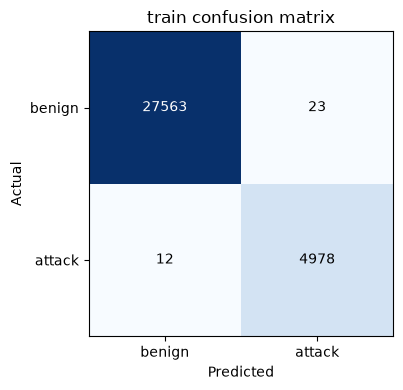

Saved: G:\My Drive\nids-capstone\data\ait\processed\figures\confusion_matrix_train.png

=== val ===
              precision    recall  f1-score   support

      benign      0.998     0.999     0.998     14308
      attack      0.991     0.988     0.989      2026

    accuracy                          0.997     16334
   macro avg      0.995     0.993     0.994     16334
weighted avg      0.997     0.997     0.997     16334



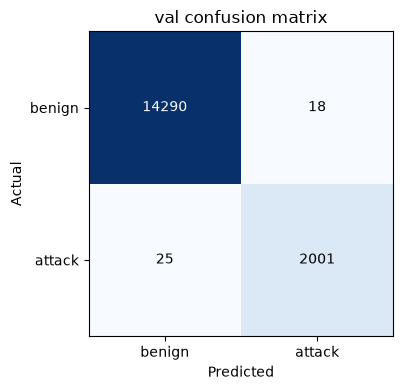

Saved: G:\My Drive\nids-capstone\data\ait\processed\figures\confusion_matrix_val.png

=== test ===
              precision    recall  f1-score   support

      benign      1.000     0.996     0.998     17751
      attack      0.977     0.999     0.988      2821

    accuracy                          0.997     20572
   macro avg      0.988     0.997     0.993     20572
weighted avg      0.997     0.997     0.997     20572



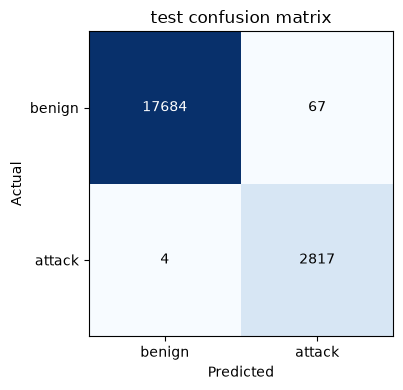

Saved: G:\My Drive\nids-capstone\data\ait\processed\figures\confusion_matrix_test.png


In [7]:
def get_predictions(model, graphs):
    model.eval()
    all_logits, all_y, all_active = [], [], []

    with torch.no_grad():
        for g in graphs:
            g = g.to(DEVICE)
            logits = model(g.x, g.edge_index, g.edge_attr)

            all_logits.append(logits.cpu())
            all_y.append(g.y.cpu())
            all_active.append(g.active.cpu())

    logits = torch.cat(all_logits)
    y = torch.cat(all_y)
    active = torch.cat(all_active)

    probs = torch.sigmoid(logits)

    return probs.numpy(), y.numpy(), active.numpy().astype(bool)


# ============================================================
# CONFUSION MATRICES - SAVE EACH SPLIT AS A SEPARATE IMAGE
# ============================================================

for split in ['train', 'val', 'test']:

    if not all_graphs[split]:
        print(f'\n=== {split} === (no graphs in this split -- skipping)')
        continue

    # Get predictions
    probs, y, active = get_predictions(
        final_model,
        all_graphs[split]
    )

    yt = y[active]
    yp_prob = probs[active]
    yp = (yp_prob > 0.5).astype(int)

    # Classification report
    print(f'\n=== {split} ===')

    print(
        classification_report(
            yt,
            yp,
            target_names=['benign', 'attack'],
            digits=3,
            zero_division=0
        )
    )

    # Confusion matrix
    cm = confusion_matrix(yt, yp)

    # --------------------------------------------------------
    # Create ONE figure for this split
    # --------------------------------------------------------
    fig, ax = plt.subplots(
        figsize=(5, 4)
    )

    # Same original aesthetics
    im = ax.imshow(
        cm,
        cmap='Blues'
    )

    ax.set_title(
        f'{split} confusion matrix'
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(
        ['benign', 'attack']
    )

    ax.set_yticks([0, 1])
    ax.set_yticklabels(
        ['benign', 'attack']
    )

    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

    # Numbers inside cells
    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha='center',
                va='center',
                color='white'
                if cm[i, j] > cm.max() / 2
                else 'black'
            )

    plt.tight_layout()

    # --------------------------------------------------------
    # Save each matrix separately
    # --------------------------------------------------------
    filename = os.path.join(
        FIG_DIR,
        f'confusion_matrix_{split}.png'
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close()

    print(f'Saved: {filename}')

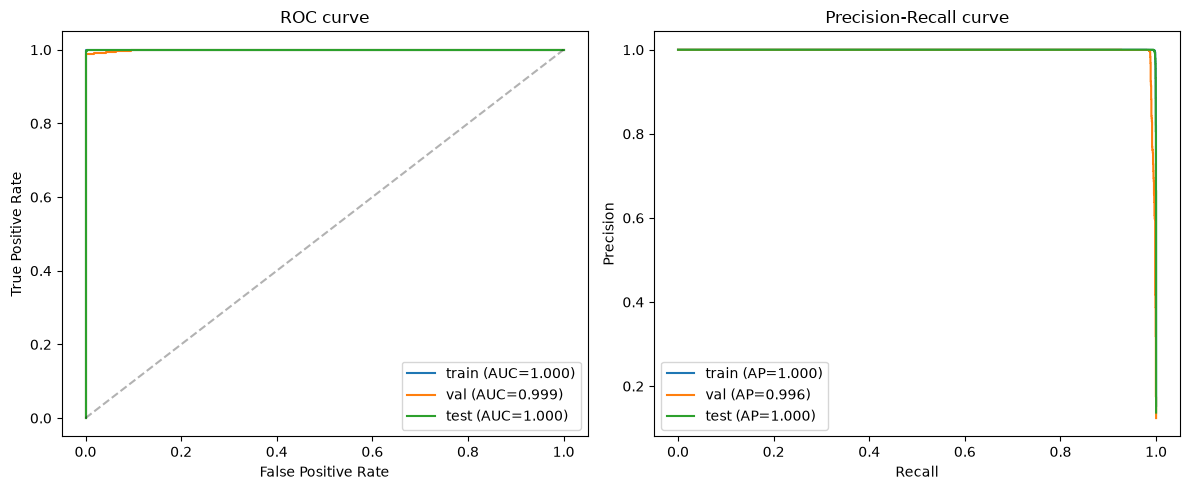

Saved roc_pr_curves.png

Note: these curves are dominated by the exfiltration period (>95% of active nodes),
so a near-1.0 AUC here reflects that easy majority case -- report chain-period numbers
(the bar chart in the next cell) for the result that actually tests generalization.


In [179]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for split, color in zip(['train', 'val', 'test'], ['C0', 'C1', 'C2']):
    if not all_graphs[split]:
        continue
    probs, y, active = get_predictions(final_model, all_graphs[split])
    yt, yp_prob = y[active], probs[active]

    fpr, tpr, _ = roc_curve(yt, yp_prob)
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=color, label=f'{split} (AUC={roc_auc:.3f})')

    prec, rec, _ = precision_recall_curve(yt, yp_prob)
    ap = average_precision_score(yt, yp_prob)
    axes[1].plot(rec, prec, color=color, label=f'{split} (AP={ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',alpha=0.3)
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC curve'); axes[0].legend()

axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall curve'); axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'roc_pr_curves.png'), dpi=150)
plt.show()
print('Saved roc_pr_curves.png')
print('\nNote: these curves are dominated by the exfiltration period (>95% of active nodes),')
print('so a near-1.0 AUC here reflects that easy majority case -- report chain-period numbers')
print('(the bar chart in the next cell) for the result that actually tests generalization.')

                 model    f1  recall  precision  n_pos
host_identity_baseline 0.513   1.000      0.345     30
             flow_only 0.885   0.900      0.871     30
              log_only 0.476   0.333      0.833     30
            multimodal 0.828   0.800      0.857     30
          gated_fusion 0.821   0.767      0.885     30
             edge_sage 0.881   0.867      0.897     30


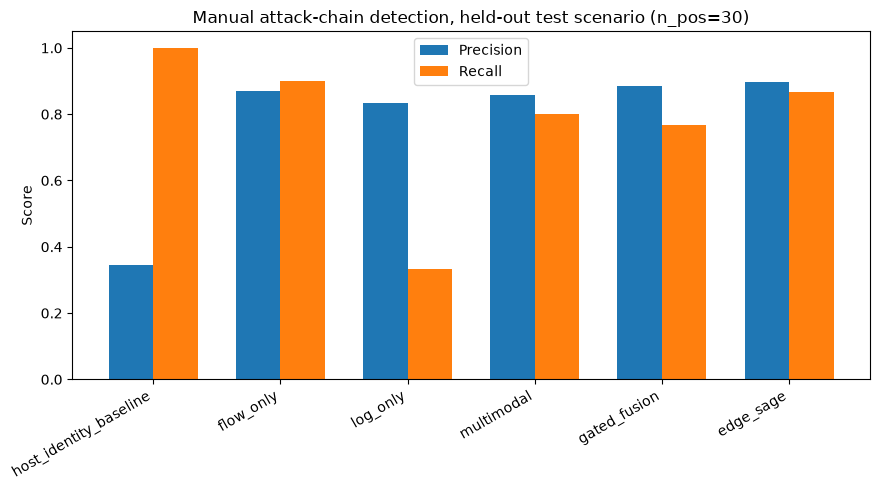


Saved chain_period_comparison.png


In [180]:
report_files = {
    'host_identity_baseline': 'phase5_evaluation_report.csv',
    'flow_only': 'phase6_ablation_report.csv',
    'log_only': 'phase6_ablation_report.csv',
    'multimodal': 'phase6_ablation_report.csv',
    'gated_fusion': 'phase9_gated_fusion_report.csv',
    'edge_sage': 'phase10_edge_sage_report.csv',
}

rows = []
for model_name, fname in report_files.items():
    path = os.path.join(OUT_DIR, fname)
    if not os.path.isfile(path):
        print(f'Skipping {model_name} -- {fname} not found')
        continue
    df = pd.read_csv(path)
    sub = df[(df.model == model_name) & (df.split == 'test') & (df.period == 'chain')]
    if len(sub):
        rows.append(dict(model=model_name, f1=sub.iloc[0].f1, recall=sub.iloc[0].recall,
                          precision=sub.iloc[0].precision, n_pos=int(sub.iloc[0].n_pos)))

chain_comparison = pd.DataFrame(rows)
print(chain_comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(chain_comparison))
width = 0.35
ax.bar(x - width/2, chain_comparison.precision, width, label='Precision')
ax.bar(x + width/2, chain_comparison.recall, width, label='Recall')
ax.set_xticks(x)
ax.set_xticklabels(chain_comparison.model, rotation=30, ha='right')
ax.set_ylabel('Score')
ax.set_title(f'Manual attack-chain detection, held-out test scenario (n_pos={chain_comparison.n_pos.iloc[-1]})')
ax.legend()
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'chain_period_comparison.png'), dpi=150)
plt.show()
print('\nSaved chain_period_comparison.png')

Saliency computed over 30 true-positive chain-period nodes in test

Top 15 most influential features:
  apache_denied_count             mean|saliency| = 10.1075
  apache_4xx_count                mean|saliency| = 3.7768
  out_flow_count                  mean|saliency| = 3.0436
  apache_error_count              mean|saliency| = 2.6772
  total_pkts                      mean|saliency| = 2.6359
  in_flow_count                   mean|saliency| = 1.2801
  avg_duration                    mean|saliency| = 1.0334
  flow_active                     mean|saliency| = 0.9367
  count_apache_error              mean|saliency| = 0.8419
  dns_max_entropy                 mean|saliency| = 0.7493
  n_distinct_peers                mean|saliency| = 0.7430
  has_log_source                  mean|saliency| = 0.6975
  dns_max_domain_length           mean|saliency| = 0.6039
  apache_request_count            mean|saliency| = 0.5606
  count_auth                      mean|saliency| = 0.5375


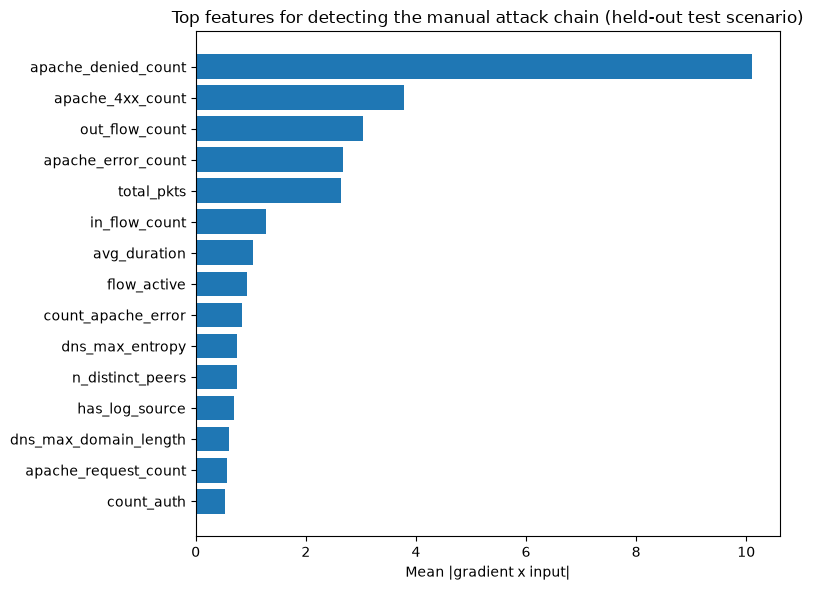


Saved feature_saliency.png


In [181]:
def saliency_for_node(model, graph, node_idx):
    model.eval()
    x = graph.x.clone().to(DEVICE).requires_grad_(True)
    edge_index = graph.edge_index.to(DEVICE)
    edge_attr = graph.edge_attr.to(DEVICE)
    logits = model(x, edge_index, edge_attr)
    logits[node_idx].backward()
    saliency = (x.grad[node_idx] * x[node_idx]).detach().cpu().numpy()
    return saliency

EXFIL_LABELS = {'data exfiltration', 'attacker', 'dnsteal', 'dnsteal-received'}
def is_chain_window(sc, wid):
    lt = dataset['scenarios'][sc]['label_table']
    row_labels = lt[lt.window_id == wid]['labels']
    all_labels = set(l for labs in row_labels for l in labs)
    return len(all_labels - EXFIL_LABELS) > 0

chain_tp_saliencies = []
for g in all_graphs['test']:
    if not is_chain_window(g.scenario, g.window_id):
        continue
    y = g.y.cpu().numpy().astype(bool)
    active = g.active.cpu().numpy().astype(bool)
    with torch.no_grad():
        probs = torch.sigmoid(final_model(g.x.to(DEVICE), g.edge_index.to(DEVICE), g.edge_attr.to(DEVICE))).cpu().numpy()
    tp_nodes = np.flatnonzero(active & y & (probs > 0.5))
    for node_idx in tp_nodes:
        chain_tp_saliencies.append(saliency_for_node(final_model, g, node_idx))

if chain_tp_saliencies:
    sal_matrix = np.stack(chain_tp_saliencies)
    mean_abs_saliency = np.abs(sal_matrix).mean(axis=0)
    top_idx = np.argsort(mean_abs_saliency)[::-1][:15]

    print(f'Saliency computed over {len(chain_tp_saliencies)} true-positive chain-period nodes in test\n')
    print('Top 15 most influential features:')
    for i in top_idx:
        print(f'  {ALL_FEATURE_NAMES[i]:30s}  mean|saliency| = {mean_abs_saliency[i]:.4f}')

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh([ALL_FEATURE_NAMES[i] for i in top_idx][::-1], mean_abs_saliency[top_idx][::-1])
    ax.set_xlabel('Mean |gradient x input|')
    ax.set_title('Top features for detecting the manual attack chain (held-out test scenario)')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, 'feature_saliency.png'), dpi=150)
    plt.show()
    print('\nSaved feature_saliency.png')
else:
    print('No true-positive chain-period nodes found in test to explain -- check the model/data.')

In [182]:
all_reports = []
for fname in ['phase5_evaluation_report.csv', 'phase6_ablation_report.csv',
              'phase7_final_report.csv', 'phase9_gated_fusion_report.csv',
              'phase10_edge_sage_report.csv']:
    path = os.path.join(OUT_DIR, fname)
    if os.path.isfile(path):
        df = pd.read_csv(path)
        df['source'] = fname
        all_reports.append(df)

final_summary = pd.concat(all_reports, ignore_index=True)
final_summary.to_csv(os.path.join(OUT_DIR, 'final_results_summary.csv'), index=False)
print(f'Saved final_results_summary.csv -- {len(final_summary)} rows across {len(all_reports)} report files')
print('\nModels included:', sorted(final_summary.model.unique()))
print('\nFigures saved to:', FIG_DIR)

Saved final_results_summary.csv -- 81 rows across 5 report files

Models included: ['edge_sage', 'flow_only', 'gated_fusion', 'host_identity_baseline', 'hpo_tuned_flow_only', 'log_only', 'main_model', 'multimodal']

Figures saved to: G:\My Drive\nids-capstone\data\ait\processed\figures


## Phase 9

In [155]:
import os, pickle, collections
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv
from sklearn.metrics import precision_recall_fscore_support

OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

import random
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

with open(os.path.join(OUT_DIR, f'multi_scenario_graph_dataset_w{WINDOW_MINUTES}m.pkl'), 'rb') as f:
    dataset = pickle.load(f)

EXFIL_LABELS = {'data exfiltration', 'attacker', 'dnsteal', 'dnsteal-received'}
CHAIN_LABELS = {
    'service_scan', 'dirb_scan', 'wpscan', 'dns_brute_force_start', 'host_discover_dmz',
    'host_discover_local', 'online_cracking', 'upload_rce_shell', 'dump_wp_users',
    'check_whoami', 'check_uname_r', 'read_profile', 'check_who', 'check_meminfo', 'check_uname_a',
    'check_user_id', 'check_df', 'check_netstat_nat', 'check_id', 'read_resolv', 'check_netstat_t',
    'list_home', 'check_last', 'list_web_dir', 'check_date', 'list_www', 'check_netstat_l', 'clear',
    'check_wp_config', 'check_ps_a', 'read_passwd', 'check_release', 'check_cpuinfo', 'read_group',
    'check_uptime', 'check_network_config', 'update/command on unassigned port', 'check_pwd', 'list_l',
    'attacker_change_user',
    'escalate',
    'escalated_command',
    'escalated_sudo_command',
    'escalated_sudo_session',
}

def window_periods(scen):
    lt = scen['label_table']
    has_chain = lt['labels'].apply(lambda labs: any(l in CHAIN_LABELS for l in labs))
    has_exfil = lt['labels'].apply(lambda labs: any(l in EXFIL_LABELS for l in labs))
    chain_windows = set(lt.loc[has_chain, 'window_id'].astype(int))
    exfil_windows = set(lt.loc[has_exfil, 'window_id'].astype(int)) - chain_windows
    periods = {}
    for w in scen['window_ids']:
        w = int(w)
        periods[w] = 'chain' if w in chain_windows else ('exfil' if w in exfil_windows else 'clean')
    return periods

scenario_periods = {sc: window_periods(scen) for sc, scen in dataset['scenarios'].items()}

def build_graphs_twotower(scenario_name):
    scen = dataset['scenarios'][scenario_name]
    graphs = []
    for i, w in enumerate(scen['window_ids']):
        edge_index_np, edge_attr_np = scen['edges'][i]
        data = Data(
            x_flow=torch.tensor(scen['X_flow'][i], dtype=torch.float32),
            x_log=torch.tensor(scen['X_log'][i], dtype=torch.float32),
            x_emb=torch.tensor(scen['X_emb'][i], dtype=torch.float32),
            edge_index=torch.tensor(edge_index_np, dtype=torch.long),
            edge_attr=torch.tensor(edge_attr_np, dtype=torch.float32),
            y=torch.tensor(scen['y'][i], dtype=torch.float32),
            active=torch.tensor(scen['active'][i], dtype=torch.bool),
            log_active=torch.tensor(scen['log_active'][i], dtype=torch.float32),
            num_nodes=scen['X_flow'][i].shape[0],
        )
        data.scenario = scenario_name
        data.window_id = int(w)
        graphs.append(data)
    return graphs

all_graphs = {'train': [], 'val': [], 'test': []}
for sc, scen in dataset['scenarios'].items():
    all_graphs[scen['split']] += build_graphs_twotower(sc)

FLOW_DIM = all_graphs['train'][0].x_flow.shape[1]
LOG_DIM = all_graphs['train'][0].x_log.shape[1] + all_graphs['train'][0].x_emb.shape[1]
print({k: len(v) for k, v in all_graphs.items()}, '| flow_dim', FLOW_DIM, '| log_dim', LOG_DIM)

Device: cuda
{'train': 2592, 'val': 1152, 'test': 1439} | flow_dim 10 | log_dim 402


In [156]:
class GraphSAGEEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, out_dim)
    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        return self.conv2(h, edge_index)

class GraphMAE(nn.Module):
    def __init__(self, in_dim, hidden_dim, embed_dim):
        super().__init__()
        self.mask_token = nn.Parameter(torch.zeros(in_dim))
        self.remask_token = nn.Parameter(torch.zeros(embed_dim))
        self.encoder = GraphSAGEEncoder(in_dim, hidden_dim, embed_dim)
        self.decoder = SAGEConv(embed_dim, in_dim)

    def forward(self, x, edge_index, active, mask_rate=0.5, gamma=2.0):
        active_idx = active.nonzero(as_tuple=True)[0]
        if len(active_idx) < 2:
            return None, None
        n_mask = max(1, int(len(active_idx) * mask_rate))
        perm = active_idx[torch.randperm(len(active_idx), device=x.device)]
        mask_idx = perm[:n_mask]

        x_corrupt = x.clone()
        x_corrupt[mask_idx] = self.mask_token
        h = self.encoder(x_corrupt, edge_index)
        h_remask = h.clone()
        h_remask[mask_idx] = self.remask_token
        recon = self.decoder(h_remask, edge_index)

        target, pred = x[mask_idx], recon[mask_idx]
        cos = F.cosine_similarity(pred, target, dim=-1).clamp(-1 + 1e-7, 1 - 1e-7)
        loss = ((1 - cos) ** gamma).mean()
        return loss, h

def pretrain_tower(get_x_fn, get_active_fn, in_dim, hidden_dim, embed_dim, tag, n_epochs=30):
    model = GraphMAE(in_dim, hidden_dim, embed_dim).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(all_graphs['train'], batch_size=32, shuffle=True)
    history = []
    for epoch in range(n_epochs):
        model.train()
        total_loss, n_batches = 0.0, 0
        for batch in loader:
            batch = batch.to(DEVICE)
            x = get_x_fn(batch)
            active = get_active_fn(batch)
            if active.sum() < 2:
                continue
            opt.zero_grad()
            loss, _ = model(x, batch.edge_index, active)
            if loss is None:
                continue
            loss.backward()
            opt.step()
            total_loss += loss.item()
            n_batches += 1
        avg = total_loss / max(n_batches, 1)
        history.append(avg)
        if epoch % 5 == 0 or epoch == n_epochs - 1:
            print(f'[{tag}] epoch {epoch:3d}  recon loss {avg:.4f}')
    print(f'[{tag}] loss {history[0]:.4f} -> {history[-1]:.4f}')
    return model

print('=== Pretraining FLOW tower ===')
flow_mae = pretrain_tower(
    get_x_fn=lambda b: b.x_flow, get_active_fn=lambda b: b.active,
    in_dim=FLOW_DIM, hidden_dim=128, embed_dim=128, tag='flow')

print('\n=== Pretraining LOG tower ===')
log_mae = pretrain_tower(
    get_x_fn=lambda b: torch.cat([b.x_log, b.x_emb], dim=-1), get_active_fn=lambda b: b.active,
    in_dim=LOG_DIM, hidden_dim=128, embed_dim=128, tag='log')

=== Pretraining FLOW tower ===
[flow] epoch   0  recon loss 0.2878
[flow] epoch   5  recon loss 0.2126
[flow] epoch  10  recon loss 0.2108
[flow] epoch  15  recon loss 0.2126
[flow] epoch  20  recon loss 0.2094
[flow] epoch  25  recon loss 0.2126
[flow] epoch  29  recon loss 0.2079
[flow] loss 0.2878 -> 0.2079

=== Pretraining LOG tower ===
[log] epoch   0  recon loss 0.5643
[log] epoch   5  recon loss 0.4320
[log] epoch  10  recon loss 0.4273
[log] epoch  15  recon loss 0.4333
[log] epoch  20  recon loss 0.4252
[log] epoch  25  recon loss 0.4285
[log] epoch  29  recon loss 0.4290
[log] loss 0.5643 -> 0.4290


In [157]:
class GatedFusionClassifier(nn.Module):
    def __init__(self, flow_dim, log_dim, hidden_dim, embed_dim, flow_state=None, log_state=None):
        super().__init__()
        self.flow_encoder = GraphSAGEEncoder(flow_dim, hidden_dim, embed_dim)
        self.log_encoder = GraphSAGEEncoder(log_dim, hidden_dim, embed_dim)
        if flow_state is not None: self.flow_encoder.load_state_dict(flow_state)
        if log_state is not None: self.log_encoder.load_state_dict(log_state)

        self.gate = nn.Sequential(nn.Linear(embed_dim * 2 + 1, 32), nn.ReLU(), nn.Linear(32, 1))
        self.head = nn.Sequential(nn.Linear(embed_dim, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x_flow, x_log, edge_index, log_active):
        h_flow = self.flow_encoder(x_flow, edge_index)
        h_log = self.log_encoder(x_log, edge_index)
        g = torch.sigmoid(self.gate(torch.cat([h_flow, h_log, log_active.unsqueeze(-1)], dim=-1)))
        h_fused = g * h_log + (1 - g) * h_flow
        return self.head(h_fused).squeeze(-1), g.squeeze(-1)

In [158]:
def pos_weight_for(graphs):
    y_all = torch.cat([g.y[g.active] for g in graphs])
    pos = y_all.sum().item()
    neg = len(y_all) - pos
    return torch.tensor([neg / max(pos, 1)], device=DEVICE)

def get_log_x(batch):
    return torch.cat([batch.x_log, batch.x_emb], dim=-1)

def evaluate_logits(model, graphs):
    model.eval()
    all_logits, all_y, all_active, all_scenario, all_window, all_gate = [], [], [], [], [], []
    with torch.no_grad():
        for g in graphs:
            g = g.to(DEVICE)
            logits, gate = model(g.x_flow, get_log_x(g), g.edge_index, g.log_active)
            all_logits.append(logits.cpu())
            all_gate.append(gate.cpu())
            all_y.append(g.y.cpu())
            all_active.append(g.active.cpu())
            all_scenario += [g.scenario] * g.x_flow.shape[0]
            all_window += [g.window_id] * g.x_flow.shape[0]
    return (torch.cat(all_logits), torch.cat(all_y), torch.cat(all_active),
            np.array(all_scenario), np.array(all_window), torch.cat(all_gate))

def period_macro_f1(model, graphs):
    logits, y, active, scenario, window, _ = evaluate_logits(model, graphs)
    pred = (logits > 0).float()
    f1s = []
    for period in ['exfil', 'chain']:
        mask = active.numpy().astype(bool).copy()
        period_mask = np.zeros(len(mask), dtype=bool)
        for sc in set(scenario):
            sc_mask = scenario == sc
            p_lookup = scenario_periods.get(sc, {})
            this_period = np.array([p_lookup.get(int(w), 'clean') == period for w in window[sc_mask]])
            period_mask[sc_mask] = this_period
        m = mask & period_mask
        if m.sum() == 0:
            continue
        yt, yp = y.numpy()[m], pred.numpy()[m]
        if yt.sum() == 0 and yp.sum() == 0:
            f1 = 1.0
        else:
            _, _, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
        f1s.append(f1)
    return float(np.mean(f1s)) if f1s else 0.0

def train_model(model, train_graphs, val_graphs, n_epochs=40, lr=1e-3, patience=8, tag=''):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_for(train_graphs))
    loader = DataLoader(train_graphs, batch_size=32, shuffle=True)

    best_val_f1, best_state, bad_epochs = -1, None, 0
    for epoch in range(n_epochs):
        model.train()
        total_loss = 0.0
        for batch in loader:
            batch = batch.to(DEVICE)
            if batch.active.sum() == 0:
                continue
            opt.zero_grad()
            logits, _ = model(batch.x_flow, get_log_x(batch), batch.edge_index, batch.log_active)
            loss = loss_fn(logits[batch.active], batch.y[batch.active])
            loss.backward()
            opt.step()
            total_loss += loss.item()

        f1 = period_macro_f1(model, val_graphs)
        if epoch % 5 == 0 or epoch == n_epochs - 1:
            print(f'[{tag}] epoch {epoch:3d}  train_loss {total_loss/len(loader):.4f}  val_macro_f1 {f1:.4f}')

        if f1 > best_val_f1:
            best_val_f1, best_state, bad_epochs = f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f'[{tag}] early stopping at epoch {epoch} (best val_macro_f1={best_val_f1:.4f})')
                break

    model.load_state_dict(best_state)
    return model

gated_model = GatedFusionClassifier(FLOW_DIM, LOG_DIM, 128, 128,
                                     flow_state=flow_mae.encoder.state_dict(),
                                     log_state=log_mae.encoder.state_dict())
gated_model = train_model(gated_model, all_graphs['train'], all_graphs['val'], tag='gated_fusion')

[gated_fusion] epoch   0  train_loss 0.2573  val_macro_f1 0.5931
[gated_fusion] epoch   5  train_loss 0.0221  val_macro_f1 0.7192
[gated_fusion] epoch  10  train_loss 0.0147  val_macro_f1 0.6683
[gated_fusion] early stopping at epoch 13 (best val_macro_f1=0.7192)


In [159]:
def report(model, graphs_by_split, label):
    rows = []
    for split, gs in graphs_by_split.items():
        logits, y, active, scenario, window, gate = evaluate_logits(model, gs)
        pred = (logits > 0).float()
        for period in ['exfil', 'chain', 'clean']:
            mask = active.numpy().astype(bool).copy()
            period_mask = np.zeros(len(mask), dtype=bool)
            for sc in set(scenario):
                sc_mask = scenario == sc
                p_lookup = scenario_periods.get(sc, {})
                this_period = np.array([p_lookup.get(int(w), 'clean') == period for w in window[sc_mask]])
                period_mask[sc_mask] = this_period
            m = mask & period_mask
            if m.sum() == 0:
                continue
            yt, yp = y.numpy()[m], pred.numpy()[m]
            if yt.sum() == 0 and yp.sum() == 0:
                prec = rec = f1 = 1.0
            else:
                prec, rec, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
            fp = int(((yp == 1) & (yt == 0)).sum())
            n_neg = int((yt == 0).sum())
            rows.append(dict(model=label, split=split, period=period, n=int(m.sum()),
                              n_pos=int(yt.sum()), precision=round(prec,3), recall=round(rec,3),
                              f1=round(f1,3), fpr=round(fp/max(n_neg,1), 4),
                              mean_gate=round(float(gate.numpy()[m].mean()), 3)))
    return pd.DataFrame(rows)

gated_report = report(gated_model, all_graphs, 'gated_fusion')
print(gated_report.to_string(index=False))

try:
    prior = pd.read_csv(os.path.join(OUT_DIR, 'phase6_ablation_report.csv'))
    compare_cols = ['model','split','period','n','n_pos','precision','recall','f1','fpr']
    combined = pd.concat([prior[compare_cols], gated_report[compare_cols]], ignore_index=True)
    print('\n--- chain period, all models ---')
    print(combined[combined.period == 'chain'].to_string(index=False))
except FileNotFoundError:
    pass

       model split period     n  n_pos  precision  recall    f1    fpr  mean_gate
gated_fusion train  exfil 21680   4916      0.989   1.000 0.994 0.0033      0.366
gated_fusion train  chain   241     74      0.953   0.824 0.884 0.0180      0.299
gated_fusion train  clean 10655      0      0.000   0.000 0.000 0.0060      0.335
gated_fusion   val  exfil  9307   1993      0.989   0.999 0.994 0.0031      0.336
gated_fusion   val  chain   168     33      0.833   0.303 0.444 0.0148      0.285
gated_fusion   val  clean  6859      0      0.000   0.000 0.000 0.0032      0.306
gated_fusion  test  exfil 13287   2791      0.977   1.000 0.988 0.0062      0.367
gated_fusion  test  chain    87     30      0.885   0.767 0.821 0.0526      0.323
gated_fusion  test  clean  7198      0      0.000   0.000 0.000 0.0172      0.334

--- chain period, all models ---
                 model split period   n  n_pos  precision  recall    f1    fpr
host_identity_baseline train  chain 241     74      0.291   0.581 0

In [176]:
torch.save(gated_model.state_dict(), os.path.join(OUT_DIR, 'gated_fusion_model.pt'))
gated_report.to_csv(os.path.join(OUT_DIR, 'phase9_gated_fusion_report.csv'), index=False)
print('Saved gated fusion model and report to', OUT_DIR)

Saved gated fusion model and report to G:\My Drive\nids-capstone\data\ait\processed


## Phase 10

In [160]:
import os, pickle, collections
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import MessagePassing
from sklearn.metrics import precision_recall_fscore_support
 
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
 
import random
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
 
with open(os.path.join(OUT_DIR, f'multi_scenario_graph_dataset_w{WINDOW_MINUTES}m.pkl'), 'rb') as f:
    dataset = pickle.load(f)
 
EXFIL_LABELS = {'data exfiltration', 'attacker', 'dnsteal', 'dnsteal-received'}
CHAIN_LABELS = {
    'service_scan', 'dirb_scan', 'wpscan', 'dns_brute_force_start', 'host_discover_dmz',
    'host_discover_local', 'online_cracking', 'upload_rce_shell', 'dump_wp_users',
    'check_whoami', 'check_uname_r', 'read_profile', 'check_who', 'check_meminfo', 'check_uname_a',
    'check_user_id', 'check_df', 'check_netstat_nat', 'check_id', 'read_resolv', 'check_netstat_t',
    'list_home', 'check_last', 'list_web_dir', 'check_date', 'list_www', 'check_netstat_l', 'clear',
    'check_wp_config', 'check_ps_a', 'read_passwd', 'check_release', 'check_cpuinfo', 'read_group',
    'check_uptime', 'check_network_config', 'update/command on unassigned port', 'check_pwd', 'list_l',
    'attacker_change_user',
    'escalate',
    'escalated_command',
    'escalated_sudo_command',
    'escalated_sudo_session',
}
 
def window_periods(scen):
    lt = scen['label_table']
    has_chain = lt['labels'].apply(lambda labs: any(l in CHAIN_LABELS for l in labs))
    has_exfil = lt['labels'].apply(lambda labs: any(l in EXFIL_LABELS for l in labs))
    chain_windows = set(lt.loc[has_chain, 'window_id'].astype(int))
    exfil_windows = set(lt.loc[has_exfil, 'window_id'].astype(int)) - chain_windows
    periods = {}
    for w in scen['window_ids']:
        w = int(w)
        periods[w] = 'chain' if w in chain_windows else ('exfil' if w in exfil_windows else 'clean')
    return periods
 
scenario_periods = {sc: window_periods(scen) for sc, scen in dataset['scenarios'].items()}
 
def build_graphs(scenario_name):
    scen = dataset['scenarios'][scenario_name]
    X = np.concatenate([scen['X_flow'], scen['X_log'], scen['X_emb']], axis=-1)
    graphs = []
    for i, w in enumerate(scen['window_ids']):
        edge_index_np, edge_attr_np = scen['edges'][i]
        data = Data(
            x=torch.tensor(X[i], dtype=torch.float32),
            edge_index=torch.tensor(edge_index_np, dtype=torch.long),
            edge_attr=torch.tensor(edge_attr_np, dtype=torch.float32),
            y=torch.tensor(scen['y'][i], dtype=torch.float32),
            active=torch.tensor(scen['active'][i], dtype=torch.bool),
            num_nodes=X[i].shape[0],
        )
        data.scenario = scenario_name
        data.window_id = int(w)
        graphs.append(data)
    return graphs
 
all_graphs = {'train': [], 'val': [], 'test': []}
for sc, scen in dataset['scenarios'].items():
    all_graphs[scen['split']] += build_graphs(sc)
 
FEATURE_DIM = all_graphs['train'][0].x.shape[1]
EDGE_DIM = all_graphs['train'][0].edge_attr.shape[1]
print({k: len(v) for k, v in all_graphs.items()}, '| feature dim', FEATURE_DIM, '| edge dim', EDGE_DIM)

Device: cuda
{'train': 2592, 'val': 1152, 'test': 1439} | feature dim 412 | edge dim 5


In [161]:
class EdgeSAGEConv(MessagePassing):
    """GraphSAGE's mean-aggregation + self-term structure, extended so each neighbor's message
    is conditioned on the edge connecting it (the standard edge-conditioned message-passing
    pattern) instead of ignoring edge_attr entirely, which is what every encoder up to this
    point has done."""
    def __init__(self, in_channels, edge_dim, out_channels):
        super().__init__(aggr='mean')
        self.lin_msg = nn.Linear(in_channels + edge_dim, out_channels)
        self.lin_root = nn.Linear(in_channels, out_channels)
    def forward(self, x, edge_index, edge_attr):
        out = self.propagate(edge_index, x=x, edge_attr=edge_attr)
        return out + self.lin_root(x)
    def message(self, x_j, edge_attr):
        return F.relu(self.lin_msg(torch.cat([x_j, edge_attr], dim=-1)))
 
class EdgeSAGEEncoder(nn.Module):
    def __init__(self, in_dim, edge_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = EdgeSAGEConv(in_dim, edge_dim, hidden_dim)
        self.conv2 = EdgeSAGEConv(hidden_dim, edge_dim, out_dim)
    def forward(self, x, edge_index, edge_attr):
        h = F.relu(self.conv1(x, edge_index, edge_attr))
        return self.conv2(h, edge_index, edge_attr)
 
class EdgeGraphMAE(nn.Module):
    def __init__(self, in_dim, edge_dim, hidden_dim, embed_dim):
        super().__init__()
        self.mask_token = nn.Parameter(torch.zeros(in_dim))
        self.remask_token = nn.Parameter(torch.zeros(embed_dim))
        self.encoder = EdgeSAGEEncoder(in_dim, edge_dim, hidden_dim, embed_dim)
        self.decoder = EdgeSAGEConv(embed_dim, edge_dim, in_dim)
 
    def forward(self, x, edge_index, edge_attr, active, mask_rate=0.5, gamma=2.0):
        active_idx = active.nonzero(as_tuple=True)[0]
        if len(active_idx) < 2:
            return None, None
        n_mask = max(1, int(len(active_idx) * mask_rate))
        perm = active_idx[torch.randperm(len(active_idx), device=x.device)]
        mask_idx = perm[:n_mask]
 
        x_corrupt = x.clone()
        x_corrupt[mask_idx] = self.mask_token
        h = self.encoder(x_corrupt, edge_index, edge_attr)
        h_remask = h.clone()
        h_remask[mask_idx] = self.remask_token
        recon = self.decoder(h_remask, edge_index, edge_attr)
 
        target, pred = x[mask_idx], recon[mask_idx]
        cos = F.cosine_similarity(pred, target, dim=-1).clamp(-1 + 1e-7, 1 - 1e-7)
        loss = ((1 - cos) ** gamma).mean()
        return loss, h
 
mae = EdgeGraphMAE(FEATURE_DIM, EDGE_DIM, 128, 128).to(DEVICE)
opt = torch.optim.Adam(mae.parameters(), lr=1e-3)
loader = DataLoader(all_graphs['train'], batch_size=32, shuffle=True)
 
N_EPOCHS = 30
history = []
for epoch in range(N_EPOCHS):
    mae.train()
    total_loss, n_batches = 0.0, 0
    for batch in loader:
        batch = batch.to(DEVICE)
        if batch.active.sum() < 2:
            continue
        opt.zero_grad()
        loss, _ = mae(batch.x, batch.edge_index, batch.edge_attr, batch.active)
        if loss is None:
            continue
        loss.backward()
        opt.step()
        total_loss += loss.item()
        n_batches += 1
    avg = total_loss / max(n_batches, 1)
    history.append(avg)
    if epoch % 5 == 0 or epoch == N_EPOCHS - 1:
        print(f'epoch {epoch:3d}  recon loss {avg:.4f}')
print('loss', history[0], '->', history[-1])


epoch   0  recon loss 0.4025
epoch   5  recon loss 0.1504
epoch  10  recon loss 0.1458
epoch  15  recon loss 0.1432
epoch  20  recon loss 0.1445
epoch  25  recon loss 0.1422
epoch  29  recon loss 0.1417
loss 0.40248310933878395 -> 0.1417442896851787


In [162]:
class EdgeNIDSClassifier(nn.Module):
    def __init__(self, in_dim, edge_dim, hidden_dim, embed_dim, pretrained_state=None):
        super().__init__()
        self.encoder = EdgeSAGEEncoder(in_dim, edge_dim, hidden_dim, embed_dim)
        if pretrained_state is not None:
            self.encoder.load_state_dict(pretrained_state)
        self.head = nn.Sequential(nn.Linear(embed_dim, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x, edge_index, edge_attr):
        h = self.encoder(x, edge_index, edge_attr)
        return self.head(h).squeeze(-1)


In [163]:
def pos_weight_for(graphs):
    y_all = torch.cat([g.y[g.active] for g in graphs])
    pos = y_all.sum().item()
    neg = len(y_all) - pos
    return torch.tensor([neg / max(pos, 1)], device=DEVICE)
 
def evaluate_logits(model, graphs):
    model.eval()
    all_logits, all_y, all_active, all_scenario, all_window = [], [], [], [], []
    with torch.no_grad():
        for g in graphs:
            g = g.to(DEVICE)
            logits = model(g.x, g.edge_index, g.edge_attr)
            all_logits.append(logits.cpu())
            all_y.append(g.y.cpu())
            all_active.append(g.active.cpu())
            all_scenario += [g.scenario] * g.x.shape[0]
            all_window += [g.window_id] * g.x.shape[0]
    return (torch.cat(all_logits), torch.cat(all_y), torch.cat(all_active),
            np.array(all_scenario), np.array(all_window))
 
def period_macro_f1(model, graphs):
    logits, y, active, scenario, window = evaluate_logits(model, graphs)
    pred = (logits > 0).float()
    f1s = []
    for period in ['exfil', 'chain']:
        mask = active.numpy().astype(bool).copy()
        period_mask = np.zeros(len(mask), dtype=bool)
        for sc in set(scenario):
            sc_mask = scenario == sc
            p_lookup = scenario_periods.get(sc, {})
            this_period = np.array([p_lookup.get(int(w), 'clean') == period for w in window[sc_mask]])
            period_mask[sc_mask] = this_period
        m = mask & period_mask
        if m.sum() == 0:
            continue
        yt, yp = y.numpy()[m], pred.numpy()[m]
        if yt.sum() == 0 and yp.sum() == 0:
            f1 = 1.0
        else:
            _, _, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
        f1s.append(f1)
    return float(np.mean(f1s)) if f1s else 0.0
 
def train_model(model, train_graphs, val_graphs, n_epochs=40, lr=1e-3, patience=8, tag=''):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_for(train_graphs))
    loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
 
    best_val_f1, best_state, bad_epochs = -1, None, 0
    for epoch in range(n_epochs):
        model.train()
        total_loss = 0.0
        for batch in loader:
            batch = batch.to(DEVICE)
            if batch.active.sum() == 0:
                continue
            opt.zero_grad()
            logits = model(batch.x, batch.edge_index, batch.edge_attr)
            loss = loss_fn(logits[batch.active], batch.y[batch.active])
            loss.backward()
            opt.step()
            total_loss += loss.item()
 
        f1 = period_macro_f1(model, val_graphs)
        if epoch % 5 == 0 or epoch == n_epochs - 1:
            print(f'[{tag}] epoch {epoch:3d}  train_loss {total_loss/len(loader):.4f}  val_macro_f1 {f1:.4f}')
 
        if f1 > best_val_f1:
            best_val_f1, best_state, bad_epochs = f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f'[{tag}] early stopping at epoch {epoch} (best val_macro_f1={best_val_f1:.4f})')
                break
 
    model.load_state_dict(best_state)
    return model
 
edge_model = EdgeNIDSClassifier(FEATURE_DIM, EDGE_DIM, 128, 128, pretrained_state=mae.encoder.state_dict())
edge_model = train_model(edge_model, all_graphs['train'], all_graphs['val'], tag='edge_sage')


[edge_sage] epoch   0  train_loss 0.3130  val_macro_f1 0.6158
[edge_sage] epoch   5  train_loss 0.0181  val_macro_f1 0.6306
[edge_sage] epoch  10  train_loss 0.0126  val_macro_f1 0.6877
[edge_sage] epoch  15  train_loss 0.0093  val_macro_f1 0.6306
[edge_sage] early stopping at epoch 17 (best val_macro_f1=0.7129)


In [164]:
def report(model, graphs_by_split, label):
    rows = []
    for split, gs in graphs_by_split.items():
        logits, y, active, scenario, window = evaluate_logits(model, gs)
        pred = (logits > 0).float()
        for period in ['exfil', 'chain', 'clean']:
            mask = active.numpy().astype(bool).copy()
            period_mask = np.zeros(len(mask), dtype=bool)
            for sc in set(scenario):
                sc_mask = scenario == sc
                p_lookup = scenario_periods.get(sc, {})
                this_period = np.array([p_lookup.get(int(w), 'clean') == period for w in window[sc_mask]])
                period_mask[sc_mask] = this_period
            m = mask & period_mask
            if m.sum() == 0:
                continue
            yt, yp = y.numpy()[m], pred.numpy()[m]
            if yt.sum() == 0 and yp.sum() == 0:
                prec = rec = f1 = 1.0
            else:
                prec, rec, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
            fp = int(((yp == 1) & (yt == 0)).sum())
            n_neg = int((yt == 0).sum())
            rows.append(dict(model=label, split=split, period=period, n=int(m.sum()),
                              n_pos=int(yt.sum()), precision=round(prec,3), recall=round(rec,3),
                              f1=round(f1,3), fpr=round(fp/max(n_neg,1), 4)))
    return pd.DataFrame(rows)
 
edge_report = report(edge_model, all_graphs, 'edge_sage')
print(edge_report.to_string(index=False))
 
try:
    prior = pd.read_csv(os.path.join(OUT_DIR, 'phase6_ablation_report.csv'))
    combined = pd.concat([prior, edge_report], ignore_index=True)
    print('\n--- chain period, all models ---')
    print(combined[combined.period == 'chain'].to_string(index=False))
except FileNotFoundError:
    pass


    model split period     n  n_pos  precision  recall    f1    fpr
edge_sage train  exfil 21680   4916      0.998   1.000 0.999 0.0007
edge_sage train  chain   241     74      0.939   0.838 0.886 0.0240
edge_sage train  clean 10655      0      0.000   0.000 0.000 0.0008
edge_sage   val  exfil  9307   1993      0.995   0.999 0.997 0.0014
edge_sage   val  chain   168     33      1.000   0.273 0.429 0.0000
edge_sage   val  clean  6859      0      0.000   0.000 0.000 0.0012
edge_sage  test  exfil 13287   2791      0.994   1.000 0.997 0.0016
edge_sage  test  chain    87     30      0.897   0.867 0.881 0.0526
edge_sage  test  clean  7198      0      0.000   0.000 0.000 0.0065

--- chain period, all models ---
                 model split period   n  n_pos  precision  recall    f1    fpr
host_identity_baseline train  chain 241     74      0.291   0.581 0.387 0.6287
host_identity_baseline   val  chain 168     33      0.196   1.000 0.328 1.0000
host_identity_baseline  test  chain  87     30   

In [165]:
torch.save(edge_model.state_dict(), os.path.join(OUT_DIR, 'edge_sage_model.pt'))
edge_report.to_csv(os.path.join(OUT_DIR, 'phase10_edge_sage_report.csv'), index=False)
print('Saved edge-aware model and report to', OUT_DIR)


Saved edge-aware model and report to G:\My Drive\nids-capstone\data\ait\processed


# Visualization

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
 
OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
FIG_DIR = os.path.join(OUT_DIR, 'paper_figures')
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({'font.size': 9})
 
def per_fold_f1(results_csv, period='chain'):
    df = pd.read_csv(os.path.join(OUT_DIR, results_csv))
    df = df[df.period == period]
    g = df.groupby('test_scenario')['f1'].agg(['mean', 'std']).reindex(
        sorted(df.test_scenario.unique()))
    return g

## Per-fold F1 (primary model), with error bars

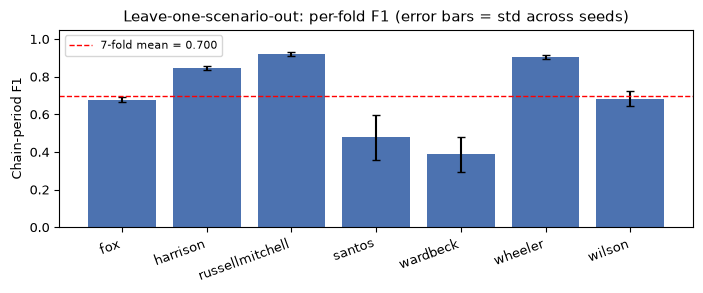

In [6]:
g = per_fold_f1('loso_results_edge_sage.csv')
fig, ax = plt.subplots(figsize=(7.1, 3.0))
x = np.arange(len(g))
ax.bar(x, g['mean'], yerr=g['std'].fillna(0), capsize=3, color='#4C72B0')
ax.axhline(g['mean'].mean(), color='red', linestyle='--', linewidth=1,
           label=f"7-fold mean = {g['mean'].mean():.3f}")
ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=20, ha='right')
ax.set_ylabel('Chain-period F1')
ax.set_title('Leave-one-scenario-out: per-fold F1 (error bars = std across seeds)')
ax.set_ylim(0, 1.05); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_loso_perfold.pdf'), bbox_inches='tight')
plt.show()

## GNN vs non-graph baselines

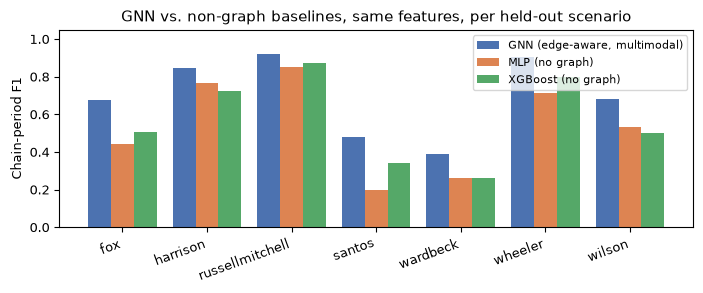

GNN vs MLP: Wilcoxon p=0.0156, paired t-test p=0.0016
GNN vs XGBoost: Wilcoxon p=0.0156, paired t-test p=0.0003


In [7]:
gnn = per_fold_f1('loso_results_edge_sage.csv')['mean']
mlp = per_fold_f1('loso_results_mlp.csv')['mean']
xgb = per_fold_f1('loso_results_xgboost.csv')['mean']
 
folds = gnn.index
x = np.arange(len(folds)); width = 0.27
fig, ax = plt.subplots(figsize=(7.1, 3.0))
ax.bar(x - width, gnn.values, width, label='GNN (edge-aware, multimodal)', color='#4C72B0')
ax.bar(x, mlp.reindex(folds).values, width, label='MLP (no graph)', color='#DD8452')
ax.bar(x + width, xgb.reindex(folds).values, width, label='XGBoost (no graph)', color='#55A868')
ax.set_xticks(x); ax.set_xticklabels(folds, rotation=20, ha='right')
ax.set_ylabel('Chain-period F1')
ax.set_title('GNN vs. non-graph baselines, same features, per held-out scenario')
ax.set_ylim(0, 1.05); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_gnn_vs_baselines.pdf'), bbox_inches='tight')
plt.show()
 
# paired significance, printed alongside the figure
w, pw = stats.wilcoxon(gnn.values, mlp.reindex(folds).values)
t, pt = stats.ttest_rel(gnn.values, mlp.reindex(folds).values)
print(f'GNN vs MLP: Wilcoxon p={pw:.4f}, paired t-test p={pt:.4f}')
w, pw = stats.wilcoxon(gnn.values, xgb.reindex(folds).values)
t, pt = stats.ttest_rel(gnn.values, xgb.reindex(folds).values)
print(f'GNN vs XGBoost: Wilcoxon p={pw:.4f}, paired t-test p={pt:.4f}')

## 2x2 architecture x modality design

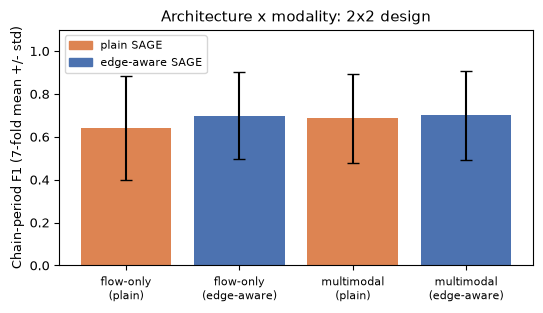

In [8]:
cells_files = {
    'flow-only\n(plain)':        'loso_results_flow_only_plain.csv',
    'flow-only\n(edge-aware)':   'loso_results_flow_only.csv',
    'multimodal\n(plain)':       'loso_results_multimodal_plain.csv',
    'multimodal\n(edge-aware)':  'loso_results_edge_sage.csv',
}
means, stds = [], []
for label, fname in cells_files.items():
    g = per_fold_f1(fname)
    means.append(g['mean'].mean()); stds.append(g['mean'].std())
 
fig, ax = plt.subplots(figsize=(5.5, 3.2))
colors = ['#DD8452','#4C72B0','#DD8452','#4C72B0']
xpos = np.arange(4)
ax.bar(xpos, means, yerr=stds, capsize=4, color=colors)
ax.set_xticks(xpos); ax.set_xticklabels(list(cells_files.keys()), fontsize=8)
ax.set_ylabel('Chain-period F1 (7-fold mean +/- std)')
ax.set_title('Architecture x modality: 2x2 design')
ax.set_ylim(0, 1.1)
import matplotlib.patches as mpatches
ax.legend(handles=[mpatches.Patch(color='#DD8452', label='plain SAGE'),
                    mpatches.Patch(color='#4C72B0', label='edge-aware SAGE')], fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_2x2_design.pdf'), bbox_inches='tight')
plt.show()

## Host-role recall (reads the file Phase 6's breakdown already saved)

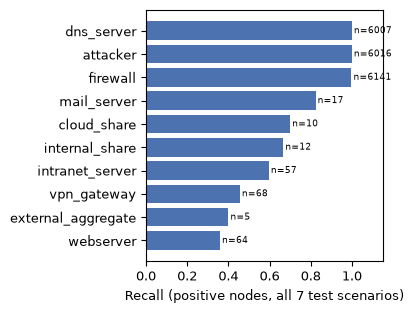

In [9]:
role_recall = pd.read_csv(os.path.join(OUT_DIR, 'loso_recall_by_host_role.csv'))
role_recall = role_recall.sort_values('recall')
 
fig, ax = plt.subplots(figsize=(4.0, 3.2))
ax.barh(role_recall.host_role, role_recall.recall, color='#4C72B0')
for i, row in enumerate(role_recall.itertuples()):
    ax.text(row.recall + 0.01, i, f'n={int(row.n_pos)}', va='center', fontsize=6.5)
ax.set_xlabel('Recall (positive nodes, all 7 test scenarios)')
ax.set_xlim(0, 1.15)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_host_role_recall.pdf'), bbox_inches='tight')
plt.show()

## Attack-stage recall (aggregates the saved per-label CSV into 4 stages)

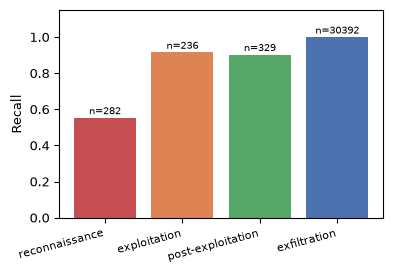

            stage   n_pos  n_detected   recall
   reconnaissance   282.0       156.0 0.553191
     exploitation   236.0       216.0 0.915254
post-exploitation   329.0       297.0 0.902736
     exfiltration 30392.0     30377.0 0.999506


In [10]:
label_recall = pd.read_csv(os.path.join(OUT_DIR, 'loso_recall_by_attack_label.csv'))
 
STAGE_MAP = {
    'reconnaissance': {'online_cracking','service_scan','host_discover_dmz','host_discover_local',
                        'dns_brute_force_start','network_scan','dns_scan','traceroute'},
    'exploitation': {'dirb_scan','foothold','wpscan','attacker_http','dirb','upload_rce_shell',
                      'webshell_cmd','webshell_upload'},
    'exfiltration': {'data exfiltration','attacker','dnsteal','dnsteal-received','dnsteal-dropped'},
}
def stage_of(label):
    for stage, labs in STAGE_MAP.items():
        if label in labs: return stage
    return 'post-exploitation'   # everything else: check_*/read_*/list_*/escalate*/vpn_connect/etc.
 
label_recall['stage'] = label_recall['label'].apply(stage_of)
stage_agg = label_recall.groupby('stage').apply(
    lambda g: pd.Series({'n_pos': g.n_pos.sum(), 'n_detected': g.n_detected.sum()})
).reset_index()
stage_agg['recall'] = stage_agg.n_detected / stage_agg.n_pos
order = ['reconnaissance', 'exploitation', 'post-exploitation', 'exfiltration']
stage_agg = stage_agg.set_index('stage').reindex(order).reset_index()
 
fig, ax = plt.subplots(figsize=(4.0, 2.8))
ax.bar(stage_agg.stage, stage_agg.recall, color=['#C44E52','#DD8452','#55A868','#4C72B0'])
for i, row in enumerate(stage_agg.itertuples()):
    ax.text(i, row.recall + 0.02, f'n={int(row.n_pos)}', ha='center', fontsize=7)
ax.set_ylabel('Recall'); ax.set_ylim(0, 1.15)
plt.xticks(rotation=15, ha='right', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_attack_stage_recall.pdf'), bbox_inches='tight')
plt.show()
print(stage_agg.to_string(index=False))

# Extras

In [2]:
# S0 -- shared setup for every revision cell (no torch needed here).
# Run AFTER your Phase 5 cells 82-86 so set_seed / build_graphs_from_fold / the model classes /
# train_model / macro_f1_for_selection / evaluate_logits already exist in the kernel.
import os, re, pickle, itertools, time
import numpy as np, pandas as pd
from scipy import stats
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, matthews_corrcoef

OUT_DIR = r"G:\My Drive\nids-capstone\data\ait\processed"
WINDOW_MINUTES = 5
SCENARIOS = ['russellmitchell', 'fox', 'santos', 'wheeler', 'wardbeck', 'wilson', 'harrison']
REV_DIR = os.path.join(OUT_DIR, 'revision'); os.makedirs(REV_DIR, exist_ok=True)
MODEL_DIR = os.path.join(REV_DIR, 'models'); os.makedirs(MODEL_DIR, exist_ok=True)
THRESHOLD = 0.5            # sigmoid(logit) > 0.5  <=>  logit > 0 : fixed, never tuned (state this in the paper)

def load_fold(sc):
    with open(os.path.join(OUT_DIR, f'loso_fold_test-{sc}_w{WINDOW_MINUTES}m.pkl'), 'rb') as f:
        return pickle.load(f)

def _metric(yt, yp):
    if yt.sum() == 0 and yp.sum() == 0:
        return 1.0, 1.0, 1.0
    p, r, f1, _ = precision_recall_fscore_support(yt, yp, average='binary', zero_division=0)
    return p, r, f1

def block_bootstrap_ci(y_true, y_pred, block_ids, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    ub = np.unique(block_ids)
    b2i = {b: np.flatnonzero(block_ids == b) for b in ub}
    f1s = []
    for _ in range(n_boot):
        idx = np.concatenate([b2i[b] for b in rng.choice(ub, size=len(ub), replace=True)])
        f1s.append(_metric(y_true[idx], y_pred[idx])[2])
    return float(np.mean(f1s)), float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))

# same stage map as your Cell 144, so numbers stay comparable with the paper's Fig. 5
STAGE_MAP = {
    'reconnaissance': {'online_cracking','service_scan','host_discover_dmz','host_discover_local',
                       'dns_brute_force_start','network_scan','dns_scan','traceroute'},
    'exploitation': {'dirb_scan','foothold','wpscan','attacker_http','dirb','upload_rce_shell',
                     'webshell_cmd','webshell_upload'},
    'exfiltration': {'data exfiltration','attacker','dnsteal','dnsteal-received','dnsteal-dropped'},
}
def stage_of(label):
    for stage, labs in STAGE_MAP.items():
        if label in labs: return stage
    return 'post-exploitation'
STAGES = ['reconnaissance', 'exploitation', 'post-exploitation', 'exfiltration']

def canonical_host_role(host):
    if host == 'attacker_0': return 'attacker'
    if host == 'inet-dns': return 'dns_server'
    if host == 'inet-firewall': return 'firewall'
    if host == 'webserver': return 'webserver'
    if host == 'intranet_server': return 'intranet_server'
    if host == 'vpn': return 'vpn_gateway'
    if host == 'cloud_share': return 'cloud_share'
    if host == 'internal_share': return 'internal_share'
    if host == 'monitoring': return 'monitoring'
    if host == 'external': return 'external_aggregate'
    if 'mail' in host: return 'mail_server'
    if re.match(r'internal_employee', host): return 'internal_employee'
    if re.match(r'remote_employee', host): return 'remote_employee'
    if re.match(r'ext_user', host): return 'external_user'
    return 'other'

def make_meta(fold, sc):
    """Returns f(window_id, node_idx) -> dict of metadata for one node-window of scenario sc."""
    S = fold['scenarios'][sc]
    hosts = S['hosts']
    wid_period = {int(w): S['window_periods'][i] for i, w in enumerate(S['window_ids'])}
    wid_block  = {int(w): str(S['block_ids'][i]) for i, w in enumerate(S['window_ids'])}
    lab = {(r.host, int(r.window_id)): r.labels for r in S['label_table'].itertuples()}
    def f(wid, node_idx):
        h = hosts[node_idx]
        return dict(test_scenario=sc, window_id=int(wid), host=h, host_role=canonical_host_role(h),
                    period=wid_period.get(int(wid), 'clean'), block_id=wid_block.get(int(wid), 'na'),
                    labels='|'.join(lab.get((h, int(wid)), [])))
    return f
print('S0 ready. Output folder:', REV_DIR)


S0 ready. Output folder: G:\My Drive\nids-capstone\data\ait\processed\revision


In [28]:
# S1 -- metric helpers used by every new run (numpy only).  Adds AUPRC, MCC, FPR, prevalence, all-attack baseline.
PRED_COLS = ['test_scenario','window_id','host','host_role','period','block_id','labels','y_true','prob','seed','model']

def summarize_preds(pred_df, tag, n_boot=500, write=True):
    rows = []
    for (sc, seed), g in pred_df.groupby(['test_scenario', 'seed']):
        for period in ['exfil', 'chain', 'clean']:
            m = g[g.period == period]
            if len(m) == 0: continue
            yt = m.y_true.to_numpy().astype(int); pr = m.prob.to_numpy(); yp = (pr > THRESHOLD).astype(int)
            p, r, f1 = _metric(yt, yp)
            bid = (m.block_id.astype(str) + '_' + (m.window_id // 6).astype(str)).to_numpy()
            _, lo, hi = block_bootstrap_ci(yt, yp, bid, n_boot=n_boot)            
            fp = int(((yp == 1) & (yt == 0)).sum()); neg = int((yt == 0).sum()); prev = yt.mean()
            has_both = 0 < yt.sum() < len(yt)
            rows.append(dict(test_scenario=sc, period=period, seed=seed, n=len(m), n_pos=int(yt.sum()),
                precision=round(p, 3), recall=round(r, 3), f1=round(f1, 3),
                f1_ci_lo=round(lo, 3), f1_ci_hi=round(hi, 3), fpr=round(fp / max(neg, 1), 4),
                prevalence=round(prev, 4), all_attack_f1=round(2 * prev / (1 + prev), 3) if prev > 0 else np.nan,
                auprc=round(average_precision_score(yt, pr), 3) if has_both else np.nan,
                mcc=round(matthews_corrcoef(yt, yp), 3) if (has_both or yp.any()) else np.nan, model=tag))
    out = pd.DataFrame(rows)
    if write: out.to_csv(os.path.join(OUT_DIR, f'loso_results_{tag}.csv'), index=False)
    return out

def headline(results_df, period='chain'):
    d = results_df[results_df.period == period].groupby('test_scenario')[['f1','precision','recall','auprc','mcc','fpr','all_attack_f1']].mean()
    return d.agg(['mean', 'std']).round(3)

def stage_metrics(pred_df):
    """Per attack stage: recall, precision and FPR.  Window-local definition (state it in the paper):
       positives = node-windows carrying a label of that stage; negatives = benign node-windows that sit in the
       SAME windows as those positives.  Precision = TP/(TP+FP) on that union; FPR = FP / negatives."""
    df = pred_df.copy(); df['pred'] = (df.prob > THRESHOLD).astype(int)
    pos = df[df.y_true == 1].copy()
    pos['stages'] = pos.labels.fillna('').apply(lambda s: {stage_of(l) for l in s.split('|') if l})
    out = []
    for seed, d in df.groupby('seed'):
        dp = pos[pos.seed == seed]
        for st_ in STAGES:
            ps = dp[dp.stages.apply(lambda s: st_ in s)]
            if len(ps) == 0: continue
            wins = pd.MultiIndex.from_frame(ps[['test_scenario', 'window_id']].drop_duplicates())
            neg = d[(d.y_true == 0)]
            neg = neg[pd.MultiIndex.from_frame(neg[['test_scenario', 'window_id']]).isin(wins)]
            tp = int(ps.pred.sum()); fn = len(ps) - tp; fp = int(neg.pred.sum())
            prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / len(ps)
            out.append(dict(seed=seed, stage=st_, n_pos=len(ps), n_neg=len(neg), recall=rec, precision=prec,
                            fpr=fp / max(len(neg), 1), f1=2 * prec * rec / (prec + rec) if prec + rec else 0.0))
    s = pd.DataFrame(out)
    return s.groupby('stage').mean(numeric_only=True).drop(columns='seed').reindex(STAGES).round(3)

def label_level_recall(pred_df):
    """Reproduces the paper's Fig. 4/5 counting: one row per (positive node-window, label)."""
    pos = pred_df[pred_df.y_true == 1].copy(); pos['pred'] = (pos.prob > THRESHOLD).astype(int)
    pos['label'] = pos.labels.fillna('').str.split('|'); pos = pos.explode('label'); pos = pos[pos.label != '']
    pos['stage'] = pos.label.apply(stage_of)
    return (pos.groupby('stage').agg(n=('pred', 'size'), detected=('pred', 'sum'), recall=('pred', 'mean'))
            .reindex(STAGES).round(3))
print('S1 helpers ready.')


S1 helpers ready.


In [9]:
# S2 -- generic LOSO runner that (a) supports GCN/GAT/plain/edge models, (b) keeps per-node probabilities, (c) saves model
# weights, (d) optionally tunes with an equal random-search budget, (e) supports label modes and a positive-class-weight scale.
# Needs Phase 5 cells 82-86 (imports, classes, pretrain_encoder, pos_weight_for, macro_f1_for_selection).
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv
from torch_geometric.loader import DataLoader
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class GCNClassifier(nn.Module):
    def __init__(self, in_dim, hidden=128, embed=128):
        super().__init__()
        self.c1, self.c2 = GCNConv(in_dim, hidden), GCNConv(hidden, embed)
        self.head = nn.Sequential(nn.Linear(embed, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x, edge_index, edge_attr=None):
        h = F.relu(self.c1(x, edge_index)); h = self.c2(h, edge_index)
        return self.head(h).squeeze(-1)

class GATClassifier(nn.Module):          # uses the 5-d edge features too (GATConv edge_dim)
    def __init__(self, in_dim, edge_dim, hidden=128, embed=128, heads=4):
        super().__init__()
        self.c1 = GATConv(in_dim, hidden // heads, heads=heads, edge_dim=edge_dim)
        self.c2 = GATConv(hidden, embed, heads=1, edge_dim=edge_dim)
        self.head = nn.Sequential(nn.Linear(embed, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x, edge_index, edge_attr=None):
        h = F.elu(self.c1(x, edge_index, edge_attr)); h = self.c2(h, edge_index, edge_attr)
        return self.head(h).squeeze(-1)

def make_model(kind, in_dim, edge_dim, pretrained_state=None):
    if kind == 'edge':  return EdgeNIDSClassifier(in_dim, edge_dim, 128, 128, pretrained_state=pretrained_state)
    if kind == 'plain': return NIDSClassifier(in_dim, 128, 128, pretrained_state=pretrained_state)
    if kind == 'gcn':   return GCNClassifier(in_dim)
    if kind == 'gat':   return GATClassifier(in_dim, edge_dim)
    raise ValueError(kind)

def train_model_v2(model, train_graphs, val_graphs, fold, n_epochs=40, lr=1e-3, wd=0.0, pws=1.0, patience=8):
    """Identical to your train_model, plus weight decay and a positive-class-weight multiplier (pws)."""
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_for(train_graphs) * pws)
    loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
    best_f1, best_state, bad = -1, None, 0
    for epoch in range(n_epochs):
        model.train()
        for batch in loader:
            batch = batch.to(DEVICE)
            if batch.active.sum() == 0: continue
            opt.zero_grad()
            logits = model(batch.x, batch.edge_index, batch.edge_attr)
            loss_fn(logits[batch.active], batch.y[batch.active]).backward(); opt.step()
        f1 = macro_f1_for_selection(model, val_graphs, fold)
        if f1 > best_f1:
            best_f1, best_state, bad = f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return model, best_f1

def apply_label_mode(graphs, fold, mode):
    """mode: 'or' (paper default y_flow | y_log), 'flow' (flow labels only), 'log' (log labels only)."""
    if mode == 'or': return graphs
    key = {'flow': 'y_flow', 'log': 'y_log'}[mode]; cache = {}
    for g in graphs:
        if g.scenario not in cache:
            S = fold['scenarios'][g.scenario]
            cache[g.scenario] = ({int(w): i for i, w in enumerate(S['window_ids'])}, S[key])
        w2i, Y = cache[g.scenario]
        g.y = torch.tensor(Y[w2i[g.window_id]], dtype=torch.float32)
    return graphs

def predict_capture(model, graphs, fold, sc):
    model.eval(); meta = make_meta(fold, sc); rows = []
    with torch.no_grad():
        for g in graphs:
            gd = g.clone().to(DEVICE)                      # clone: Data.to() mutates in place (the bug you hit before)
            prob = torch.sigmoid(model(gd.x, gd.edge_index, gd.edge_attr)).cpu().numpy()
            y = g.y.cpu().numpy(); act = g.active.cpu().numpy().astype(bool)
            for i in np.flatnonzero(act):
                d = meta(g.window_id, i); d['y_true'] = int(y[i]); d['prob'] = float(prob[i]); rows.append(d)
    return pd.DataFrame(rows)

def tune_gnn_cfg(kind, in_dim, edge_dim, pre, train_g, val_g, fold, n_trials, base_pws=1.0, seed=123):
    """Random search, SAME ranges as the paper's Optuna space (lr 1e-4..1e-2, wd 1e-6..1e-2, pos-weight x0.5..2),
       scored on the VALIDATION scenario only (never the test scenario)."""
    rng = np.random.default_rng(seed); best = (-1, dict(lr=1e-3, wd=0.0, pws=base_pws))
    for t in range(n_trials):
        cfg = dict(lr=float(10 ** rng.uniform(-4, -2)), wd=float(10 ** rng.uniform(-6, -2)),
                   pws=float(base_pws * rng.uniform(0.5, 2.0)))
        set_seed(0)
        _, vf1 = train_model_v2(make_model(kind, in_dim, edge_dim, pre), train_g, val_g, fold, n_epochs=25, patience=5, **cfg)
        if vf1 > best[0]: best = (vf1, cfg)
    return best[1]

def run_loso_capture(tag, kind='edge', keep_blocks=('flow', 'log', 'emb'), label_mode='or', use_pretrained=True,
                     pos_weight_scale=1.0, seeds=(0, 1, 2), tune_trials=0, save_models=True):
    pred_path = os.path.join(REV_DIR, f'pred_{tag}.csv')
    done_df = pd.read_csv(pred_path) if os.path.exists(pred_path) else pd.DataFrame()
    done = set(zip(done_df.test_scenario, done_df.seed)) if len(done_df) else set()
    all_preds = [done_df] if len(done_df) else []
    for sc in sorted(SCENARIOS):
        if all((sc, s) in done for s in seeds): print(f'[{tag}] {sc}: done, skipping'); continue
        fold = load_fold(sc)
        tr = apply_label_mode(build_graphs_from_fold(fold, 'train', keep_blocks), fold, label_mode)
        va = apply_label_mode(build_graphs_from_fold(fold, 'val', keep_blocks), fold, label_mode)
        te = apply_label_mode(build_graphs_from_fold(fold, 'test', keep_blocks), fold, label_mode)
        in_dim, edge_dim = tr[0].x.shape[1], tr[0].edge_attr.shape[1]
        pre = None
        if use_pretrained and kind in ('edge', 'plain'):
            set_seed(0)
            pre = pretrain_encoder(EdgeGraphMAE if kind == 'edge' else GraphMAE, tr, in_dim, edge_dim, tag=sc)
        cfg = dict(lr=1e-3, wd=0.0, pws=pos_weight_scale)
        if tune_trials > 0:
            cfg = tune_gnn_cfg(kind, in_dim, edge_dim, pre, tr, va, fold, tune_trials, base_pws=pos_weight_scale)
            print(f'[{tag}] {sc}: tuned cfg {cfg}')
        for seed in seeds:
            if (sc, seed) in done: continue
            set_seed(seed)
            model, vf1 = train_model_v2(make_model(kind, in_dim, edge_dim, pre), tr, va, fold, **cfg)
            d = predict_capture(model, te, fold, sc); d['seed'] = seed; d['model'] = tag
            print(f'[{tag}] {sc} seed {seed}: val macro-F1 {vf1:.3f}, {len(d)} node predictions')
            all_preds.append(d)
            pd.concat(all_preds, ignore_index=True).to_csv(pred_path, index=False)
            if save_models: torch.save(model.state_dict(), os.path.join(MODEL_DIR, f'{tag}_{sc}_s{seed}.pt'))
    preds = pd.concat(all_preds, ignore_index=True)
    res = summarize_preds(preds, tag)
    print(f'[{tag}] chain-period headline (mean/std over folds):'); print(headline(res))
    return preds
print('S2 ready: run_loso_capture(...) defined.')


c:\Users\meetp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\meetp\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


S2 ready: run_loso_capture(...) defined.


In [10]:
# S3 -- Item 3: non-graph baselines that RECEIVE neighbourhood information, with the same tuning budget as the GNN.
# Features per node = [x, mean of 1-hop neighbours, mean of 2-hop (mean of the 1-hop means), mean incoming edge features, log(1+in-degree)].
# Set TUNE_TRIALS identically for run_loso_capture (S2) and here; 0 = nobody tuned (then say so in the paper).
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
TUNE_TRIALS = 0          # e.g. 8 for every model family if you have the compute -- keep it IDENTICAL across families

def nbr_features(g, hops=2):
    x = g.x.numpy(); ei = g.edge_index.numpy(); ea = g.edge_attr.numpy(); N, D = x.shape
    deg = np.zeros(N, np.float32); eagg = np.zeros((N, ea.shape[1]), np.float32)
    def mean_agg(h):
        a = np.zeros_like(h)
        if ei.shape[1]: np.add.at(a, ei[1], h[ei[0]])
        return a / np.maximum(deg, 1)[:, None]
    if ei.shape[1]:
        np.add.at(deg, ei[1], 1); np.add.at(eagg, ei[1], ea)
    m1 = mean_agg(x); parts = [x, m1]
    if hops >= 2: parts.append(mean_agg(m1))
    parts += [eagg / np.maximum(deg, 1)[:, None], np.log1p(deg)[:, None]]
    return np.concatenate(parts, axis=1)

def tab_split(graphs, fold, sc, use_nbr):
    meta = make_meta(fold, sc) if sc else None
    X, y, M = [], [], []
    for g in graphs:
        act = g.active.numpy().astype(bool); idx = np.flatnonzero(act)
        if len(idx) == 0: continue
        F_ = nbr_features(g) if use_nbr else g.x.numpy()
        X.append(F_[idx]); y.append(g.y.numpy()[idx])
        if meta: M += [meta(g.window_id, i) for i in idx]
    return np.concatenate(X), np.concatenate(y).astype(int), M

def _val_score(M, yv, prob):
    per = pd.DataFrame(M); per['y'] = yv; per['p'] = (prob > THRESHOLD).astype(int); f = []
    for period in ['exfil', 'chain']:
        s = per[per.period == period]
        if len(s): f.append(_metric(s.y.to_numpy(), s.p.to_numpy())[2])
    return float(np.mean(f)) if f else 0.0

def _make(name, cfg, seed, base_spw):
    if name == 'mlp':
        return MLPClassifier(hidden_layer_sizes=cfg['h'], alpha=cfg['alpha'], learning_rate_init=cfg['lr'],
                             max_iter=200, early_stopping=True, random_state=seed)
    return XGBClassifier(n_estimators=cfg['n'], max_depth=cfg['d'], learning_rate=cfg['lr'], subsample=cfg['ss'],
                         colsample_bytree=cfg['cs'], scale_pos_weight=base_spw * cfg['spw'], random_state=seed,
                         eval_metric='logloss', n_jobs=-1)

def _sample(name, rng):
    if name == 'mlp':
        return dict(h=[(64, 32), (128, 64), (256, 128)][rng.integers(3)], alpha=float(10 ** rng.uniform(-6, -2)),
                    lr=float(10 ** rng.uniform(-4, -2)))
    return dict(n=int(rng.choice([100, 200, 400])), d=int(rng.integers(3, 9)), lr=float(10 ** rng.uniform(-2, -0.5)),
                ss=float(rng.uniform(0.6, 1.0)), cs=float(rng.uniform(0.5, 1.0)), spw=float(rng.uniform(0.5, 2.0)))

def run_tabular(name, use_nbr, tag, seeds=(0, 1, 2), tune_trials=TUNE_TRIALS):
    pred_path = os.path.join(REV_DIR, f'pred_{tag}.csv'); all_preds = []
    for sc in sorted(SCENARIOS):
        fold = load_fold(sc)
        tr = build_graphs_from_fold(fold, 'train'); va = build_graphs_from_fold(fold, 'val'); te = build_graphs_from_fold(fold, 'test')
        vsc = fold['val_scenario']
        Xtr, ytr, _ = tab_split(tr, fold, None, use_nbr); Xva, yva, Mva = tab_split(va, fold, vsc, use_nbr)
        Xte, yte, Mte = tab_split(te, fold, sc, use_nbr)
        base_spw = (1 - ytr.mean()) / max(ytr.mean(), 1e-6)
        cfg = {}
        if tune_trials > 0:
            rng = np.random.default_rng(123); best = (-1, None)
            for t in range(tune_trials):
                c = _sample(name, rng); clf = _make(name, c, 0, base_spw).fit(Xtr, ytr)
                s = _val_score(Mva, yva, clf.predict_proba(Xva)[:, 1])
                if s > best[0]: best = (s, c)
            cfg = best[1]; print(f'[{tag}] {sc}: tuned {cfg}')
        for seed in seeds:
            if tune_trials > 0: clf = _make(name, cfg, seed, base_spw)
            elif name == 'mlp': clf = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, random_state=seed, early_stopping=True)
            else: clf = XGBClassifier(n_estimators=200, max_depth=6, scale_pos_weight=base_spw, random_state=seed,
                                      eval_metric='logloss', n_jobs=-1)
            clf.fit(Xtr, ytr)
            d = pd.DataFrame(Mte); d['y_true'] = yte; d['prob'] = clf.predict_proba(Xte)[:, 1]; d['seed'] = seed; d['model'] = tag
            all_preds.append(d); print(f'[{tag}] {sc} seed {seed} done')
        pd.concat(all_preds, ignore_index=True).to_csv(pred_path, index=False)
    preds = pd.concat(all_preds, ignore_index=True); res = summarize_preds(preds, tag)
    print(f'[{tag}] chain-period headline:'); print(headline(res)); return preds
print('S3 ready: run_tabular(name, use_nbr, tag) defined.')


S3 ready: run_tabular(name, use_nbr, tag) defined.


In [17]:
# S4 -- RUN THE EXPERIMENTS (each call resumes if interrupted; ~same cost as one of your earlier LOSO sweeps per call).
# Order matters: the first call is needed by almost everything that follows.

# 1) primary model again, this time KEEPING per-node probabilities + weights (AUPRC/MCC, stage analysis, faithfulness)
preds_primary = run_loso_capture('edge_multi', kind='edge')

# 2) other graph models (Item 3).  GCN/GAT have no GraphMAE pretraining, so compare them with your *scratch* run
#    (loso_results_multimodal_edge_scratch.csv).  'egraphsage_style' = edge-aware SAGE whose node inputs are all zero,
#    i.e. only edge (flow) features reach the node -- the closest node-level analogue of E-GraphSAGE.
run_loso_capture('gcn', kind='gcn', use_pretrained=False)
run_loso_capture('gat', kind='gat', use_pretrained=False)
run_loso_capture('egraphsage_style', kind='edge', keep_blocks=(), use_pretrained=False)

# 3) non-graph models that DO see neighbours (Item 3)
run_tabular('mlp', True, 'mlp_nbr')
run_tabular('xgboost', True, 'xgboost_nbr')

# 4) OPTIONAL equal-tuning arm (Item 3): same random-search budget N for every family, scored on the validation scenario.
#    Only do this if you have the compute; otherwise state in the paper that NO model was tuned (see paper text).
# N = 8
# run_loso_capture('edge_multi_tuned', kind='edge', tune_trials=N)
# run_tabular('mlp', True, 'mlp_nbr_tuned', tune_trials=N);  run_tabular('xgboost', True, 'xgboost_nbr_tuned', tune_trials=N)
# run_tabular('mlp', False, 'mlp_tuned', tune_trials=N);     run_tabular('xgboost', False, 'xgboost_tuned', tune_trials=N)

# 5) headline numbers incl. AUPRC and MCC (Item 4).  Report these next to F1 in the paper.
for tag in ['edge_multi', 'gcn', 'gat', 'egraphsage_style', 'mlp_nbr', 'xgboost_nbr']:
    p = os.path.join(OUT_DIR, f'loso_results_{tag}.csv')
    if os.path.isfile(p):
        print(f'\n{tag}:'); print(headline(pd.read_csv(p)))


  [pretrain fox] epoch   0 loss 0.2821
  [pretrain fox] epoch  10 loss 0.1493
  [pretrain fox] epoch  20 loss 0.1451
  [pretrain fox] epoch  29 loss 0.1455
[edge_multi] fox seed 0: val macro-F1 0.931, 18666 node predictions
[edge_multi] fox seed 1: val macro-F1 0.928, 18666 node predictions
[edge_multi] fox seed 2: val macro-F1 0.928, 18666 node predictions
  [pretrain harrison] epoch   0 loss 0.2801
  [pretrain harrison] epoch  10 loss 0.1551
  [pretrain harrison] epoch  20 loss 0.1512
  [pretrain harrison] epoch  29 loss 0.1516
[edge_multi] harrison seed 0: val macro-F1 0.961, 17861 node predictions
[edge_multi] harrison seed 1: val macro-F1 0.970, 17861 node predictions
[edge_multi] harrison seed 2: val macro-F1 0.957, 17861 node predictions
  [pretrain russellmitchell] epoch   0 loss 0.2742
  [pretrain russellmitchell] epoch  10 loss 0.1510
  [pretrain russellmitchell] epoch  20 loss 0.1471
  [pretrain russellmitchell] epoch  29 loss 0.1460
[edge_multi] russellmitchell seed 0: val 

In [15]:
# S5 -- paired statistics, rewritten per faculty item 1.  NO training needed; reads your saved loso_results_*.csv
CONFIGS = {
    'gnn_edge_multi':         'loso_results_edge_multi.csv',
    'gnn_edge_flow':          'loso_results_flow_only.csv',
    'gnn_plain_multi':        'loso_results_multimodal_plain.csv',
    'gnn_plain_flow':         'loso_results_flow_only_plain.csv',
    'gnn_edge_log':           'loso_results_log_only.csv',
    'gnn_edge_multi_scratch': 'loso_results_edge_multi_scratch.csv',
    'mlp':                    'loso_results_mlp_plain.csv',
    'xgboost':                'loso_results_xgboost_plain.csv',
    
    # created by the NEW cells below (skipped automatically if the file does not exist yet)
    'mlp_nbr':                'loso_results_mlp_nbr.csv',
    'xgboost_nbr':            'loso_results_xgboost_nbr.csv',
    'gcn':                    'loso_results_gcn.csv',
    'gat':                    'loso_results_gat.csv',
    'egraphsage_style':       'loso_results_egraphsage_style.csv',
}
# Hypothesis FAMILIES are fixed in advance; Holm is applied inside each family (state this in the paper).
COMPARISONS = [  # (family, A, B)  ->  difference = A - B
    ('A: graph vs non-graph', 'gnn_edge_multi', 'mlp'),
    ('A: graph vs non-graph', 'gnn_edge_multi', 'xgboost'),
    ('A: graph vs non-graph', 'gnn_edge_multi', 'mlp_nbr'),
    ('A: graph vs non-graph', 'gnn_edge_multi', 'xgboost_nbr'),
    ('B: 2x2 design', 'gnn_edge_flow',  'gnn_plain_flow'),
    ('B: 2x2 design', 'gnn_edge_multi', 'gnn_plain_multi'),
    ('B: 2x2 design', 'gnn_edge_multi', 'gnn_edge_flow'),
    ('B: 2x2 design', 'gnn_plain_multi', 'gnn_plain_flow'),
    ('C: log-only', 'gnn_edge_log', 'gnn_edge_multi'),
    ('C: log-only', 'gnn_edge_log', 'gnn_edge_flow'),
    ('D: pretraining', 'gnn_edge_multi', 'gnn_edge_multi_scratch'),
    ('E: other graph models', 'gnn_edge_multi_scratch', 'gcn'),
    ('E: other graph models', 'gnn_edge_multi_scratch', 'gat'),
    ('E: other graph models', 'gnn_edge_multi_scratch', 'egraphsage_style'),
]

def fold_f1(csv, period='chain'):
    df = pd.read_csv(os.path.join(OUT_DIR, csv))
    return df[df.period == period].groupby('test_scenario')['f1'].mean().sort_index()

def holm(p):
    p = np.asarray(p, float); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def paired_row(a, b, n_boot=10000, seed=0):
    d = (a - b).to_numpy()
    n = len(d)
    mean, sd = d.mean(), d.std(ddof=1)
    try:    pw = stats.wilcoxon(d).pvalue            # exact for n=7 when there are no ties / zeros
    except ValueError: pw = 1.0
    pt = stats.ttest_1samp(d, 0.0).pvalue
    wins, losses = int((d > 0).sum()), int((d < 0).sum())
    psign = stats.binomtest(wins, wins + losses, 0.5).pvalue if wins + losses else 1.0
    rng = np.random.default_rng(seed)
    boots = rng.choice(d, size=(n_boot, n), replace=True).mean(axis=1)
    return dict(n_folds=n, mean_diff=mean, sd_diff=sd, cohens_dz=mean / sd if sd > 0 else np.nan,
                wins_losses=f'{wins}-{losses}', p_wilcoxon=pw, p_ttest=pt, p_sign=psign,
                diff_ci_lo=np.percentile(boots, 2.5), diff_ci_hi=np.percentile(boots, 97.5))

fold_scores, rows = {}, []
for name, csv in CONFIGS.items():
    if os.path.isfile(os.path.join(OUT_DIR, csv)):
        fold_scores[name] = fold_f1(csv)
for fam, A, B in COMPARISONS:
    if A in fold_scores and B in fold_scores:
        idx = fold_scores[A].index.intersection(fold_scores[B].index)
        rows.append(dict(family=fam, A=A, B=B, **paired_row(fold_scores[A][idx], fold_scores[B][idx])))
    else:
        print(f'  (skipping {A} vs {B}: results file not found yet)')

st = pd.DataFrame(rows)
st['p_holm_wilcoxon'] = np.nan
for fam, g in st.groupby('family'):
    st.loc[g.index, 'p_holm_wilcoxon'] = holm(g.p_wilcoxon.values)
st['p_holm_ttest'] = np.nan
for fam, g in st.groupby('family'):
    st.loc[g.index, 'p_holm_ttest'] = holm(g.p_ttest.values)

pd.set_option('display.width', 250, 'display.max_columns', 30)
print(st.round(4).to_string(index=False))
print('\nSmallest possible exact two-sided Wilcoxon p with 7 folds = 2/2^7 = %.4f. ' % (2 / 2**7) +
      'So a family of m>=4 tests can NEVER be significant after Holm on Wilcoxon alone -- report this honestly.')
print('Fold-mean chain F1 per config:')
print(pd.DataFrame({k: v.round(3) for k, v in fold_scores.items()}).to_string())
st.to_csv(os.path.join(REV_DIR, 'paired_stats_holm.csv'), index=False)

METRIC = 'auprc'
CONFIGS['gnn_edge_multi'] = 'loso_results_edge_multi.csv'
def fold_f1(csv, period='chain'):
    df = pd.read_csv(os.path.join(OUT_DIR, csv))
    if METRIC not in df.columns: return pd.Series(dtype=float)
    return df[df.period == period].groupby('test_scenario')[METRIC].mean().sort_index()
# and right after the first `for name, csv in CONFIGS.items()` loop:
fold_scores = {k: v for k, v in fold_scores.items() if len(v)}


               family                      A                      B  n_folds  mean_diff  sd_diff  cohens_dz wins_losses  p_wilcoxon  p_ttest  p_sign  diff_ci_lo  diff_ci_hi  p_holm_wilcoxon  p_holm_ttest
A: graph vs non-graph         gnn_edge_multi                    mlp        7     0.1719   0.0965     1.7805         7-0      0.0156   0.0033  0.0156      0.1108      0.2400           0.0625        0.0099
A: graph vs non-graph         gnn_edge_multi                xgboost        7     0.1364   0.0646     2.1101         7-0      0.0156   0.0014  0.0156      0.0935      0.1804           0.0625        0.0056
A: graph vs non-graph         gnn_edge_multi                mlp_nbr        7     0.1083   0.0814     1.3311         7-0      0.0156   0.0125  0.0156      0.0567      0.1660           0.0625        0.0250
A: graph vs non-graph         gnn_edge_multi            xgboost_nbr        7     0.1265   0.1000     1.2658         7-0      0.0156   0.0154  0.0156      0.0578      0.1923           0

In [34]:
# S6 -- Items 2 and 4 (partly): main results table with per-fold P/R/F1 + block-bootstrap CI, Table I with CIs,
# all-attack baseline and prevalence.  NO training needed: your saved CSVs already contain the CIs.
def chain_table(csv):
    df = pd.read_csv(os.path.join(OUT_DIR, csv)); df = df[df.period == 'chain']
    g = df.groupby('test_scenario').agg(
        precision=('precision', 'mean'), recall=('recall', 'mean'), f1=('f1', 'mean'), f1_sd_seeds=('f1', 'std'),
        ci_lo=('f1_ci_lo', 'mean'), ci_hi=('f1_ci_hi', 'mean'), n=('n', 'first'), n_pos=('n_pos', 'first'))
    return g.sort_index()

T = {'GNN': chain_table('loso_results_edge_multi.csv'),
     'MLP': chain_table('loso_results_mlp_plain.csv'),
     'XGB': chain_table('loso_results_xgboost_plain.csv')}
base = T['GNN'][['n', 'n_pos']].copy()
base['prevalence'] = base.n_pos / base.n
base['all_attack_f1'] = 2 * base.prevalence / (1 + base.prevalence)     # precision = prevalence, recall = 1
print('=== Attack prevalence and the trivial "predict everything = attack" baseline, chain period ===')
print(base.round(3).to_string())
print('mean all-attack F1 over folds: %.3f   (compare with GNN %.3f)' % (base.all_attack_f1.mean(), T['GNN'].f1.mean()))

def cell(r): return f"{r.f1:.3f} [{r.ci_lo:.3f}, {r.ci_hi:.3f}]"
print('\n=== Main results table (chain period; F1 [95% block-bootstrap CI averaged over 3 seeds]) ===')
main = pd.DataFrame({'pos/n': [f"{int(r.n_pos)}/{int(r.n)}" for r in base.itertuples()],
                     'all-attack F1': base.all_attack_f1.round(3).values}, index=base.index)
for k, t in T.items():
    main[f'{k} P'] = t.precision.round(3); main[f'{k} R'] = t.recall.round(3)
    main[f'{k} F1 [CI]'] = [cell(r) for r in t.itertuples()]
print(main.to_string())
main.to_csv(os.path.join(REV_DIR, 'main_results_table.csv'))

# LaTeX body for a table* -- paste inside your tabular (columns: fold, pos/n, all-attack F1, GNN P R F1[CI], MLP F1[CI], XGB F1[CI])
tex = []
for sc in base.index:
    g, m, x = T['GNN'].loc[sc], T['MLP'].loc[sc], T['XGB'].loc[sc]
    tex.append(f"{sc} & {int(base.loc[sc,'n_pos'])}/{int(base.loc[sc,'n'])} & {base.loc[sc,'all_attack_f1']:.2f} & "
               f"{g.precision:.2f} & {g.recall:.2f} & {g.f1:.2f} [{g.ci_lo:.2f}, {g.ci_hi:.2f}] & "
               f"{m.f1:.2f} [{m.ci_lo:.2f}, {m.ci_hi:.2f}] & {x.f1:.2f} [{x.ci_lo:.2f}, {x.ci_hi:.2f}] \\\\")
tex.append(f"\\midrule Mean & -- & {base.all_attack_f1.mean():.2f} & {T['GNN'].precision.mean():.2f} & {T['GNN'].recall.mean():.2f} & "
           f"{T['GNN'].f1.mean():.2f} & {T['MLP'].f1.mean():.2f} & {T['XGB'].f1.mean():.2f} \\\\")
print('\n--- LaTeX rows ---'); print('\n'.join(tex))

# Table I with CIs: pretrained vs scratch
pre, scr = chain_table('loso_results_edge_multi.csv'), chain_table('loso_results_edge_multi_scratch.csv')
t1 = pd.DataFrame({'Pretrained F1 [CI]': [cell(r) for r in pre.itertuples()],
                   'Scratch F1 [CI]': [cell(r) for r in scr.itertuples()]}, index=pre.index)
print('\n=== Table I with CIs ==='); print(t1.to_string())
t1.to_csv(os.path.join(REV_DIR, 'table1_pretrain_with_ci.csv'))


=== Attack prevalence and the trivial "predict everything = attack" baseline, chain period ===
                   n  n_pos  prevalence  all_attack_f1
test_scenario                                         
fox              193     47       0.244          0.392
harrison         302    112       0.371          0.541
russellmitchell   48     27       0.562          0.720
santos           168     33       0.196          0.328
wardbeck         152     33       0.217          0.357
wheeler           87     30       0.345          0.513
wilson           212     45       0.212          0.350
mean all-attack F1 over folds: 0.457   (compare with GNN 0.710)

=== Main results table (chain period; F1 [95% block-bootstrap CI averaged over 3 seeds]) ===
                   pos/n  all-attack F1  GNN P  GNN R           GNN F1 [CI]  MLP P  MLP R           MLP F1 [CI]  XGB P  XGB R           XGB F1 [CI]
test_scenario                                                                                           

In [20]:
# S7 -- Item 5 (circular labels / features).
# (a) How much of the positive set depends on log labels at all?  (no training)
rows = []
for sc in SCENARIOS:
    S = load_fold(sc)['scenarios'][sc]; act = S['active']; per = np.asarray(S['window_periods'], dtype=object)
    yf, yl = S['y_flow'] & act, S['y_log'] & act
    for period in ['exfil', 'chain', 'clean']:
        m = (per == period)[:, None] & act
        rows.append(dict(scenario=sc, period=period, flow_only=int((yf & ~yl & m).sum()), log_only=int((yl & ~yf & m).sum()),
                         both=int((yf & yl & m).sum()), total_pos=int(((yf | yl) & m).sum())))
comp = pd.DataFrame(rows)
print(comp.groupby('period')[['flow_only', 'log_only', 'both', 'total_pos']].sum())
print('\n(log_only = positives that exist ONLY because of the OR with log labels -- report this share per period)')
comp.to_csv(os.path.join(REV_DIR, 'label_source_composition.csv'), index=False)

# (b) Retrain/evaluate with FLOW LABELS ONLY.  If the multimodal model's advantage or the chain-period F1 collapses,
#     labels and log features are entangled; if flow_only (no log features at all) keeps its F1 on OR-labels (you already
#     have this: loso_results_flow_only.csv), the OR-labelling is not what produces the result.
run_loso_capture('edge_multi_flowlabels', kind='edge', label_mode='flow')
run_loso_capture('flow_only_flowlabels', kind='edge', keep_blocks=('flow',), label_mode='flow')
for tag in ['edge_multi_flowlabels', 'flow_only_flowlabels']:
    print(f'\n{tag}  (labels = flow labels only; evaluated against flow labels):')
    print(headline(pd.read_csv(os.path.join(OUT_DIR, f'loso_results_{tag}.csv'))))


        flow_only  log_only  both  total_pos
period                                      
chain         259        19    49        327
clean           0         1     0          1
exfil       11962      6107     0      18069

(log_only = positives that exist ONLY because of the OR with log labels -- report this share per period)
  [pretrain fox] epoch   0 loss 0.2821
  [pretrain fox] epoch  10 loss 0.1507
  [pretrain fox] epoch  20 loss 0.1449
  [pretrain fox] epoch  29 loss 0.1452
[edge_multi_flowlabels] fox seed 0: val macro-F1 0.902, 18666 node predictions
[edge_multi_flowlabels] fox seed 1: val macro-F1 0.899, 18666 node predictions
[edge_multi_flowlabels] fox seed 2: val macro-F1 0.895, 18666 node predictions
  [pretrain harrison] epoch   0 loss 0.2801
  [pretrain harrison] epoch  10 loss 0.1550
  [pretrain harrison] epoch  20 loss 0.1500
  [pretrain harrison] epoch  29 loss 0.1503
[edge_multi_flowlabels] harrison seed 0: val macro-F1 0.959, 17861 node predictions
[edge_multi_flow

In [21]:
# S8 -- Item 8: reconnaissance weakness as a real contribution.  Needs S4 step 1 (pred_edge_multi.csv).  No training.
pp = pd.read_csv(os.path.join(REV_DIR, 'pred_edge_multi.csv')); pp['labels'] = pp['labels'].fillna('')

print('=== Label-level recall, seed 0 (this reproduces the style of your Fig. 5; numbers can differ slightly from the old single run) ===')
print(label_level_recall(pp[pp.seed == 0]))
print('\n=== Per-stage recall / precision / FPR (window-local definition, mean over 3 seeds) ===')
sm = stage_metrics(pp); print(sm); sm.to_csv(os.path.join(REV_DIR, 'stage_metrics.csv'))

pos = pp[(pp.seed == 0) & (pp.y_true == 1)].copy()
pos['stages'] = pos.labels.apply(lambda s: {stage_of(l) for l in s.split('|') if l})
recon = pos[pos.stages.apply(lambda s: 'reconnaissance' in s)].copy(); recon['detected'] = recon.prob > THRESHOLD
print('\n=== Reconnaissance recall PER SCENARIO (is the weakness uniform or scenario-driven?) ===')
print(recon.groupby('test_scenario').agg(n=('detected', 'size'), recall=('detected', 'mean')).round(3))
print('\n=== Reconnaissance recall PER HOST ROLE ===')
print(recon.groupby('host_role').agg(n=('detected', 'size'), recall=('detected', 'mean')).round(3))

# Why does it fail?  Compare standardised feature values of detected recon, MISSED recon, and benign nodes of the same host roles.
roles = set(recon.host_role); benign = pp[(pp.seed == 0) & (pp.y_true == 0) & (pp.host_role.isin(roles))]
G = {'det': [], 'miss': [], 'ben': []}; names = None
for sc in SCENARIOS:
    S = load_fold(sc)['scenarios'][sc]; names = S['flow_feature_names'] + S['log_feature_names']
    X = np.concatenate([S['X_flow'], S['X_log']], axis=-1)
    w2i = {int(w): i for i, w in enumerate(S['window_ids'])}; h2i = {h: i for i, h in enumerate(S['hosts'])}
    def grab(df):
        d = df[df.test_scenario == sc]
        return X[[w2i[w] for w in d.window_id], [h2i[h] for h in d.host]] if len(d) else np.zeros((0, X.shape[-1]))
    G['det'].append(grab(recon[recon.detected])); G['miss'].append(grab(recon[~recon.detected])); G['ben'].append(grab(benign))
G = {k: np.concatenate(v) for k, v in G.items()}
ft = pd.DataFrame({'feature': names, 'z_detected': G['det'].mean(0), 'z_missed': G['miss'].mean(0), 'z_benign_same_roles': G['ben'].mean(0)})
ft['sep_detected_vs_benign'] = (ft.z_detected - ft.z_benign_same_roles).abs()
ft['sep_missed_vs_benign'] = (ft.z_missed - ft.z_benign_same_roles).abs()
print(f"\nn detected={len(G['det'])}, missed={len(G['miss'])}, benign(same roles)={len(G['ben'])}")
print('Features that separate DETECTED recon from benign -- and how far the MISSED ones sit from benign on the same features:')
print(ft.sort_values('sep_detected_vs_benign', ascending=False).head(12).round(2).to_string(index=False))
print('\nIf sep_missed_vs_benign is much smaller than sep_detected_vs_benign, missed recon is feature-wise indistinguishable from background.')
ft.to_csv(os.path.join(REV_DIR, 'recon_feature_overlap.csv'), index=False)


=== Label-level recall, seed 0 (this reproduces the style of your Fig. 5; numbers can differ slightly from the old single run) ===
                       n  detected  recall
stage                                     
reconnaissance       282       159   0.564
exploitation         236       220   0.932
post-exploitation    329       294   0.894
exfiltration       30392     30381   1.000

=== Per-stage recall / precision / FPR (window-local definition, mean over 3 seeds) ===
                     n_pos    n_neg  recall  precision    fpr     f1
stage                                                               
reconnaissance       200.0    671.0   0.452      0.921  0.011  0.606
exploitation          99.0    322.0   0.902      0.879  0.038  0.890
post-exploitation     56.0    255.0   0.696      0.886  0.020  0.780
exfiltration       18138.0  65880.0   1.000      0.988  0.003  0.994

=== Reconnaissance recall PER SCENARIO (is the weakness uniform or scenario-driven?) ===
                  

In [22]:
# S9 -- Item 8 (optional intervention): does a larger positive-class weight lift reconnaissance recall, and at what FPR cost?
# Each extra scale = one more LOSO sweep (same cost as S4 step 1).  Scale 1 is the run you already have.
rows = []
for s in [1.0, 2.0, 4.0]:
    tag = 'edge_multi' if s == 1.0 else f'edge_multi_pws{int(s)}'
    p = run_loso_capture(tag, kind='edge', pos_weight_scale=s)
    sm = stage_metrics(p); res = pd.read_csv(os.path.join(OUT_DIR, f'loso_results_{tag}.csv'))
    h = headline(res).loc['mean']; clean_fpr = res[res.period == 'clean'].fpr.mean()
    rows.append(dict(pos_weight_scale=s, recon_recall=sm.loc['reconnaissance', 'recall'], recon_precision=sm.loc['reconnaissance', 'precision'],
                     recon_fpr=sm.loc['reconnaissance', 'fpr'], chain_f1=h['f1'], chain_auprc=h['auprc'], clean_period_fpr=round(clean_fpr, 4)))
iv = pd.DataFrame(rows); print(iv.to_string(index=False)); iv.to_csv(os.path.join(REV_DIR, 'recon_intervention.csv'), index=False)
# A longer window (e.g. 15 min) is the other intervention your faculty suggested; it needs Phase 2-3 re-run with
# WINDOW_MINUTES = 15 and new fold pickles (loso_fold_test-*_w15m.pkl) -- only attempt if time allows.

[edge_multi] fox: done, skipping
[edge_multi] harrison: done, skipping
[edge_multi] russellmitchell: done, skipping
[edge_multi] santos: done, skipping
[edge_multi] wardbeck: done, skipping
[edge_multi] wheeler: done, skipping
[edge_multi] wilson: done, skipping
[edge_multi] chain-period headline (mean/std over folds):
         f1  precision  recall  auprc    mcc   fpr  all_attack_f1
mean  0.710       0.93   0.617  0.930  0.679  0.03          0.457
std   0.208       0.04   0.266  0.041  0.165  0.04          0.142
  [pretrain fox] epoch   0 loss 0.2821
  [pretrain fox] epoch  10 loss 0.1492
  [pretrain fox] epoch  20 loss 0.1450
  [pretrain fox] epoch  29 loss 0.1456
[edge_multi_pws2] fox seed 0: val macro-F1 0.931, 18666 node predictions
[edge_multi_pws2] fox seed 1: val macro-F1 0.928, 18666 node predictions
[edge_multi_pws2] fox seed 2: val macro-F1 0.926, 18666 node predictions
  [pretrain harrison] epoch   0 loss 0.2801
  [pretrain harrison] epoch  10 loss 0.1554
  [pretrain harris

In [23]:
# S10 -- Item 7: deletion (faithfulness) test for the saliency result, on ALL 7 folds, plus block-level ablation to
# reconcile "top feature is a log feature" with "fusion does not help".  Needs S4 step 1 (saved models models/edge_multi_*).
def faithfulness_fold(sc, seed=0, k=10, n_random=20, tag='edge_multi', rng_seed=0):
    fold = load_fold(sc); S = fold['scenarios'][sc]
    names = S['flow_feature_names'] + S['log_feature_names'] + [f'emb_{i}' for i in range(S['X_emb'].shape[-1])]
    nf, nl = len(S['flow_feature_names']), len(S['log_feature_names'])
    block = np.array(['flow'] * nf + ['log'] * nl + ['emb'] * (len(names) - nf - nl))
    wp = {int(w): S['window_periods'][i] for i, w in enumerate(S['window_ids'])}
    te = [g for g in build_graphs_from_fold(fold, 'test') if wp.get(g.window_id) == 'chain']
    in_dim, edge_dim = te[0].x.shape[1], te[0].edge_attr.shape[1]
    model = make_model('edge', in_dim, edge_dim)
    model.load_state_dict(torch.load(os.path.join(MODEL_DIR, f'{tag}_{sc}_s{seed}.pt'), map_location=DEVICE))
    model = model.to(DEVICE).eval()

    def probs(g, zero_idx=()):
        x = g.x.clone()
        if len(zero_idx): x[:, list(zero_idx)] = 0.0        # 0 in standardised space == training-set mean
        with torch.no_grad():
            return torch.sigmoid(model(x.to(DEVICE), g.edge_index.to(DEVICE), g.edge_attr.to(DEVICE))).cpu().numpy()
    def chain_recall(zero_idx=()):
        tp = pos = 0
        for g in te:
            m = g.active.numpy().astype(bool) & g.y.numpy().astype(bool)
            pos += int(m.sum()); tp += int((m & (probs(g, zero_idx) > THRESHOLD)).sum())
        return tp / max(pos, 1), pos

    sal = np.zeros(in_dim); n_tp = 0
    for g in te:
        m = g.active.numpy().astype(bool) & g.y.numpy().astype(bool); p = probs(g)
        for i in np.flatnonzero(m & (p > THRESHOLD)):
            x = g.x.clone().to(DEVICE).requires_grad_(True)
            out = model(x, g.edge_index.to(DEVICE), g.edge_attr.to(DEVICE))
            grad = torch.autograd.grad(out[i], x)[0]
            sal += (grad[i] * x[i]).abs().detach().cpu().numpy(); n_tp += 1
    sal /= max(n_tp, 1)
    top = np.argsort(sal)[::-1][:k]

    rng = np.random.default_rng(rng_seed); base, n_pos = chain_recall()
    rnd_all, rnd_blk = [], []
    for _ in range(n_random):
        rnd_all.append(chain_recall(rng.choice(in_dim, size=k, replace=False))[0])
        pick = []
        for j in top:
            pool = [q for q in np.flatnonzero(block == block[j]) if q not in top and q not in pick]
            pick.append(int(rng.choice(pool)))
        rnd_blk.append(chain_recall(pick)[0])
    out = dict(test_scenario=sc, n_chain_pos=n_pos, base_recall=base, top_k_recall=chain_recall(top)[0],
               random_all_recall=float(np.mean(rnd_all)), random_block_matched_recall=float(np.mean(rnd_blk)),
               zero_flow_block=chain_recall(np.flatnonzero(block == 'flow'))[0],
               zero_log_numeric=chain_recall(np.flatnonzero(block == 'log'))[0],
               zero_embeddings=chain_recall(np.flatnonzero(block == 'emb'))[0],
               zero_all_log_info=chain_recall(np.flatnonzero(block != 'flow'))[0],
               top_features=', '.join(names[j] for j in top[:5]),
               sal_share_flow=sal[block == 'flow'].sum() / sal.sum(), sal_share_log=sal[block == 'log'].sum() / sal.sum(),
               sal_share_emb=sal[block == 'emb'].sum() / sal.sum())
    return out

ft_rows = []
for sc in sorted(SCENARIOS):
    ft_rows.append(faithfulness_fold(sc)); print(sc, 'done')
fa = pd.DataFrame(ft_rows).set_index('test_scenario')
pd.set_option('display.width', 250, 'display.max_columns', 30)
print(fa.round(3).to_string())
fa['drop_top'] = fa.base_recall - fa.top_k_recall
fa['drop_random_matched'] = fa.base_recall - fa.random_block_matched_recall
fa['drop_random_all'] = fa.base_recall - fa.random_all_recall
print('\nMean recall drop over 7 folds: top-k %.3f | random block-matched %.3f | random any-dim %.3f' %
      (fa.drop_top.mean(), fa.drop_random_matched.mean(), fa.drop_random_all.mean()))
for c in ['drop_random_matched', 'drop_random_all']:
    d = (fa.drop_top - fa[c]).to_numpy()
    print(f'paired top-k vs {c}: wins {int((d > 0).sum())}-{int((d < 0).sum())}, Wilcoxon p = {stats.wilcoxon(d).pvalue:.4f}')
print('\nReconciling with the ablation: zeroing ALL log information drops recall by %.3f on average;' % (fa.base_recall - fa.zero_all_log_info).mean())
print('saliency share by block (mean over folds): flow %.2f, log %.2f, embeddings %.2f' %
      (fa.sal_share_flow.mean(), fa.sal_share_log.mean(), fa.sal_share_emb.mean()))
fa.to_csv(os.path.join(REV_DIR, 'faithfulness_test.csv'))

fox done
harrison done
russellmitchell done
santos done
wardbeck done
wheeler done
wilson done
                 n_chain_pos  base_recall  top_k_recall  random_all_recall  random_block_matched_recall  zero_flow_block  zero_log_numeric  zero_embeddings  zero_all_log_info                                                                                     top_features  sal_share_flow  sal_share_log  sal_share_emb
test_scenario                                                                                                                                                                                                                                                                                                                
fox                       47        0.511         0.021              0.512                        0.561            0.149             0.511            0.553              0.489            apache_4xx_count, apache_denied_count, out_flow_count, total_pkts, apache_error_cou

In [24]:
# S11 -- Item 9: reconcile the positive counts quoted in Sec. VI vs Fig. 5.  No training.
rows = []
for sc in sorted(SCENARIOS):
    S = load_fold(sc)['scenarios'][sc]; act, y = S['active'], S['y']
    per = np.asarray(S['window_periods'], dtype=object)
    chain_m = (per == 'chain')[:, None] & act
    lt = S['label_table'].copy()
    ex = lt[['host', 'window_id', 'labels']].explode('labels'); ex = ex[ex.labels.notna() & (ex.labels != '')]
    ex['stage'] = ex.labels.apply(stage_of)
    r = dict(scenario=sc, chain_positive_node_windows=int((y & chain_m).sum()),
             unique_node_windows_with_chain_label=int(lt[lt.labels.apply(lambda L: any(stage_of(l) != 'exfiltration' for l in L))].shape[0]))
    for st_ in STAGES: r[f'pairs_{st_}'] = int((ex.stage == st_).sum())
    rows.append(r)
chk = pd.DataFrame(rows).set_index('scenario'); chk.loc['TOTAL'] = chk.sum()
print(chk.to_string())
print('\nRead-out for the paper: Sec. VI counts NODE-WINDOWS per fold (min/max = %d/%d); Fig. 5 counts (node-window, label) PAIRS,'
      % (chk.iloc[:-1].chain_positive_node_windows.min(), chk.iloc[:-1].chain_positive_node_windows.max()))
print('and one node-window can carry several labels -- so the totals differ by construction.  Say this in one sentence in the paper.')
chk.to_csv(os.path.join(REV_DIR, 'count_reconciliation.csv'))


                 chain_positive_node_windows  unique_node_windows_with_chain_label  pairs_reconnaissance  pairs_exploitation  pairs_post-exploitation  pairs_exfiltration
scenario                                                                                                                                                                 
fox                                       47                                    48                    42                  41                       37                3427
harrison                                 112                                    66                    55                  57                       33                6306
russellmitchell                           27                                    23                    27                  17                       67                4936
santos                                    33                                    34                    45                  15                       67 

In [29]:
run_tabular('mlp', False, 'mlp_plain')
run_tabular('xgboost', False, 'xgboost_plain')
summarize_preds(pd.read_csv(os.path.join(REV_DIR, 'pred_edge_multi.csv')), 'edge_multi')

[mlp_plain] fox seed 0 done
[mlp_plain] fox seed 1 done
[mlp_plain] fox seed 2 done
[mlp_plain] harrison seed 0 done
[mlp_plain] harrison seed 1 done
[mlp_plain] harrison seed 2 done
[mlp_plain] russellmitchell seed 0 done
[mlp_plain] russellmitchell seed 1 done
[mlp_plain] russellmitchell seed 2 done
[mlp_plain] santos seed 0 done
[mlp_plain] santos seed 1 done
[mlp_plain] santos seed 2 done
[mlp_plain] wardbeck seed 0 done
[mlp_plain] wardbeck seed 1 done
[mlp_plain] wardbeck seed 2 done
[mlp_plain] wheeler seed 0 done
[mlp_plain] wheeler seed 1 done
[mlp_plain] wheeler seed 2 done
[mlp_plain] wilson seed 0 done
[mlp_plain] wilson seed 1 done
[mlp_plain] wilson seed 2 done
[mlp_plain] chain-period headline:
         f1  precision  recall  auprc    mcc    fpr  all_attack_f1
mean  0.538      0.993   0.407  0.872  0.542  0.004          0.457
std   0.252      0.014   0.245  0.095  0.173  0.007          0.142
[xgboost_plain] fox seed 0 done
[xgboost_plain] fox seed 1 done
[xgboost_plain] 

,test_scenario,period,seed,n,n_pos,precision,recall,f1,f1_ci_lo,f1_ci_hi,fpr,prevalence,all_attack_f1,auprc,mcc,model
0,fox,exfil,0,9146,2056,0.994,1.000,0.997,0.995,0.999,0.0018,0.2248,0.367,1.000,0.996,edge_multi
1,fox,chain,0,193,47,1.000,0.511,0.676,0.364,0.750,0.0000,0.2435,0.392,0.900,0.664,edge_multi
2,fox,clean,0,9327,0,0.000,0.000,0.000,0.000,0.000,0.0014,0.0000,NaN,NaN,0.000,edge_multi
3,fox,exfil,1,9146,2056,0.999,1.000,1.000,0.999,1.000,0.0003,0.2248,0.367,1.000,0.999,edge_multi
4,fox,chain,1,193,47,1.000,0.532,0.694,0.364,0.754,0.0000,0.2435,0.392,0.910,0.680,edge_multi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,wilson,chain,1,212,45,0.892,0.733,0.805,0.600,0.923,0.0240,0.2123,0.350,0.906,0.764,edge_multi
59,wilson,clean,1,11115,0,0.000,0.000,0.000,0.000,0.000,0.0204,0.0000,NaN,NaN,0.000,edge_multi
60,wilson,exfil,2,15865,2983,0.999,1.000,0.999,0.998,1.000,0.0003,0.1880,0.317,1.000,0.999,edge_multi
61,wilson,chain,2,212,45,0.962,0.556,0.704,0.250,0.943,0.0060,0.2123,0.350,0.924,0.685,edge_multi


In [ ]:
# S11 -- Item 9: reconcile the positive counts quoted in Sec. VI vs Fig. 5.  No training.
rows = []
for sc in sorted(SCENARIOS):
    S = load_fold(sc)['scenarios'][sc]; act, y = S['active'], S['y']
    per = np.asarray(S['window_periods'], dtype=object)
    chain_m = (per == 'chain')[:, None] & act
    lt = S['label_table'].copy()
    ex = lt[['host', 'window_id', 'labels']].explode('labels'); ex = ex[ex.labels.notna() & (ex.labels != '')]
    ex['stage'] = ex.labels.apply(stage_of)
    r = dict(scenario=sc, chain_positive_node_windows=int((y & chain_m).sum()),
             unique_node_windows_with_chain_label=int(lt[lt.labels.apply(lambda L: any(stage_of(l) != 'exfiltration' for l in L))].shape[0]))
    for st_ in STAGES: r[f'pairs_{st_}'] = int((ex.stage == st_).sum())
    rows.append(r)
chk = pd.DataFrame(rows).set_index('scenario'); chk.loc['TOTAL'] = chk.sum()
print(chk.to_string())
print('\nRead-out for the paper: Sec. VI counts NODE-WINDOWS per fold (min/max = %d/%d); Fig. 5 counts (node-window, label) PAIRS,'
      % (chk.iloc[:-1].chain_positive_node_windows.min(), chk.iloc[:-1].chain_positive_node_windows.max()))
print('and one node-window can carry several labels -- so the totals differ by construction.  Say this in one sentence in the paper.')
chk.to_csv(os.path.join(REV_DIR, 'count_reconciliation.csv'))


In [31]:
run_loso_capture('edge_multi_scratch', kind='edge', use_pretrained=False)

[edge_multi_scratch] fox seed 0: val macro-F1 0.928, 18666 node predictions
[edge_multi_scratch] fox seed 1: val macro-F1 0.933, 18666 node predictions
[edge_multi_scratch] fox seed 2: val macro-F1 0.933, 18666 node predictions
[edge_multi_scratch] harrison seed 0: val macro-F1 0.967, 17861 node predictions
[edge_multi_scratch] harrison seed 1: val macro-F1 0.974, 17861 node predictions
[edge_multi_scratch] harrison seed 2: val macro-F1 0.964, 17861 node predictions
[edge_multi_scratch] russellmitchell seed 0: val macro-F1 0.736, 13910 node predictions
[edge_multi_scratch] russellmitchell seed 1: val macro-F1 0.776, 13910 node predictions
[edge_multi_scratch] russellmitchell seed 2: val macro-F1 0.750, 13910 node predictions
[edge_multi_scratch] santos seed 0: val macro-F1 0.721, 16334 node predictions
[edge_multi_scratch] santos seed 1: val macro-F1 0.665, 16334 node predictions
[edge_multi_scratch] santos seed 2: val macro-F1 0.705, 16334 node predictions
[edge_multi_scratch] wardbec

,test_scenario,window_id,host,host_role,period,block_id,labels,y_true,prob,seed,model
0,fox,0,attacker_0,attacker,exfil,fox_blk0_exfil,data exfiltration,1,1.000000e+00,0,edge_multi_scratch
1,fox,0,cloud_share,cloud_share,exfil,fox_blk0_exfil,,0,1.080332e-03,0,edge_multi_scratch
2,fox,0,external,external_aggregate,exfil,fox_blk0_exfil,,0,8.592413e-06,0,edge_multi_scratch
3,fox,0,inet-dns,dns_server,exfil,fox_blk0_exfil,data exfiltration,1,1.000000e+00,0,edge_multi_scratch
4,fox,0,inet-firewall,firewall,exfil,fox_blk0_exfil,attacker|dnsteal|dnsteal-received,1,1.000000e+00,0,edge_multi_scratch
...,...,...,...,...,...,...,...,...,...,...,...
404935,wilson,1727,internal_employee_1,internal_employee,clean,wilson_blk3_clean,,0,1.733708e-05,2,edge_multi_scratch
404936,wilson,1727,internal_share,internal_share,clean,wilson_blk3_clean,,0,2.326213e-03,2,edge_multi_scratch
404937,wilson,1727,mail,mail_server,clean,wilson_blk3_clean,,0,1.060828e-08,2,edge_multi_scratch
404938,wilson,1727,monitoring,monitoring,clean,wilson_blk3_clean,,0,1.217078e-06,2,edge_multi_scratch


In [36]:
# S12 -- per-fold AUPRC/MCC/F1 for the re-run and new baselines; original (Optuna) vs re-run (default hyper-params)
tags = ['edge_multi','gcn','gat','egraphsage_style','mlp_nbr','xgboost_nbr']
rows = []
for t in tags:
    d = pd.read_csv(os.path.join(OUT_DIR, f'loso_results_{t}.csv'))
    d = d[d.period=='chain'].groupby('test_scenario')[['f1','precision','recall','auprc','mcc','fpr']].mean().round(3)
    d.insert(0, 'model', t); rows.append(d.reset_index())
perfold = pd.concat(rows)
print(perfold[perfold.model=='edge_multi'].to_string(index=False))
print('\nAUPRC per fold'); print(perfold.pivot(index='test_scenario', columns='model', values='auprc').round(3))
print('\nMCC per fold');   print(perfold.pivot(index='test_scenario', columns='model', values='mcc').round(3))
o = pd.read_csv(os.path.join(OUT_DIR,'loso_results_edge_sage.csv'));  o = o[o.period=='chain'].groupby('test_scenario')['f1'].mean()
r = pd.read_csv(os.path.join(OUT_DIR,'loso_results_edge_multi.csv')); r = r[r.period=='chain'].groupby('test_scenario')['f1'].mean()
cmp = pd.DataFrame({'original_tuned': o, 'rerun_default': r}); cmp['diff'] = cmp.rerun_default - cmp.original_tuned
print('\n', cmp.round(3)); print('mean diff', round(cmp['diff'].mean(),3), '| paired t p =', round(stats.ttest_rel(cmp.rerun_default, cmp.original_tuned).pvalue,3))

  test_scenario      model    f1  precision  recall  auprc   mcc   fpr
            fox edge_multi 0.673      0.986   0.511  0.900 0.657 0.002
       harrison edge_multi 0.845      0.985   0.741  0.984 0.791 0.007
russellmitchell edge_multi 0.920      0.915   0.926  0.967 0.817 0.111
         santos edge_multi 0.531      0.924   0.374  0.904 0.538 0.007
       wardbeck edge_multi 0.357      0.911   0.222  0.884 0.398 0.006
        wheeler edge_multi 0.906      0.902   0.911  0.969 0.857 0.053
         wilson edge_multi 0.736      0.885   0.637  0.903 0.696 0.024

AUPRC per fold
model            edge_multi  egraphsage_style    gat    gcn  mlp_nbr  xgboost_nbr
test_scenario                                                                    
fox                   0.900             0.631  0.793  0.823    0.904        0.918
harrison              0.984             0.902  0.967  0.927    0.979        0.971
russellmitchell       0.967             0.914  0.934  0.943    0.972        0.979
santos

In [37]:
p = pd.read_csv(os.path.join(REV_DIR,'pred_edge_multi.csv')); p = p[p.seed==0]
pos = p[p.y_true==1].copy()
pairs = pos.assign(label=pos.labels.fillna('').str.split('|')).explode('label')
pairs = pairs[pairs.label.notna() & (pairs.label!='')]
pairs['stage'] = pairs.label.map(stage_of)
print(pairs.groupby('stage').size())
print(pairs[pairs.stage=='post-exploitation'].label.value_counts().to_string())

stage
exfiltration         30392
exploitation           236
post-exploitation      329
reconnaissance         282
dtype: int64
label
update/command on unassigned port    21
escalate                             19
list_web_dir                         16
check_wp_config                      15
dump_wp_users                        15
check_last                           11
read_group                           10
check_release                         9
check_user_id                         9
check_df                              9
check_uptime                          9
check_date                            8
check_netstat_t                       8
check_network_config                  8
check_ps_a                            8
read_passwd                           8
read_resolv                           8
check_id                              8
check_who                             8
clear                                 8
list_www                              8
check_whoami               

In [38]:
import sys, platform, inspect, torch, torch_geometric, sklearn, scipy, numpy
print('python', sys.version.split()[0], '| torch', torch.__version__, '| PyG', torch_geometric.__version__,
      '| sklearn', sklearn.__version__, '| scipy', scipy.__version__, '| numpy', numpy.__version__)
for m in ('xgboost','optuna','sentence_transformers','pandas'):
    try: print(m, __import__(m).__version__)
    except Exception as e: print(m, 'n/a')
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0), '|', round(torch.cuda.get_device_properties(0).total_memory/2**30,1), 'GB')
try:
    import psutil; print('RAM GB:', round(psutil.virtual_memory().total/2**30,1))
except Exception: pass
print('CPU:', platform.processor())
try: print('Optuna best params:', study.best_params, '| best value', study.best_value, '| trials', len(study.trials))
except NameError: print('study not in memory -> paste the printed "Best params:" line from the original Optuna cell')
try: print('hyper-params used in the original LOSO:', best)
except NameError: print('best not in memory')
print(inspect.signature(train_model))

python 3.12.10 | torch 2.14.0+cu130 | PyG 2.8.0.post1 | sklearn 1.9.1 | scipy 1.18.1 | numpy 2.5.3
xgboost 3.4.1
optuna 5.0.0
sentence_transformers 6.1.0
pandas 3.0.6
GPU: NVIDIA GeForce MX450 | 2.0 GB
RAM GB: 15.8
CPU: Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
study not in memory -> paste the printed "Best params:" line from the original Optuna cell
best not in memory
(model, train_graphs, val_graphs, fold, n_epochs=40, lr=0.001, patience=8, tag='')


In [40]:
N = 8
run_loso_capture('edge_multi_tuned', kind='edge', tune_trials=N)
run_tabular('mlp', True, 'mlp_nbr_tuned', tune_trials=N)
run_tabular('xgboost', True, 'xgboost_nbr_tuned', tune_trials=N)
for tag in ['edge_multi_tuned','mlp_nbr_tuned','xgboost_nbr_tuned']:
    print(f'\n{tag}:'); print(headline(pd.read_csv(os.path.join(OUT_DIR, f'loso_results_{tag}.csv'))))
def f1s(tag): return fold_f1(f'loso_results_{tag}.csv')
for b_ in ['mlp_nbr_tuned','xgboost_nbr_tuned']:
    d = (f1s('edge_multi_tuned') - f1s(b_)).to_numpy()
    print(b_, 'diff', round(d.mean(),3), f'wins {(d>0).sum()}-{(d<0).sum()}', 'p_t', round(stats.ttest_1samp(d,0).pvalue,4), 'p_W', round(stats.wilcoxon(d).pvalue,4))

  [pretrain fox] epoch   0 loss 0.2821
  [pretrain fox] epoch  10 loss 0.1493
  [pretrain fox] epoch  20 loss 0.1447
  [pretrain fox] epoch  29 loss 0.1451
[edge_multi_tuned] fox: tuned cfg {'lr': 0.0023158142741574227, 'wd': 1.6416632460591826e-06, 'pws': 0.8305398091589171}
[edge_multi_tuned] fox seed 0: val macro-F1 0.932, 18666 node predictions
[edge_multi_tuned] fox seed 1: val macro-F1 0.919, 18666 node predictions
[edge_multi_tuned] fox seed 2: val macro-F1 0.927, 18666 node predictions
  [pretrain harrison] epoch   0 loss 0.2801
  [pretrain harrison] epoch  10 loss 0.1545
  [pretrain harrison] epoch  20 loss 0.1502
  [pretrain harrison] epoch  29 loss 0.1505
[edge_multi_tuned] harrison: tuned cfg {'lr': 0.00023374569520273814, 'wd': 5.053864622671841e-06, 'pws': 1.7181417599836606}
[edge_multi_tuned] harrison seed 0: val macro-F1 0.966, 17861 node predictions
[edge_multi_tuned] harrison seed 1: val macro-F1 0.964, 17861 node predictions
[edge_multi_tuned] harrison seed 2: val m

In [41]:
pd.read_csv(os.path.join(OUT_DIR, 'loso_results_mlp_plain.csv'))

,test_scenario,period,seed,n,n_pos,precision,recall,f1,f1_ci_lo,f1_ci_hi,fpr,prevalence,all_attack_f1,auprc,mcc,model
0,fox,exfil,0,9146,2056,1.000,1.000,1.000,0.999,1.000,0.0000,0.2248,0.367,1.000,1.000,mlp_plain
1,fox,chain,0,193,47,1.000,0.255,0.407,0.000,0.480,0.0000,0.2435,0.392,0.837,0.454,mlp_plain
2,fox,clean,0,9327,0,1.000,1.000,1.000,1.000,1.000,0.0000,0.0000,NaN,NaN,NaN,mlp_plain
3,fox,exfil,1,9146,2056,1.000,1.000,1.000,1.000,1.000,0.0000,0.2248,0.367,1.000,1.000,mlp_plain
4,fox,chain,1,193,47,1.000,0.319,0.484,0.200,0.541,0.0000,0.2435,0.392,0.868,0.512,mlp_plain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,wilson,chain,1,212,45,1.000,0.400,0.571,0.133,0.827,0.0000,0.2123,0.350,0.903,0.587,mlp_plain
59,wilson,clean,1,11115,0,0.000,0.000,0.000,0.000,0.000,0.0007,0.0000,NaN,NaN,0.000,mlp_plain
60,wilson,exfil,2,15865,2983,0.999,1.000,0.999,0.998,1.000,0.0003,0.1880,0.317,1.000,0.999,mlp_plain
61,wilson,chain,2,212,45,1.000,0.333,0.500,0.000,0.764,0.0000,0.2123,0.350,0.849,0.532,mlp_plain


In [42]:
for tag in ['edge_multi_tuned','mlp_nbr_tuned','xgboost_nbr_tuned']:
    print(tag); print(f1s(tag).round(3).to_string()); print('mean', round(f1s(tag).mean(),3))
import inspect; print(inspect.getsource(fold_f1))

edge_multi_tuned
test_scenario
fox                0.891
harrison           0.993
russellmitchell    0.970
santos             0.906
wardbeck           0.882
wheeler            0.974
wilson             0.822
mean 0.92
mlp_nbr_tuned
test_scenario
fox                0.898
harrison           0.974
russellmitchell    0.958
santos             0.871
wardbeck           0.814
wheeler            0.952
wilson             0.861
mean 0.904
xgboost_nbr_tuned
test_scenario
fox                0.900
harrison           0.976
russellmitchell    0.982
santos             0.749
wardbeck           0.735
wheeler            0.966
wilson             0.833
mean 0.877
def fold_f1(csv, period='chain'):
    df = pd.read_csv(os.path.join(OUT_DIR, csv))
    if METRIC not in df.columns: return pd.Series(dtype=float)
    return df[df.period == period].groupby('test_scenario')[METRIC].mean().sort_index()



In [16]:
tags = ['edge_multi','edge_multi_tuned','mlp_nbr','mlp_nbr_tuned','xgboost_nbr','xgboost_nbr_tuned']
tab = pd.DataFrame({t: fold_f1(f'loso_results_{t}.csv') for t in tags}).round(3)
print(tab); print(tab.mean().round(3))
for b_ in ['mlp_nbr_tuned','xgboost_nbr_tuned']:
    d = (tab['edge_multi_tuned'] - tab[b_]).to_numpy()
    print(b_, 'diff', round(d.mean(),3), f'wins {(d>0).sum()}-{(d<0).sum()}', 'p_t', round(stats.ttest_1samp(d,0).pvalue,4), 'p_W', round(stats.wilcoxon(d).pvalue,4))

                 edge_multi  edge_multi_tuned  mlp_nbr  mlp_nbr_tuned  xgboost_nbr  xgboost_nbr_tuned
test_scenario                                                                                        
fox                   0.900             0.891    0.904          0.898        0.918              0.900
harrison              0.984             0.993    0.979          0.974        0.971              0.976
russellmitchell       0.967             0.970    0.972          0.958        0.979              0.982
santos                0.904             0.906    0.823          0.871        0.730              0.749
wardbeck              0.884             0.882    0.850          0.814        0.747              0.735
wheeler               0.969             0.974    0.960          0.952        0.975              0.966
wilson                0.903             0.822    0.873          0.861        0.853              0.833
edge_multi           0.930
edge_multi_tuned     0.920
mlp_nbr              0.909
m

In [17]:
def fold_f1(csv, period='chain'):
    d = pd.read_csv(os.path.join(OUT_DIR, csv))
    return d[d.period == period].groupby('test_scenario')['f1'].mean().sort_index()

tags = ['edge_multi','edge_multi_tuned','mlp_nbr','mlp_nbr_tuned','xgboost_nbr','xgboost_nbr_tuned']
tab = pd.DataFrame({t: fold_f1(f'loso_results_{t}.csv') for t in tags}).round(3)
print(tab); print(tab.mean().round(3))
for b_ in ['mlp_nbr_tuned','xgboost_nbr_tuned']:
    d = (tab['edge_multi_tuned'] - tab[b_]).to_numpy()
    print(b_, 'diff', round(d.mean(),3), f'wins {(d>0).sum()}-{(d<0).sum()}', 'p_t', round(stats.ttest_1samp(d,0).pvalue,4), 'p_W', round(stats.wilcoxon(d).pvalue,4))

                 edge_multi  edge_multi_tuned  mlp_nbr  mlp_nbr_tuned  xgboost_nbr  xgboost_nbr_tuned
test_scenario                                                                                        
fox                   0.673             0.669    0.590          0.536        0.433              0.467
harrison              0.845             0.851    0.787          0.784        0.749              0.774
russellmitchell       0.920             0.914    0.893          0.861        0.902              0.908
santos                0.531             0.524    0.289          0.349        0.300              0.406
wardbeck              0.357             0.379    0.327          0.360        0.350              0.350
wheeler               0.906             0.904    0.763          0.799        0.824              0.714
wilson                0.736             0.614    0.561          0.577        0.525              0.533
edge_multi           0.710
edge_multi_tuned     0.694
mlp_nbr              0.601
m